In [1]:
import sys
print(sys.executable)


/home/kostas/anaconda3/bin/python


In [1]:
import os
import sys
from pathlib import Path

# Where the notebook actually lives
NOTEBOOK_DIR = Path(os.getcwd())

# Repo root = parent of notebooks
REPO_DIR = NOTEBOOK_DIR.parent

print("Notebook directory:", NOTEBOOK_DIR)
print("Repo directory:", REPO_DIR)

# Force CityLearn from cloned repo (optional, see note below)
sys.path.insert(0, str(REPO_DIR))

import citylearn
print("✅ citylearn loaded from:", citylearn.__file__)

# Choose climate: TX or VT
CLIMATE = "VT"  # or "VT"

DATASET_DIR = REPO_DIR / "data" / "datasets" / f"annex96_ce1_{CLIMATE.lower()}_neighborhood"
SCHEMA_PATH = DATASET_DIR / "schema.json"

print("\nClimate:", CLIMATE)
print("Dataset directory:", DATASET_DIR, "| exists:", DATASET_DIR.exists())
print("Schema path:", SCHEMA_PATH, "| exists:", SCHEMA_PATH.exists())


Notebook directory: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/notebooks
Repo directory: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1
✅ citylearn loaded from: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/__init__.py

Climate: VT
Dataset directory: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/data/datasets/annex96_ce1_vt_neighborhood | exists: True
Schema path: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/data/datasets/annex96_ce1_vt_neighborhood/schema.json | exists: True


In [2]:
import pandas as pd

district_target_df = pd.read_csv(DATASET_DIR / "district_target.csv")
district_target = district_target_df["district_load_target"].values

In [3]:
# system operations
import inspect
import os
import sys
import uuid
import warnings

# date and time
import datetime

# type hinting
from typing import Any

# User interaction
from ipywidgets import Button, HTML
from ipywidgets import Text, HBox, VBox

# data visualization
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
from tqdm import tqdm

# data manipulation
from bs4 import BeautifulSoup
import math
import numpy as np
import pandas as pd
import random
import re
import requests
import simplejson as json

# cityLearn
from citylearn.agents.base import (
    BaselineAgent,
    Agent as RandomAgent
)
from citylearn.agents.rbc import HourRBC
from citylearn.agents.q_learning import TabularQLearning
from citylearn.citylearn import CityLearnEnv
from citylearn.data import DataSet
from citylearn.reward_function import RewardFunction, ComfortReward
from citylearn.wrappers import (
    NormalizedObservationWrapper,
    StableBaselines3Wrapper,
    TabularQLearningWrapper
)
from citylearn.agents.rbc import TemperatureBasedRBC
from citylearn.agents.rbc import PITemperatureController, PIDTemperatureController

# RL algorithms
from stable_baselines3 import SAC, PPO
import do_mpc

Couldn't import dot_parser, loading of dot files will not be possible.


2026-04-24 12:27:56.400910: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-04-24 12:27:56.410163: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-04-24 12:27:56.421771: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-04-24 12:27:56.425654: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-04-24 12:27:56.434247: I tensorflow/core/platform/cpu_feature_guar

In [4]:
# set all plotted figures without margins
plt.rcParams['axes.xmargin'] = 0
plt.rcParams['axes.ymargin'] = 0
%matplotlib inline

# ignore deprecation warnings
warnings.filterwarnings('ignore', category=DeprecationWarning)

In [5]:
import json
import pandas as pd

# Load schema.json
with open(SCHEMA_PATH, "r") as f:
    schema = json.load(f)
root_directory = DATASET_DIR
print("Root directory:", root_directory)

Root directory: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/data/datasets/annex96_ce1_vt_neighborhood


In [6]:
building_name = 'resstock-amy2018-2021-release-1-247942'

filename = schema["buildings"][building_name]["energy_simulation"]
filepath = root_directory / filename

print("CSV file:", filepath, "| exists:", filepath.exists())

CSV file: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/data/datasets/annex96_ce1_vt_neighborhood/resstock-amy2018-2021-release-1-247942.csv | exists: True


In [7]:
import importlib, helpers
importlib.reload(helpers)
from helpers import select_buildings, select_simulation_period, get_kpis, plot_building_kpis, plot_district_kpis, plot_building_load_profiles, plot_district_load_profiles, plot_battery_soc_profiles, plot_comfort, plot_comfort_with_lstm_1step, make_env, run_env





In [8]:
BUILDING_SELECTION_SEED = 42
BUILDING_COUNT = 1

BUILDINGS = select_buildings(
    schema=schema,
    count=BUILDING_COUNT,
    seed=BUILDING_SELECTION_SEED,
)

print("Selected building(s):", BUILDINGS)


Selected building(s): ['resstock-amy2018-2021-release-1-247942']


In [9]:

def make_env(**kwargs):
    """
    Create a CityLearn environment.

    Keyword arguments can override any CityLearnEnv parameter,
    e.g. reward_function, active_actions, random_seed, etc.
    """

    base_kwargs = dict(
        schema=str(SCHEMA_PATH),
        root_directory=str(DATASET_DIR),
        central_agent=CENTRAL_AGENT,
        buildings=BUILDINGS,
        simulation_start_time_step=SIMULATION_START_TIME_STEP,
        simulation_end_time_step=SIMULATION_END_TIME_STEP,
        random_seed=RANDOM_SEED,
        # HVAC ONLY — no batteries
        active_actions=[
            'heating_device',
            # or 'cooling_device'
            # or 'cooling_or_heating_device'α
        ],
    )

    # Override defaults with user-provided arguments
    base_kwargs.update(kwargs)

    return CityLearnEnv(**base_kwargs)

In [10]:
def run_env(env, agent):
    obs, info = env.reset()
    terminated = False
    truncated = False

    while not (terminated or truncated):
        actions = agent.predict(obs)
        obs, reward, terminated, truncated, info = env.step(actions)

    return env

In [11]:
import numpy as np

def collect_trajectories(env, agent, save_path=None, seed=None):
    """
    Run controller in CityLearn and collect RL transitions:
    (state, action, reward, next_state, done)
    """

    states, actions, rewards, next_states, dones = [], [], [], [], []

    seed = int(RANDOM_SEED if seed is None else seed)
    np.random.seed(seed)
    random.seed(seed)
    obs, info = env.reset(seed=seed)
    terminated = False
    truncated = False

    while not (terminated or truncated):
        action = agent.predict(obs)

        next_obs, reward, terminated, truncated, info = env.step(action)
        done = terminated or truncated

        # store transition
        states.append(obs)
        actions.append(action)
        rewards.append(reward)
        next_states.append(next_obs)
        dones.append(done)

        obs = next_obs

    dataset = {
        "states": np.array(states, dtype=np.float32),
        "actions": np.array(actions, dtype=np.float32),
        "rewards": np.array(rewards, dtype=np.float32),
        "next_states": np.array(next_states, dtype=np.float32),
        "dones": np.array(dones, dtype=np.float32),
    }

    # optional save
    if save_path is not None:
        np.savez_compressed(save_path, **dataset)
        print(f"Dataset saved to: {save_path}")

    return env, dataset


In [12]:
RANDOM_SEED = 49
SIM_DAYS = 31 # one month

SIMULATION_START_TIME_STEP, SIMULATION_END_TIME_STEP = select_simulation_period(
    schema=schema,
    dataset_dir=DATASET_DIR,
    count=SIM_DAYS,
    seed=RANDOM_SEED
)

CENTRAL_AGENT = True

print("Simulation start:", SIMULATION_START_TIME_STEP)
print("Simulation end:", SIMULATION_END_TIME_STEP)
print("Duration (hours):", SIMULATION_END_TIME_STEP - SIMULATION_START_TIME_STEP + 1)


Simulation start: 0
Simulation end: 743
Duration (hours): 744


# 1R1C

In [13]:
import numpy as np


env = make_env()
obs, _ = env.reset()

data = np.load("january_pi_dataset.npz")
X = data["states"]          # shape: [T, obs_dim]
U = data["actions"]         # shape: [T, action_dim] (here action_dim=1)
Xp = data["next_states"]    # shape: [T, obs_dim]

obs_names = env.buildings[0].active_observations
print(obs_names)


['month', 'hour', 'outdoor_dry_bulb_temperature', 'direct_solar_irradiance', 'outdoor_dry_bulb_temperature_predicted_1', 'outdoor_dry_bulb_temperature_predicted_2', 'outdoor_dry_bulb_temperature_predicted_3', 'direct_solar_irradiance_predicted_1', 'direct_solar_irradiance_predicted_2', 'direct_solar_irradiance_predicted_3', 'indoor_dry_bulb_temperature', 'non_shiftable_load', 'dhw_demand', 'cooling_demand', 'heating_demand', 'solar_generation', 'indoor_dry_bulb_temperature_cooling_set_point', 'indoor_dry_bulb_temperature_heating_set_point', 'comfort_band', 'indoor_dry_bulb_temperature_cooling_delta', 'indoor_dry_bulb_temperature_heating_delta', 'hvac_mode', 'electrical_storage_soc', 'net_electricity_consumption', 'cooling_electricity_consumption', 'heating_electricity_consumption', 'dhw_electricity_consumption', 'electrical_storage_electricity_consumption']


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

In [14]:
X  = data["states"]       # (T, 1, obs_dim)
U  = data["actions"]      # (T, 1, act_dim)  or (T, act_dim)
Xp = data["next_states"]  # (T, 1, obs_dim)

# squeeze building dimension
X  = X[:, 0, :]           # (T, obs_dim)
Xp = Xp[:, 0, :]          # (T, obs_dim)

# actions: make sure it's (T,)
U = np.array(U)
if U.ndim == 3:           # (T, 1, 1)
    u = U[:, 0, 0]
elif U.ndim == 2:         # (T, 1) or (T, act_dim)
    u = U[:, 0]
else:
    u = U                 # already (T,)
print("X:", X.shape, "Xp:", Xp.shape, "u:", u.shape)


X: (743, 28) Xp: (743, 28) u: (743,)


In [15]:
obs_names = env.buildings[0].active_observations
def idx(name): return obs_names.index(name)

i_tin  = idx("indoor_dry_bulb_temperature")
i_tout = idx("outdoor_dry_bulb_temperature")
i_sol  = idx("direct_solar_irradiance")

Tin      = X[:,  i_tin]
Tin_next = Xp[:, i_tin]
Tout     = X[:,  i_tout]
Sol      = X[:,  i_sol]

Phi = np.column_stack([Tin, Tout, u, Sol, np.ones_like(Tin)])
theta, *_ = np.linalg.lstsq(Phi, Tin_next, rcond=None)
a, b, g, s, c = theta

print("theta = [a, b, g, s, c] =", theta)


theta = [a, b, g, s, c] = [6.2102008e-01 1.2101068e-01 1.2051455e+01 6.2400068e-04 5.6131601e+00]


In [16]:
import numpy as np
from sklearn.linear_model import LinearRegression

# X, Xp, u already prepared by you
# Tin, Tin_next, Tout, Sol already extracted by you

# ---- COP(Tout) fit from dataset ----
i_q = idx("heating_demand")
i_p = idx("heating_electricity_consumption")

Q = X[:, i_q]
P = X[:, i_p]

mask = P > 0.1
COP = Q[mask] / P[mask]
Tout_valid = Tout[mask]

cop_reg = LinearRegression()
cop_reg.fit(Tout_valid.reshape(-1, 1), COP)

cop_a = float(cop_reg.intercept_)
cop_b = float(cop_reg.coef_[0])

print(f"COP(Tout) = {cop_a:.4f} + {cop_b:.4f} * Tout")

# ---- Paper simplification: constant deep mass temperature ----
Tm = float(Tin.mean())
print(f"Tm = {Tm:.4f}")

# ---- Fit corrected discrete model ----
# Tin_next = A*Tin + Bd0*Tm + Bd1*Tout + Bd2*Sol + Bu*COP(Tout)*u
COP_all = np.clip(cop_a + cop_b * Tout, 0.5, 6.0)

Phi = np.column_stack([
    Tin,
    np.full_like(Tin, Tm),
    Tout,
    Sol,
    COP_all * u
])

theta_rc, *_ = np.linalg.lstsq(Phi, Tin_next, rcond=None)
A, Bd0, Bd1, Bd2, Bu = theta_rc

print("A   =", A)
print("Bd0 =", Bd0)
print("Bd1 =", Bd1)
print("Bd2 =", Bd2)
print("Bu  =", Bu)

COP(Tout) = 1.8623 + 0.0298 * Tout
Tm = 18.7928
A   = 0.62737787
Bd0 = 0.27647907
Bd1 = 0.077631004
Bd2 = 0.0004958189
Bu  = 7.614639


Rollout RMSE (°C): 2.0249486


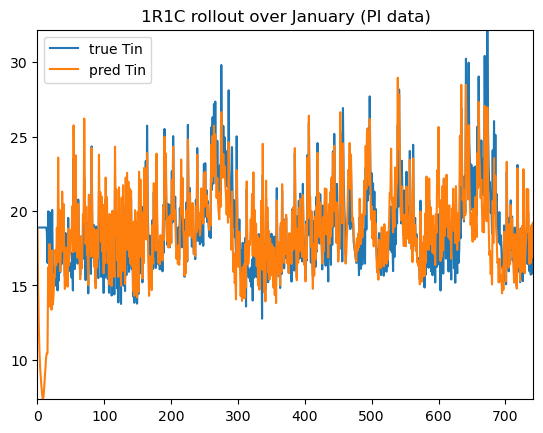

In [17]:
def rollout(T0, Tout, u, Sol, a,b,g,s,c):
    Tpred = np.zeros_like(Tout)
    Tpred[0] = T0
    for k in range(len(Tout)-1):
        Tpred[k+1] = a*Tpred[k] + b*Tout[k] + g*u[k] + s*Sol[k] + c
    return Tpred

Tpred = rollout(Tin[0], Tout, u, Sol, a,b,g,s,c)
rmse = np.sqrt(np.mean((Tpred - Tin)**2))
print("Rollout RMSE (°C):", rmse)

import matplotlib.pyplot as plt
plt.figure()
plt.plot(Tin, label="true Tin")
plt.plot(Tpred, label="pred Tin")
plt.legend()
plt.title("1R1C rollout over January (PI data)")
plt.show()


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

COP(Tout) = 1.8623 + 0.0298 * Tout
RC parameters
A   = 0.6273779571056366
Bd0 = 0.27648005
Bd1 = 0.07763091
Bd2 = 0.00049581984
Bu  = 7.614564
Power proxy: P_hvac ~= 0.5265 * u


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat


******************************************************************************
This program contains Ipopt, a library for large-scale nonlinear optimization.
 Ipopt is released as open source code under the Eclipse Public License (EPL).
         For more information visit https://github.com/coin-or/Ipopt
******************************************************************************

This is Ipopt version 3.14.11, running with linear solver MUMPS 5.4.1.

Number of nonzeros in equality constraint Jacobian...:       73
Number of nonzeros in inequality constraint Jacobian.:       96
Number of nonzeros in Lagrangian Hessian.............:       49

Total number of variables............................:       97
                     variables with only lower bounds:       48
                variables with lower and upper bounds:       24
                     variables with only upper bounds:        0
Total number of equality constraints.................:       25
Total number of inequality c

,cost_function,value
0,all_time_peak_average,0.959088
1,annual_normalized_unserved_energy_total,0.000000
2,carbon_emissions_total,NaN
3,cost_total,NaN
4,daily_one_minus_load_factor_average,0.991484
5,daily_peak_average,1.010456
6,discomfort_cold_delta_average,0.482791
7,discomfort_cold_delta_maximum,3.204639
8,discomfort_cold_delta_minimum,0.000000
9,discomfort_cold_proportion,0.073282


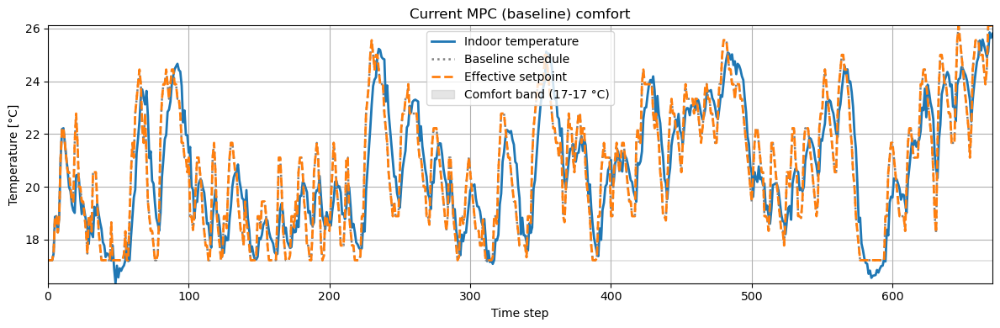


🔥 occ1_tolerant


/home/kostas/anaconda3/lib/python3.12/site-packages/do_mpc/controller/_mpc.py:894: UserWarning: rterm was not set and defaults to zero. Changes in the control inputs are not penalized. Can lead to oscillatory behavior.
  warnings.warn('rterm was not set and defaults to zero. Changes in the control inputs are not penalized. Can lead to oscillatory behavior.')
/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded 

This is Ipopt version 3.14.11, running with linear solver MUMPS 5.4.1.

Number of nonzeros in equality constraint Jacobian...:       73
Number of nonzeros in inequality constraint Jacobian.:       96
Number of nonzeros in Lagrangian Hessian.............:       49

Total number of variables............................:       97
                     variables with only lower bounds:       48
                variables with lower and upper bounds:       24
                     variables with only upper bounds:        0
Total number of equality constraints.................:       25
Total number of inequality constraints...............:       48
        inequality constraints with only lower bounds:        0
   inequality constraints with lower and upper bounds:        0
        inequality constraints with only upper bounds:       48

iter    objective    inf_pr   inf_du lg(mu)  ||d||  lg(rg) alpha_du alpha_pr  ls
   0  3.1655098e+04 1.72e+01 6.14e+01  -1.0 0.00e+00    -  0.00e+00 0.00e+00 

,cost_function,value
0,all_time_peak_average,0.903210
1,annual_normalized_unserved_energy_total,0.000000
2,carbon_emissions_total,NaN
3,cost_total,NaN
4,daily_one_minus_load_factor_average,0.990271
5,daily_peak_average,1.008701
6,discomfort_cold_delta_average,0.496658
7,discomfort_cold_delta_maximum,4.082794
8,discomfort_cold_delta_minimum,0.000000
9,discomfort_cold_proportion,0.070229


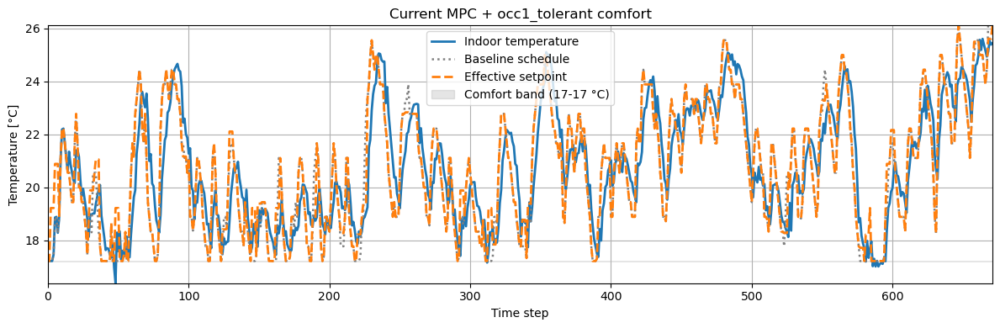


🔥 occ2_sensitive


/home/kostas/anaconda3/lib/python3.12/site-packages/do_mpc/controller/_mpc.py:894: UserWarning: rterm was not set and defaults to zero. Changes in the control inputs are not penalized. Can lead to oscillatory behavior.
  warnings.warn('rterm was not set and defaults to zero. Changes in the control inputs are not penalized. Can lead to oscillatory behavior.')
/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded 

This is Ipopt version 3.14.11, running with linear solver MUMPS 5.4.1.

Number of nonzeros in equality constraint Jacobian...:       73
Number of nonzeros in inequality constraint Jacobian.:       96
Number of nonzeros in Lagrangian Hessian.............:       49

Total number of variables............................:       97
                     variables with only lower bounds:       48
                variables with lower and upper bounds:       24
                     variables with only upper bounds:        0
Total number of equality constraints.................:       25
Total number of inequality constraints...............:       48
        inequality constraints with only lower bounds:        0
   inequality constraints with lower and upper bounds:        0
        inequality constraints with only upper bounds:       48

iter    objective    inf_pr   inf_du lg(mu)  ||d||  lg(rg) alpha_du alpha_pr  ls
   0  3.1655098e+04 1.72e+01 6.14e+01  -1.0 0.00e+00    -  0.00e+00 0.00e+00 

,cost_function,value
0,all_time_peak_average,0.994819
1,annual_normalized_unserved_energy_total,0.000000
2,carbon_emissions_total,NaN
3,cost_total,NaN
4,daily_one_minus_load_factor_average,0.987669
5,daily_peak_average,1.019420
6,discomfort_cold_delta_average,0.580712
7,discomfort_cold_delta_maximum,5.310703
8,discomfort_cold_delta_minimum,0.000000
9,discomfort_cold_proportion,0.080916


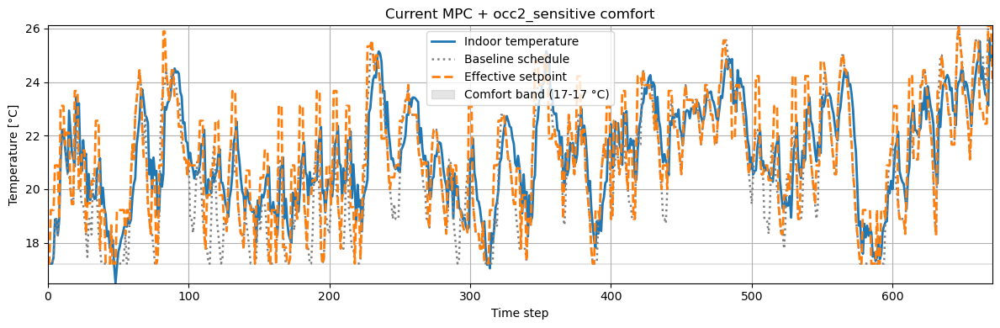


🔥 occ3_cold


/home/kostas/anaconda3/lib/python3.12/site-packages/do_mpc/controller/_mpc.py:894: UserWarning: rterm was not set and defaults to zero. Changes in the control inputs are not penalized. Can lead to oscillatory behavior.
  warnings.warn('rterm was not set and defaults to zero. Changes in the control inputs are not penalized. Can lead to oscillatory behavior.')
/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded 

This is Ipopt version 3.14.11, running with linear solver MUMPS 5.4.1.

Number of nonzeros in equality constraint Jacobian...:       73
Number of nonzeros in inequality constraint Jacobian.:       96
Number of nonzeros in Lagrangian Hessian.............:       49

Total number of variables............................:       97
                     variables with only lower bounds:       48
                variables with lower and upper bounds:       24
                     variables with only upper bounds:        0
Total number of equality constraints.................:       25
Total number of inequality constraints...............:       48
        inequality constraints with only lower bounds:        0
   inequality constraints with lower and upper bounds:        0
        inequality constraints with only upper bounds:       48

iter    objective    inf_pr   inf_du lg(mu)  ||d||  lg(rg) alpha_du alpha_pr  ls
   0  3.1655098e+04 1.72e+01 6.14e+01  -1.0 0.00e+00    -  0.00e+00 0.00e+00 

,cost_function,value
0,all_time_peak_average,0.905649
1,annual_normalized_unserved_energy_total,0.000000
2,carbon_emissions_total,NaN
3,cost_total,NaN
4,daily_one_minus_load_factor_average,0.991305
5,daily_peak_average,0.995098
6,discomfort_cold_delta_average,0.524941
7,discomfort_cold_delta_maximum,5.029358
8,discomfort_cold_delta_minimum,0.000000
9,discomfort_cold_proportion,0.074809


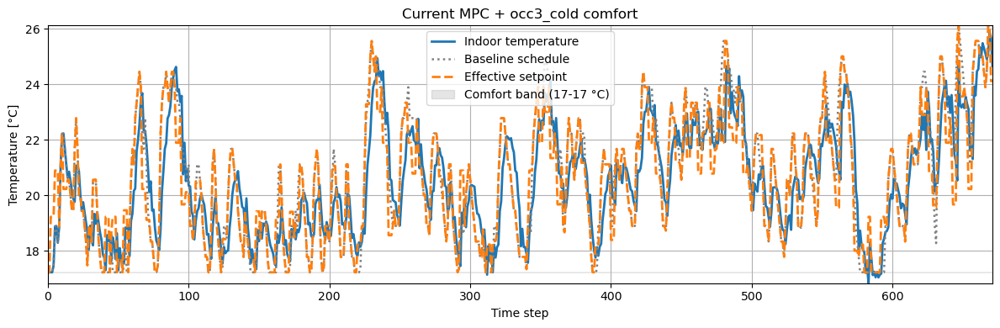


🔥 occ4_hot


/home/kostas/anaconda3/lib/python3.12/site-packages/do_mpc/controller/_mpc.py:894: UserWarning: rterm was not set and defaults to zero. Changes in the control inputs are not penalized. Can lead to oscillatory behavior.
  warnings.warn('rterm was not set and defaults to zero. Changes in the control inputs are not penalized. Can lead to oscillatory behavior.')
/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded 

This is Ipopt version 3.14.11, running with linear solver MUMPS 5.4.1.

Number of nonzeros in equality constraint Jacobian...:       73
Number of nonzeros in inequality constraint Jacobian.:       96
Number of nonzeros in Lagrangian Hessian.............:       49

Total number of variables............................:       97
                     variables with only lower bounds:       48
                variables with lower and upper bounds:       24
                     variables with only upper bounds:        0
Total number of equality constraints.................:       25
Total number of inequality constraints...............:       48
        inequality constraints with only lower bounds:        0
   inequality constraints with lower and upper bounds:        0
        inequality constraints with only upper bounds:       48

iter    objective    inf_pr   inf_du lg(mu)  ||d||  lg(rg) alpha_du alpha_pr  ls
   0  3.1655098e+04 1.72e+01 6.14e+01  -1.0 0.00e+00    -  0.00e+00 0.00e+00 

,cost_function,value
0,all_time_peak_average,0.891063
1,annual_normalized_unserved_energy_total,0.000000
2,carbon_emissions_total,NaN
3,cost_total,NaN
4,daily_one_minus_load_factor_average,0.988082
5,daily_peak_average,1.033107
6,discomfort_cold_delta_average,0.541974
7,discomfort_cold_delta_maximum,4.926163
8,discomfort_cold_delta_minimum,0.000000
9,discomfort_cold_proportion,0.071756


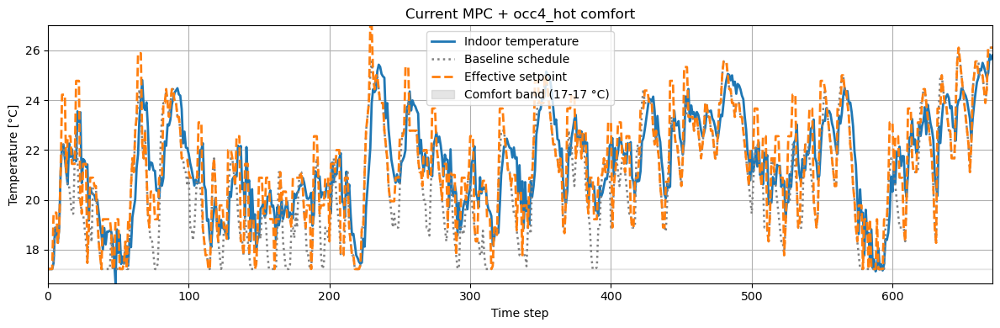

,occupant,override_count,electricity_consumption_total,discomfort_proportion,discomfort_cold_proportion,discomfort_hot_proportion,daily_peak_average
0,baseline,0,1.006405,0.116031,0.073282,0.042748,1.010456
1,occ1_tolerant,31,1.008504,0.109924,0.070229,0.039695,1.008701
2,occ2_sensitive,103,1.030204,0.224427,0.080916,0.143511,1.019420
3,occ3_cold,66,0.992806,0.083969,0.074809,0.009160,0.995098
4,occ4_hot,99,1.038029,0.287023,0.071756,0.215267,1.033107


In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.linear_model import LinearRegression, Ridge
import casadi as ca
import do_mpc
import gymnasium as gym
from copy import deepcopy

# ============================================================
# 0. PREPARE DATA AND FIT SIMPLE RC + POWER PROXY FROM JANUARY
# ============================================================
env = make_env()
obs, _ = env.reset()

data = np.load("january_pi_dataset.npz")

X = data["states"]
U = data["actions"]
Xp = data["next_states"]

X = X[:, 0, :]
Xp = Xp[:, 0, :]

U = np.array(U)
if U.ndim == 3:
    u = U[:, 0, 0]
elif U.ndim == 2:
    u = U[:, 0]
else:
    u = U

obs_names = env.buildings[0].active_observations
def idx(name):
    return obs_names.index(name)

i_tin = idx("indoor_dry_bulb_temperature")
i_tout = idx("outdoor_dry_bulb_temperature")
i_sol = idx("direct_solar_irradiance")
i_q = idx("heating_demand")
i_p = idx("heating_electricity_consumption")

Tin = X[:, i_tin]
Tin_next = Xp[:, i_tin]
Tout = X[:, i_tout]
Sol = X[:, i_sol]
Q = X[:, i_q]
P = X[:, i_p]

# TODO addressed below:
# 1. keep the current MPC as a baseline
# 2. add a second MPC that trades off energy cost and comfort
# 3. report CityLearn KPIs and plot comfort for both runs

# ============================================================
# 1. FIT COP(Tout)
# ============================================================
mask = P > 0.1
COP = Q[mask] / P[mask]
Tout_valid = Tout[mask]

cop_reg = LinearRegression()
cop_reg.fit(Tout_valid.reshape(-1, 1), COP)

cop_a = float(cop_reg.intercept_)
cop_b = float(cop_reg.coef_[0])

print(f"COP(Tout) = {cop_a:.4f} + {cop_b:.4f} * Tout")

# ============================================================
# 2. FIT RC MODEL
# ============================================================
Tm = float(Tin.mean())
COP_all = np.clip(cop_a + cop_b * Tout, 0.5, 6.0)
dT = Tin_next - Tin

Phi = np.column_stack([
    Tin,
    np.full_like(Tin, Tm),
    Tout,
    Sol,
    COP_all * u,
])

ridge = Ridge(alpha=1e-3, fit_intercept=False)
ridge.fit(Phi, dT)

alpha, Bd0, Bd1, Bd2, Bu = ridge.coef_
A = 1.0 + alpha

print("RC parameters")
print("A   =", A)
print("Bd0 =", Bd0)
print("Bd1 =", Bd1)
print("Bd2 =", Bd2)
print("Bu  =", Bu)

# Electricity proxy used in the energy-cost MPC:
# P_hvac[k] ~= power_per_unit_u * u[k]
power_mask = u > 1e-3
power_per_unit_u = float(np.dot(u[power_mask], P[power_mask]) / np.dot(u[power_mask], u[power_mask]))
print(f"Power proxy: P_hvac ~= {power_per_unit_u:.4f} * u")

# ============================================================
# 3. COMMON FORECAST/ENV SETTINGS
# ============================================================
i_tout_p = [idx(f"outdoor_dry_bulb_temperature_predicted_{h}") for h in [1, 2, 3]]
i_sol_p = [idx(f"direct_solar_irradiance_predicted_{h}") for h in [1, 2, 3]]
i_tmin = idx("indoor_dry_bulb_temperature_heating_set_point")
i_tmax = idx("indoor_dry_bulb_temperature_cooling_set_point")

SIMULATION_START_TIME_STEP = 744
SIMULATION_END_TIME_STEP = 1415

def set_experiment_seed(seed):
    seed = int(seed)
    np.random.seed(seed)
    random.seed(seed)
    return seed



class OccupantComfortReward(ComfortReward):

    def calculate(self, observations):
        reward_list = []

        for o in observations:
            if 'override_setpoint' in o:
                o['indoor_dry_bulb_temperature_heating_set_point'] = o['override_setpoint']

            r = super().calculate([o])[0]
            reward_list.append(r)

        if self.central_agent:
            return [sum(reward_list)]
        else:
            return reward_list


class Occupant:

    def __init__(self, T_pref, b, max_prob=0.4, duration=3):
        self.T_pref = T_pref
        self.b = b
        self.max_prob = max_prob
        self.duration = duration

        self.override_timer = 0
        self.override_setpoint = None
        self.last_override_started = False

    def prob_increase(self, Tin):
        d = max(0, self.T_pref - Tin)
        return min(0.002 * np.exp(self.b * d), self.max_prob)

    def prob_decrease(self, Tin):
        d = max(0, Tin - self.T_pref)
        return min(0.002 * np.exp(self.b * d), self.max_prob)

    def override_delta(self, p_override):
        if p_override < 0.2:
            return 0.5
        if p_override < 0.4:
            return 1.0
        return 2.0

    def clear_override(self):
        self.override_timer = 0
        self.override_setpoint = None
        self.last_override_started = False

    def step(self, Tin, scheduled_Tsp, occupied=True):
        self.last_override_started = False

        if not occupied:
            self.clear_override()
            return scheduled_Tsp

        if self.override_timer > 0:
            self.override_timer -= 1
            return self.override_setpoint

        p_inc = self.prob_increase(Tin)
        p_dec = self.prob_decrease(Tin)
        r = np.random.rand()

        if r < p_inc:
            new_sp = scheduled_Tsp + self.override_delta(p_inc)
        elif r < p_inc + p_dec:
            new_sp = scheduled_Tsp - self.override_delta(p_dec)
        else:
            self.override_setpoint = None
            return scheduled_Tsp

        self.override_setpoint = new_sp
        self.override_timer = max(self.duration - 1, 0)
        self.last_override_started = True
        return new_sp


class OccupantWrapper(gym.Wrapper):

    def __init__(self, env, occupant):
        super().__init__(env)
        self.occupant = occupant

    def reset(self, **kwargs):
        obs, info = self.env.reset(**kwargs)
        self.occupant.override_timer = 0
        self.occupant.override_setpoint = None
        self.occupant.last_override_started = False
        self.override_count = 0
        b = self.env.unwrapped.buildings[0]
        self.effective_setpoints = [float(b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point[b.time_step])]
        self.baseline_setpoints = [float(b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point_without_control[b.time_step])]
        return obs, info

    def step(self, action):
        b = self.env.unwrapped.buildings[0]
        current_ix = b.time_step

        Tin = float(b.energy_simulation.indoor_dry_bulb_temperature[current_ix])
        next_ix = min(current_ix + 1, len(b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point) - 1)
        occupied_next = float(b.energy_simulation.occupant_count[next_ix]) > 0.0
        scheduled_next_Tsp = float(
            b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point_without_control[next_ix]
        )

        if occupied_next:
            new_Tsp = self.occupant.step(Tin, scheduled_next_Tsp, occupied=True)
        else:
            new_Tsp = self.occupant.step(Tin, scheduled_next_Tsp, occupied=False)
        if self.occupant.last_override_started:
            self.override_count += 1

        b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point[next_ix] = new_Tsp

        obs, reward, terminated, truncated, info = self.env.step(action)

        current_effective_sp = float(
            b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point[b.time_step]
        )
        current_baseline_sp = float(
            b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point_without_control[b.time_step]
        )
        self.effective_setpoints.append(current_effective_sp)
        self.baseline_setpoints.append(current_baseline_sp)

        return obs, reward, terminated, truncated, info


def plot_comfort_with_setpoints(env, building_idx=0, T_low=20.0, T_high=24.0, title=None):
    b = env.unwrapped.buildings[building_idx]
    T_in = np.array(b.indoor_dry_bulb_temperature)

    if hasattr(env, 'effective_setpoints') and len(env.effective_setpoints) > 0:
        T_sp = np.array(env.effective_setpoints)
    else:
        T_sp = np.array(b.indoor_dry_bulb_temperature_heating_set_point)

    if hasattr(env, 'baseline_setpoints') and len(env.baseline_setpoints) > 0:
        T_sp_base = np.array(env.baseline_setpoints)
    else:
        T_sp_base = np.array(b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point_without_control[:len(T_in)])

    timesteps = np.arange(len(T_in))
    plt.figure(figsize=(12, 4))
    plt.plot(timesteps, T_in, label='Indoor temperature', linewidth=2)
    plt.plot(timesteps, T_sp_base, ':', label='Baseline schedule', linewidth=1.8, color='gray')
    plt.plot(timesteps, T_sp, '--', label='Effective setpoint', linewidth=2)
    plt.fill_between(timesteps, T_low, T_high, color='gray', alpha=0.2, label=f'Comfort band ({T_low:.0f}-{T_high:.0f} °C)')
    plt.xlabel('Time step')
    plt.ylabel('Temperature [°C]')
    plt.title(title or b.name)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


def run_february_mpc(
    controller_name,
    objective_mode="baseline",
    fixed_band=None,
    w_energy=1.0,
    w_comfort=1.0,
    lambda_u=1e-3,
    lambda_du=0.0,
    use_smooth_du=False,
    cold_penalty=1e5,
    hot_penalty=1e3,
    occupant=None,
    reward_function=None,
    seed=None,
):
    seed = int(RANDOM_SEED if seed is None else seed)
    set_experiment_seed(seed)

    model = do_mpc.model.Model('discrete')

    Tin_m = model.set_variable('_x', 'Tin')
    if use_smooth_du:
        u_prev = model.set_variable('_x', 'u_prev')

    u_m = model.set_variable('_u', 'u')

    Tout_m = model.set_variable('_tvp', 'Tout')
    Sol_m = model.set_variable('_tvp', 'Sol')
    Price_m = model.set_variable('_tvp', 'Price')
    Tsp_m = model.set_variable('_tvp', 'Tsp')
    Tmin_m = model.set_variable('_tvp', 'Tmin')
    Tmax_m = model.set_variable('_tvp', 'Tmax')
    w_est = model.set_variable('_tvp', 'w_est')

    COP_expr = cop_a + cop_b * Tout_m
    COP_expr = ca.fmin(ca.fmax(COP_expr, 0.5), 6.0)

    Tin_next_m = (
        A * Tin_m
        + Bd0 * Tm
        + Bd1 * Tout_m
        + Bd2 * Sol_m
        + Bu * COP_expr * u_m
        + w_est
    )

    Tin_occ_m = model.set_expression('Tin_occ', Tin_next_m)
    model.set_rhs('Tin', Tin_next_m)
    if use_smooth_du:
        model.set_rhs('u_prev', u_m)
    model.setup()

    mpc = do_mpc.controller.MPC(model)
    setup_mpc = {
        'n_horizon': 24,
        't_step': 1.0,
        'state_discretization': 'discrete',
        'store_full_solution': True,
    }
    mpc.set_param(**setup_mpc)

    if objective_mode == "baseline":
        Tref = Tmin_m
        stage_cost = (Tin_m - Tref) ** 2 + lambda_u * u_m ** 2
        terminal_cost = (Tin_m - Tref) ** 2
    elif objective_mode == "energy_comfort":
        energy_cost = Price_m * power_per_unit_u * u_m
        comfort_cost = (Tin_m - Tsp_m) ** 2
        smooth_cost = lambda_u * u_m ** 2
        if use_smooth_du:
            smooth_cost = smooth_cost + lambda_du * (u_m - u_prev) ** 2
        stage_cost = w_energy * energy_cost + w_comfort * comfort_cost + smooth_cost
        terminal_cost = w_comfort * comfort_cost
    else:
        raise ValueError(f"Unknown objective_mode: {objective_mode}")

    if objective_mode == "baseline" and use_smooth_du:
        stage_cost = stage_cost + lambda_du * (u_m - u_prev) ** 2

    mpc.set_objective(mterm=terminal_cost, lterm=stage_cost)

    mpc.bounds['lower', '_u', 'u'] = 0.0
    mpc.bounds['upper', '_u', 'u'] = 1.0

    mpc.set_nl_cons(
        'too_cold',
        Tmin_m - Tin_m,
        ub=0.0,
        soft_constraint=True,
        penalty_term_cons=cold_penalty,
    )
    mpc.set_nl_cons(
        'too_hot',
        Tin_m - Tmax_m,
        ub=0.0,
        soft_constraint=True,
        penalty_term_cons=hot_penalty,
    )

    N = setup_mpc['n_horizon']
    tvp_template = mpc.get_tvp_template()
    _latest = dict(
        Tout0=0.0,
        Sol0=0.0,
        Price0=0.0,
        Tsp0=20.0,
        Toutp=[0.0, 0.0, 0.0],
        Solp=[0.0, 0.0, 0.0],
        Pricep=[0.0, 0.0, 0.0],
        Tspp=[20.0, 20.0, 20.0],
        Tmin0=18.0,
        Tmax0=24.0,
        w_est=0.0,
    )

    def tvp_fun(t_now):
        Tout0 = _latest["Tout0"]
        Sol0 = _latest["Sol0"]
        Price0 = _latest["Price0"]
        Tsp0 = _latest["Tsp0"]
        Toutp = _latest["Toutp"]
        Solp = _latest["Solp"]
        Pricep = _latest["Pricep"]
        Tspp = _latest["Tspp"]
        Tmin0 = _latest["Tmin0"]
        Tmax0 = _latest["Tmax0"]
        w_est_val = _latest["w_est"]

        for k in range(N + 1):
            if k == 0:
                Tout_f, Sol_f, Price_f, Tsp_f = Tout0, Sol0, Price0, Tsp0
            elif k <= 3:
                Tout_f, Sol_f, Price_f, Tsp_f = Toutp[k - 1], Solp[k - 1], Pricep[k - 1], Tspp[k - 1]
            else:
                Tout_f, Sol_f, Price_f, Tsp_f = Toutp[-1], Solp[-1], Pricep[-1], Tspp[-1]

            tvp_template['_tvp', k, 'Tout'] = float(Tout_f)
            tvp_template['_tvp', k, 'Sol'] = float(Sol_f)
            tvp_template['_tvp', k, 'Price'] = float(Price_f)
            tvp_template['_tvp', k, 'Tsp'] = float(Tsp_f)
            tvp_template['_tvp', k, 'Tmin'] = float(Tmin0)
            tvp_template['_tvp', k, 'Tmax'] = float(Tmax0)
            tvp_template['_tvp', k, 'w_est'] = float(w_est_val)

        return tvp_template

    mpc.set_tvp_fun(tvp_fun)
    mpc.setup()

    env_kwargs = dict(
        simulation_start_time_step=SIMULATION_START_TIME_STEP,
        simulation_end_time_step=SIMULATION_END_TIME_STEP,
    )
    if reward_function is not None:
        env_kwargs['reward_function'] = reward_function

    env_kwargs['random_seed'] = seed
    env = make_env(**env_kwargs)
    if occupant is not None:
        env = OccupantWrapper(env, occupant)

    obs, _ = env.reset(seed=seed)
    building = env.unwrapped.buildings[0]
    mpc.reset_history()

    Tin_hist, Tmin_hist, Tmax_hist = [], [], []
    u_hist, price_hist = [], []

    w_est_val = 0.0
    gamma_w = 0.2

    prev_Tin = None
    prev_u = None
    prev_Tout = None
    prev_Sol = None
    last_u = 0.0

    terminated = False
    truncated = False

    while not (terminated or truncated):
        o = obs[0] if isinstance(obs, (list, tuple)) else obs

        Tin0 = float(o[i_tin])
        Tout0 = float(o[i_tout])
        Sol0 = float(o[i_sol])
        time_step = building.time_step
        Price0 = float(building.pricing.electricity_pricing[time_step])
        scheduled_setpoints = building.energy_simulation.indoor_dry_bulb_temperature_heating_set_point_without_control
        Tsp0 = float(scheduled_setpoints[time_step])

        Toutp = [float(o[j]) for j in i_tout_p]
        Solp = [float(o[j]) for j in i_sol_p]
        Pricep = [
            float(building.pricing.electricity_pricing_predicted_1[time_step]),
            float(building.pricing.electricity_pricing_predicted_2[time_step]),
            float(building.pricing.electricity_pricing_predicted_3[time_step]),
        ]
        Tspp = [
            float(scheduled_setpoints[min(time_step + h, len(scheduled_setpoints) - 1)])
            for h in [1, 2, 3]
        ]

        if fixed_band is None:
            Tmin0 = float(o[i_tmin])
            Tmax0 = float(o[i_tmax])
        else:
            Tmin0, Tmax0 = map(float, fixed_band)

        if prev_Tin is not None:
            cop_prev = np.clip(cop_a + cop_b * prev_Tout, 0.5, 6.0)
            Tin_pred = (
                A * prev_Tin
                + Bd0 * Tm
                + Bd1 * prev_Tout
                + Bd2 * prev_Sol
                + Bu * cop_prev * prev_u
                + w_est_val
            )
            err = Tin0 - Tin_pred
            w_est_val = w_est_val + gamma_w * err

        _latest.update(dict(
            Tout0=Tout0,
            Sol0=Sol0,
            Price0=Price0,
            Tsp0=Tsp0,
            Toutp=Toutp,
            Solp=Solp,
            Pricep=Pricep,
            Tspp=Tspp,
            Tmin0=Tmin0,
            Tmax0=Tmax0,
            w_est=w_est_val,
        ))

        if use_smooth_du:
            x0 = np.array([[Tin0], [last_u]])
        else:
            x0 = np.array([[Tin0]])

        u0 = float(mpc.make_step(x0))
        obs, reward, terminated, truncated, info = env.step([[u0]])

        prev_Tin = Tin0
        prev_u = u0
        prev_Tout = Tout0
        prev_Sol = Sol0
        last_u = u0

        Tin_hist.append(Tin0)
        Tmin_hist.append(Tmin0)
        Tmax_hist.append(Tmax0)
        u_hist.append(u0)
        price_hist.append(Price0)

    kpis = env.unwrapped.evaluate().copy()
    district_kpis = kpis[kpis["level"] == "district"].copy()

    override_count = int(getattr(env, 'override_count', 0))

    print(f"{controller_name} run finished")
    print(f"Overrides: {override_count}")
    display(district_kpis[["cost_function", "value"]].reset_index(drop=True))
    plot_comfort_with_setpoints(
        env,
        building_idx=0,
        T_low=float(Tmin_hist[0]),
        T_high=float(Tmax_hist[0]),
        title=f"{controller_name} comfort",
    )

    return dict(
        name=controller_name,
        env=env,
        kpis=kpis,
        district_kpis=district_kpis,
        Tin_hist=np.array(Tin_hist),
        Tmin_hist=np.array(Tmin_hist),
        Tmax_hist=np.array(Tmax_hist),
        u_hist=np.array(u_hist),
        price_hist=np.array(price_hist),
        override_count=override_count,
    )


baseline_results = run_february_mpc(
    controller_name="Current MPC (baseline)",
    objective_mode="baseline",
    fixed_band=None,
    lambda_u=1e-3,
    lambda_du=0.0,
    use_smooth_du=False,
    cold_penalty=1e5,
    hot_penalty=1e3,
    seed=int(RANDOM_SEED),
)

occupants = {
    "occ1_tolerant": Occupant(T_pref=22, b=1.2, max_prob=0.4),
    "occ2_sensitive": Occupant(T_pref=23, b=3.5, max_prob=0.4),
    "occ3_cold": Occupant(T_pref=20, b=2.5, max_prob=0.4),
    "occ4_hot": Occupant(T_pref=24, b=2.5, max_prob=0.4),
}

occupant_results = {}
for occ_idx, (name, occ) in enumerate(occupants.items(), start=1):
    print(f"\n🔥 {name}")
    occupant_results[name] = run_february_mpc(
        controller_name=f"Current MPC + {name}",
        objective_mode="baseline",
        fixed_band=None,
        lambda_u=1e-3,
        lambda_du=0.0,
        use_smooth_du=False,
        cold_penalty=1e5,
        hot_penalty=1e3,
        occupant=deepcopy(occ),
        reward_function=OccupantComfortReward,
        seed=int(RANDOM_SEED + occ_idx),
    )

summary_rows = []

def summarize_run(label, result):
    district = result['district_kpis']

    def get_kpi(cost_name):
        rows = district[district['cost_function'] == cost_name]['value']
        return float(rows.iloc[0]) if len(rows) > 0 else np.nan

    return {
        'occupant': label,
        'override_count': int(result.get('override_count', 0)),
        'electricity_consumption_total': get_kpi('electricity_consumption_total'),
        'discomfort_proportion': get_kpi('discomfort_proportion'),
        'discomfort_cold_proportion': get_kpi('discomfort_cold_proportion'),
        'discomfort_hot_proportion': get_kpi('discomfort_hot_proportion'),
        'daily_peak_average': get_kpi('daily_peak_average'),
    }

summary_rows.append(summarize_run('baseline', baseline_results))

for name, result in occupant_results.items():
    summary_rows.append(summarize_run(name, result))

occupant_summary = pd.DataFrame(summary_rows)
display(occupant_summary)



Occupant-aware MPC + occ1_tolerant


/home/kostas/anaconda3/lib/python3.12/site-packages/do_mpc/controller/_mpc.py:894: UserWarning: rterm was not set and defaults to zero. Changes in the control inputs are not penalized. Can lead to oscillatory behavior.
  warnings.warn('rterm was not set and defaults to zero. Changes in the control inputs are not penalized. Can lead to oscillatory behavior.')
/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded 

This is Ipopt version 3.14.11, running with linear solver MUMPS 5.4.1.

Number of nonzeros in equality constraint Jacobian...:       73
Number of nonzeros in inequality constraint Jacobian.:       96
Number of nonzeros in Lagrangian Hessian.............:       49

Total number of variables............................:       97
                     variables with only lower bounds:       48
                variables with lower and upper bounds:       24
                     variables with only upper bounds:        0
Total number of equality constraints.................:       25
Total number of inequality constraints...............:       48
        inequality constraints with only lower bounds:        0
   inequality constraints with lower and upper bounds:        0
        inequality constraints with only upper bounds:       48

iter    objective    inf_pr   inf_du lg(mu)  ||d||  lg(rg) alpha_du alpha_pr  ls
   0  3.1655098e+04 1.80e+01 6.14e+01  -1.0 0.00e+00    -  0.00e+00 0.00e+00 

,cost_function,value
0,all_time_peak_average,0.917868
1,annual_normalized_unserved_energy_total,0.000000
2,carbon_emissions_total,NaN
3,cost_total,NaN
4,daily_one_minus_load_factor_average,0.980956
5,daily_peak_average,1.023935
6,discomfort_cold_delta_average,0.708000
7,discomfort_cold_delta_maximum,4.681898
8,discomfort_cold_delta_minimum,0.000000
9,discomfort_cold_proportion,0.152672


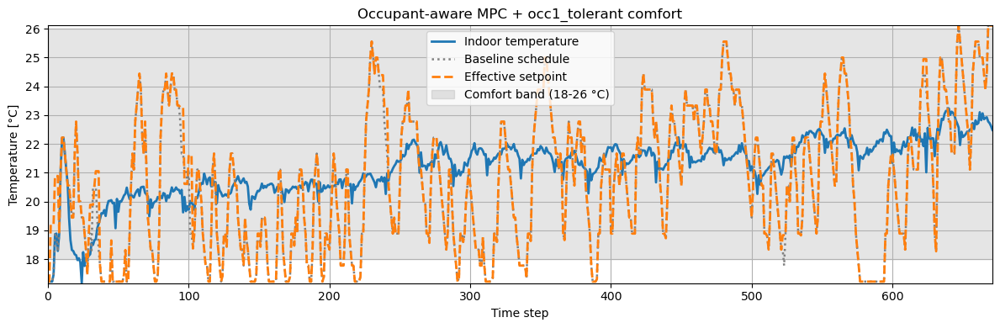

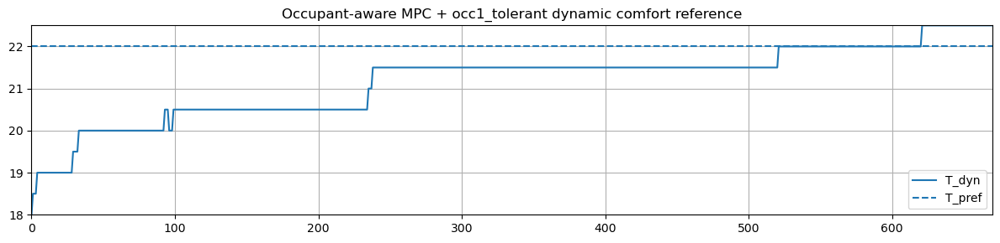


Occupant-aware MPC + occ2_sensitive


/home/kostas/anaconda3/lib/python3.12/site-packages/do_mpc/controller/_mpc.py:894: UserWarning: rterm was not set and defaults to zero. Changes in the control inputs are not penalized. Can lead to oscillatory behavior.
  warnings.warn('rterm was not set and defaults to zero. Changes in the control inputs are not penalized. Can lead to oscillatory behavior.')
/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded 

This is Ipopt version 3.14.11, running with linear solver MUMPS 5.4.1.

Number of nonzeros in equality constraint Jacobian...:       73
Number of nonzeros in inequality constraint Jacobian.:       96
Number of nonzeros in Lagrangian Hessian.............:       49

Total number of variables............................:       97
                     variables with only lower bounds:       48
                variables with lower and upper bounds:       24
                     variables with only upper bounds:        0
Total number of equality constraints.................:       25
Total number of inequality constraints...............:       48
        inequality constraints with only lower bounds:        0
   inequality constraints with lower and upper bounds:        0
        inequality constraints with only upper bounds:       48

iter    objective    inf_pr   inf_du lg(mu)  ||d||  lg(rg) alpha_du alpha_pr  ls
   0  3.1655098e+04 1.80e+01 6.14e+01  -1.0 0.00e+00    -  0.00e+00 0.00e+00 

,cost_function,value
0,all_time_peak_average,0.962025
1,annual_normalized_unserved_energy_total,0.000000
2,carbon_emissions_total,NaN
3,cost_total,NaN
4,daily_one_minus_load_factor_average,0.942607
5,daily_peak_average,1.066153
6,discomfort_cold_delta_average,0.290393
7,discomfort_cold_delta_maximum,4.365257
8,discomfort_cold_delta_minimum,0.000000
9,discomfort_cold_proportion,0.047328


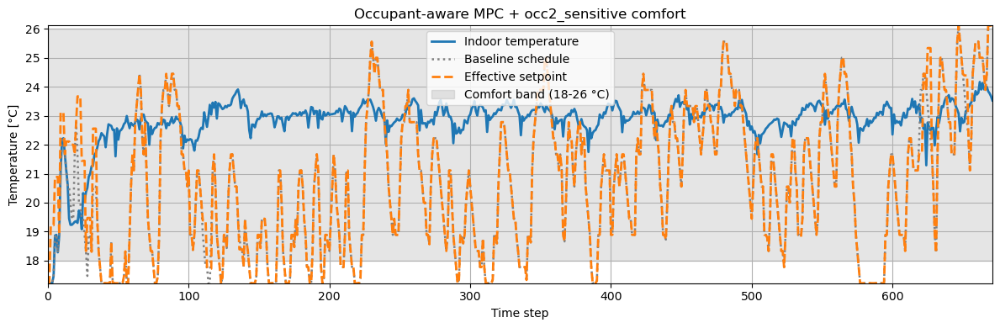

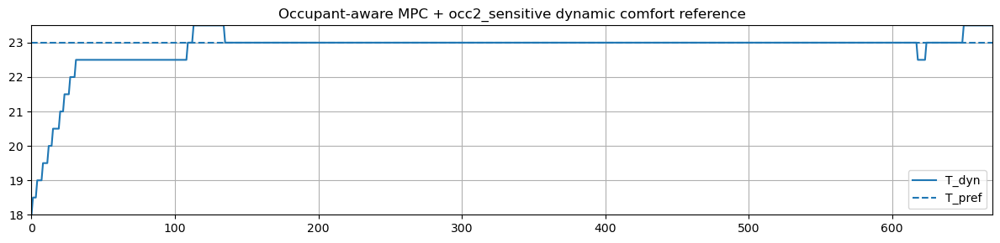


Occupant-aware MPC + occ3_cold


/home/kostas/anaconda3/lib/python3.12/site-packages/do_mpc/controller/_mpc.py:894: UserWarning: rterm was not set and defaults to zero. Changes in the control inputs are not penalized. Can lead to oscillatory behavior.
  warnings.warn('rterm was not set and defaults to zero. Changes in the control inputs are not penalized. Can lead to oscillatory behavior.')
/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded 

This is Ipopt version 3.14.11, running with linear solver MUMPS 5.4.1.

Number of nonzeros in equality constraint Jacobian...:       73
Number of nonzeros in inequality constraint Jacobian.:       96
Number of nonzeros in Lagrangian Hessian.............:       49

Total number of variables............................:       97
                     variables with only lower bounds:       48
                variables with lower and upper bounds:       24
                     variables with only upper bounds:        0
Total number of equality constraints.................:       25
Total number of inequality constraints...............:       48
        inequality constraints with only lower bounds:        0
   inequality constraints with lower and upper bounds:        0
        inequality constraints with only upper bounds:       48

iter    objective    inf_pr   inf_du lg(mu)  ||d||  lg(rg) alpha_du alpha_pr  ls
   0  3.1655098e+04 1.80e+01 6.14e+01  -1.0 0.00e+00    -  0.00e+00 0.00e+00 

,cost_function,value
0,all_time_peak_average,0.894155
1,annual_normalized_unserved_energy_total,0.000000
2,carbon_emissions_total,NaN
3,cost_total,NaN
4,daily_one_minus_load_factor_average,1.012818
5,daily_peak_average,0.993309
6,discomfort_cold_delta_average,1.356065
7,discomfort_cold_delta_maximum,6.139929
8,discomfort_cold_delta_minimum,0.000000
9,discomfort_cold_proportion,0.326718


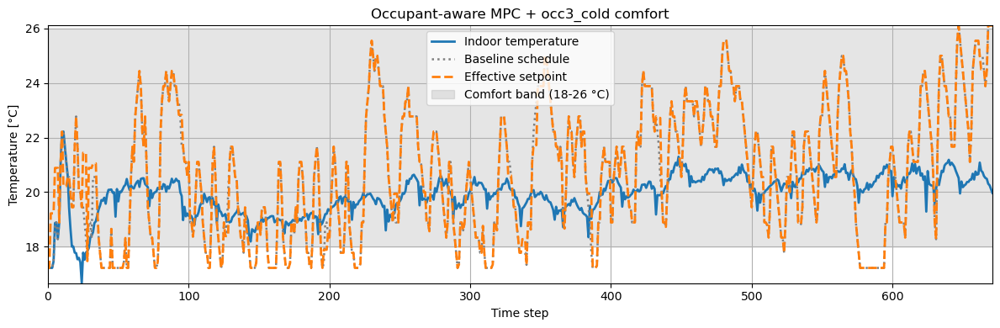

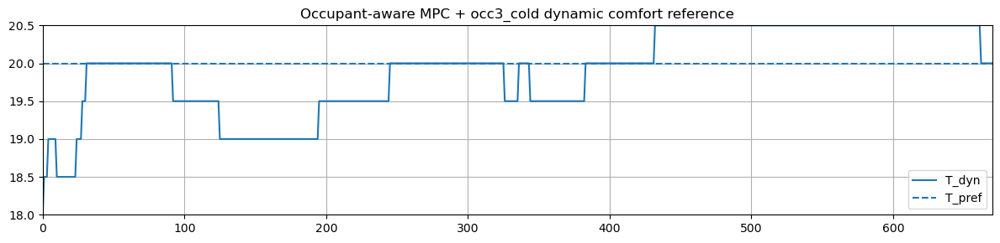


Occupant-aware MPC + occ4_hot


/home/kostas/anaconda3/lib/python3.12/site-packages/do_mpc/controller/_mpc.py:894: UserWarning: rterm was not set and defaults to zero. Changes in the control inputs are not penalized. Can lead to oscillatory behavior.
  warnings.warn('rterm was not set and defaults to zero. Changes in the control inputs are not penalized. Can lead to oscillatory behavior.')
/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded 

This is Ipopt version 3.14.11, running with linear solver MUMPS 5.4.1.

Number of nonzeros in equality constraint Jacobian...:       73
Number of nonzeros in inequality constraint Jacobian.:       96
Number of nonzeros in Lagrangian Hessian.............:       49

Total number of variables............................:       97
                     variables with only lower bounds:       48
                variables with lower and upper bounds:       24
                     variables with only upper bounds:        0
Total number of equality constraints.................:       25
Total number of inequality constraints...............:       48
        inequality constraints with only lower bounds:        0
   inequality constraints with lower and upper bounds:        0
        inequality constraints with only upper bounds:       48

iter    objective    inf_pr   inf_du lg(mu)  ||d||  lg(rg) alpha_du alpha_pr  ls
   0  3.1655098e+04 1.80e+01 6.14e+01  -1.0 0.00e+00    -  0.00e+00 0.00e+00 

,cost_function,value
0,all_time_peak_average,0.974175
1,annual_normalized_unserved_energy_total,0.000000
2,carbon_emissions_total,NaN
3,cost_total,NaN
4,daily_one_minus_load_factor_average,0.932009
5,daily_peak_average,1.080248
6,discomfort_cold_delta_average,0.190737
7,discomfort_cold_delta_maximum,5.947157
8,discomfort_cold_delta_minimum,0.000000
9,discomfort_cold_proportion,0.032061


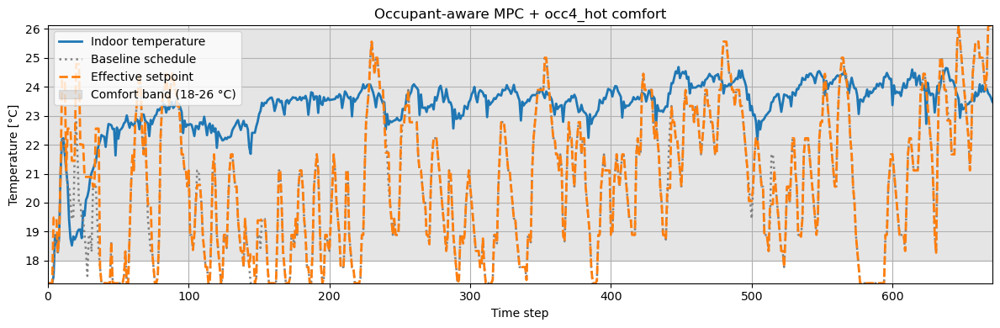

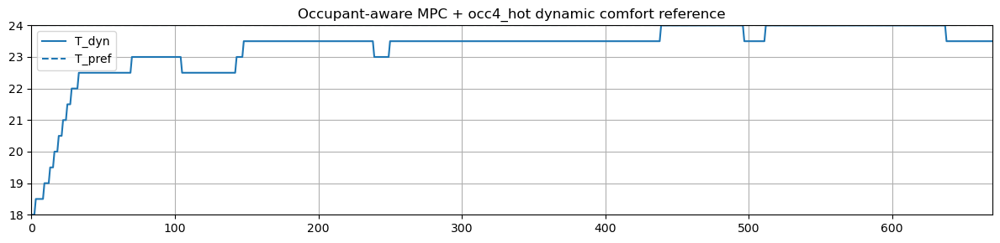

,occupant,override_count,electricity_consumption_total,discomfort_proportion,discomfort_cold_proportion,discomfort_hot_proportion,daily_peak_average
0,baseline,0,1.006405,0.116031,0.073282,0.042748,1.010456
1,occ1_tolerant,11,1.032181,0.435115,0.152672,0.282443,1.023935
2,occ2_sensitive,15,1.128236,0.560305,0.047328,0.512977,1.066153
3,occ3_cold,16,0.962648,0.427481,0.326718,0.100763,0.993309
4,occ4_hot,19,1.155693,0.618321,0.032061,0.586260,1.080248


In [19]:
# Paper-style dynamic-comfort MPC.
# Persistent T_dyn is updated only when a NEW occupant override starts:
#   warmer override  -> T_dyn += delta_up
#   cooler override  -> T_dyn -= delta_down
# Otherwise T_dyn is kept unchanged (optionally with slow drift).

OCCUPANT_AWARE_MPC_CONFIG = dict(
    fixed_band=None,
    lambda_u=1e-3,
    lambda_du=0.0,
    use_smooth_du=False,
    cold_penalty=1e5,
    hot_penalty=1e3,
    T_dyn_init_mode="schedule",   # "schedule" or "pref"
    delta_up=0.5,
    delta_down=0.5,
    drift_to_pref=0.0,            # e.g. 0.0 first, maybe later 0.01
    T_dyn_min=18.0,
    T_dyn_max=26.0,
)

class OccupantWrapper(gym.Wrapper):

    def __init__(self, env, occupant):
        super().__init__(env)
        self.occupant = occupant

    def reset(self, **kwargs):
        obs, info = self.env.reset(**kwargs)
        self.occupant.override_timer = 0
        self.occupant.override_setpoint = None
        self.occupant.last_override_started = False

        self.override_count = 0
        self.last_feedback = 0   # +1 warmer, -1 cooler, 0 none

        b = self.env.unwrapped.buildings[0]
        self.effective_setpoints = [
            float(b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point[b.time_step])
        ]
        self.baseline_setpoints = [
            float(b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point_without_control[b.time_step])
        ]
        return obs, info

    def step(self, action):
        b = self.env.unwrapped.buildings[0]
        current_ix = b.time_step

        Tin = float(b.energy_simulation.indoor_dry_bulb_temperature[current_ix])
        next_ix = min(
            current_ix + 1,
            len(b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point) - 1
        )

        occupied_next = float(b.energy_simulation.occupant_count[next_ix]) > 0.0

        scheduled_next_Tsp = float(
            b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point_without_control[next_ix]
        )

        if occupied_next:
            new_Tsp = self.occupant.step(Tin, scheduled_next_Tsp, occupied=True)
        else:
            new_Tsp = self.occupant.step(Tin, scheduled_next_Tsp, occupied=False)

        self.last_feedback = 0
        if self.occupant.last_override_started:
            self.override_count += 1
            if new_Tsp > scheduled_next_Tsp:
                self.last_feedback = +1
            elif new_Tsp < scheduled_next_Tsp:
                self.last_feedback = -1

        b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point[next_ix] = new_Tsp

        obs, reward, terminated, truncated, info = self.env.step(action)

        current_effective_sp = float(
            b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point[b.time_step]
        )
        current_baseline_sp = float(
            b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point_without_control[b.time_step]
        )
        self.effective_setpoints.append(current_effective_sp)
        self.baseline_setpoints.append(current_baseline_sp)

        return obs, reward, terminated, truncated, info


def run_february_occupant_aware_mpc(
    controller_name,
    fixed_band=None,
    lambda_u=1e-3,
    lambda_du=0.0,
    use_smooth_du=False,
    cold_penalty=1e5,
    hot_penalty=1e3,
    occupant=None,
    reward_function=None,
    seed=None,
    T_dyn_init_mode="schedule",
    delta_up=0.5,
    delta_down=0.5,
    drift_to_pref=0.0,
    T_dyn_min=18.0,
    T_dyn_max=26.0,
):
    seed = int(RANDOM_SEED if seed is None else seed)
    set_experiment_seed(seed)

    sim_occupant = deepcopy(occupant) if occupant is not None else None

    model = do_mpc.model.Model('discrete')

    Tin_m = model.set_variable('_x', 'Tin')
    if use_smooth_du:
        u_prev = model.set_variable('_x', 'u_prev')

    u_m = model.set_variable('_u', 'u')

    Tout_m = model.set_variable('_tvp', 'Tout')
    Sol_m = model.set_variable('_tvp', 'Sol')
    Tdyn_m = model.set_variable('_tvp', 'Tdyn')
    Tmin_m = model.set_variable('_tvp', 'Tmin')
    Tmax_m = model.set_variable('_tvp', 'Tmax')
    w_est = model.set_variable('_tvp', 'w_est')

    COP_expr = cop_a + cop_b * Tout_m
    COP_expr = ca.fmin(ca.fmax(COP_expr, 0.5), 6.0)

    Tin_next_m = (
        A * Tin_m
        + Bd0 * Tm
        + Bd1 * Tout_m
        + Bd2 * Sol_m
        + Bu * COP_expr * u_m
        + w_est
    )

    model.set_rhs('Tin', Tin_next_m)
    if use_smooth_du:
        model.set_rhs('u_prev', u_m)
    model.setup()

    mpc = do_mpc.controller.MPC(model)
    setup_mpc = {
        'n_horizon': 24,
        't_step': 1.0,
        'state_discretization': 'discrete',
        'store_full_solution': True,
    }
    mpc.set_param(**setup_mpc)

    stage_cost = (Tin_m - Tdyn_m) ** 2 + lambda_u * u_m ** 2
    terminal_cost = (Tin_m - Tdyn_m) ** 2

    if use_smooth_du:
        stage_cost = stage_cost + lambda_du * (u_m - u_prev) ** 2

    mpc.set_objective(mterm=terminal_cost, lterm=stage_cost)

    mpc.bounds['lower', '_u', 'u'] = 0.0
    mpc.bounds['upper', '_u', 'u'] = 1.0

    # Keep loose bounds by default to avoid setpoint-derived constraints dominating.
    mpc.set_nl_cons(
        'too_cold',
        Tmin_m - Tin_m,
        ub=0.0,
        soft_constraint=True,
        penalty_term_cons=cold_penalty,
    )
    mpc.set_nl_cons(
        'too_hot',
        Tin_m - Tmax_m,
        ub=0.0,
        soft_constraint=True,
        penalty_term_cons=hot_penalty,
    )

    N = setup_mpc['n_horizon']
    tvp_template = mpc.get_tvp_template()
    _latest = dict(
        Tout0=0.0,
        Sol0=0.0,
        Tdyn0=21.0,
        Toutp=[0.0, 0.0, 0.0],
        Solp=[0.0, 0.0, 0.0],
        Tmin0=18.0,
        Tmax0=26.0,
        w_est=0.0,
    )

    def tvp_fun(t_now):
        Tout0 = _latest['Tout0']
        Sol0 = _latest['Sol0']
        Tdyn0 = _latest['Tdyn0']
        Toutp = _latest['Toutp']
        Solp = _latest['Solp']
        Tmin0 = _latest['Tmin0']
        Tmax0 = _latest['Tmax0']
        w_est_val = _latest['w_est']

        for k in range(N + 1):
            if k == 0:
                Tout_f, Sol_f = Tout0, Sol0
            elif k <= 3:
                Tout_f, Sol_f = Toutp[k - 1], Solp[k - 1]
            else:
                Tout_f, Sol_f = Toutp[-1], Solp[-1]

            tvp_template['_tvp', k, 'Tout'] = float(Tout_f)
            tvp_template['_tvp', k, 'Sol'] = float(Sol_f)
            tvp_template['_tvp', k, 'Tdyn'] = float(Tdyn0)
            tvp_template['_tvp', k, 'Tmin'] = float(Tmin0)
            tvp_template['_tvp', k, 'Tmax'] = float(Tmax0)
            tvp_template['_tvp', k, 'w_est'] = float(w_est_val)

        return tvp_template

    mpc.set_tvp_fun(tvp_fun)
    mpc.setup()

    env_kwargs = dict(
        simulation_start_time_step=SIMULATION_START_TIME_STEP,
        simulation_end_time_step=SIMULATION_END_TIME_STEP,
        random_seed=seed,
    )
    if reward_function is not None:
        env_kwargs['reward_function'] = reward_function

    env = make_env(**env_kwargs)
    if sim_occupant is not None:
        env = OccupantWrapper(env, sim_occupant)

    obs, _ = env.reset(seed=seed)
    building = env.unwrapped.buildings[0]
    mpc.reset_history()

    # Initialize persistent dynamic comfort reference.
    time_step = building.time_step
    scheduled_setpoints = building.energy_simulation.indoor_dry_bulb_temperature_heating_set_point_without_control
    scheduled0 = float(scheduled_setpoints[time_step])

    if occupant is None:
        T_dyn = scheduled0
    elif T_dyn_init_mode == "schedule":
        T_dyn = scheduled0
    elif T_dyn_init_mode == "pref":
        T_dyn = float(occupant.T_pref)
    else:
        raise ValueError("T_dyn_init_mode must be 'schedule' or 'pref'")

    T_dyn_hist = []
    Tin_hist, Tmin_hist, Tmax_hist = [], [], []
    u_hist, price_hist = [], []

    w_est_val = 0.0
    gamma_w = 0.2

    prev_Tin = None
    prev_u = None
    prev_Tout = None
    prev_Sol = None
    last_u = 0.0

    terminated = False
    truncated = False

    while not (terminated or truncated):
        o = obs[0] if isinstance(obs, (list, tuple)) else obs

        Tin0 = float(o[i_tin])
        Tout0 = float(o[i_tout])
        Sol0 = float(o[i_sol])
        time_step = building.time_step
        Price0 = float(building.pricing.electricity_pricing[time_step])

        Toutp = [float(o[j]) for j in i_tout_p]
        Solp = [float(o[j]) for j in i_sol_p]

        if fixed_band is None:
            Tmin0, Tmax0 = 18.0, 26.0
        else:
            Tmin0, Tmax0 = map(float, fixed_band)

        if prev_Tin is not None:
            cop_prev = np.clip(cop_a + cop_b * prev_Tout, 0.5, 6.0)
            Tin_pred = (
                A * prev_Tin
                + Bd0 * Tm
                + Bd1 * prev_Tout
                + Bd2 * prev_Sol
                + Bu * cop_prev * prev_u
                + w_est_val
            )
            err = Tin0 - Tin_pred
            w_est_val = w_est_val + gamma_w * err

        if occupant is not None and drift_to_pref > 0.0:
            T_dyn = (1.0 - drift_to_pref) * T_dyn + drift_to_pref * float(occupant.T_pref)

        _latest.update(dict(
            Tout0=Tout0,
            Sol0=Sol0,
            Tdyn0=T_dyn,
            Toutp=Toutp,
            Solp=Solp,
            Tmin0=Tmin0,
            Tmax0=Tmax0,
            w_est=w_est_val,
        ))

        if use_smooth_du:
            x0 = np.array([[Tin0], [last_u]])
        else:
            x0 = np.array([[Tin0]])

        u0 = float(mpc.make_step(x0))
        obs, reward, terminated, truncated, info = env.step([[u0]])

        # Paper-style update: only update T_dyn when a NEW feedback event arrives.
        feedback = int(getattr(env, 'last_feedback', 0))
        if feedback > 0:
            T_dyn += float(delta_up)
        elif feedback < 0:
            T_dyn -= float(delta_down)

        T_dyn = float(np.clip(T_dyn, T_dyn_min, T_dyn_max))

        prev_Tin = Tin0
        prev_u = u0
        prev_Tout = Tout0
        prev_Sol = Sol0
        last_u = u0

        T_dyn_hist.append(T_dyn)
        Tin_hist.append(Tin0)
        Tmin_hist.append(Tmin0)
        Tmax_hist.append(Tmax0)
        u_hist.append(u0)
        price_hist.append(Price0)

    kpis = env.unwrapped.evaluate().copy()
    district_kpis = kpis[kpis['level'] == 'district'].copy()
    override_count = int(getattr(env, 'override_count', 0))

    print(f"{controller_name} run finished")
    print(f"Overrides: {override_count}")
    display(district_kpis[['cost_function', 'value']].reset_index(drop=True))

    plot_comfort_with_setpoints(
        env,
        building_idx=0,
        T_low=float(Tmin_hist[0]),
        T_high=float(Tmax_hist[0]),
        title=f"{controller_name} comfort",
    )

    plt.figure(figsize=(12, 3))
    plt.plot(T_dyn_hist, label='T_dyn')
    if occupant is not None:
        plt.axhline(float(occupant.T_pref), linestyle='--', label='T_pref')
    plt.legend()
    plt.grid(True)
    plt.title(f"{controller_name} dynamic comfort reference")
    plt.tight_layout()
    plt.show()

    return dict(
        name=controller_name,
        env=env,
        kpis=kpis,
        district_kpis=district_kpis,
        Tin_hist=np.array(Tin_hist),
        Tmin_hist=np.array(Tmin_hist),
        Tmax_hist=np.array(Tmax_hist),
        u_hist=np.array(u_hist),
        price_hist=np.array(price_hist),
        T_dyn_hist=np.array(T_dyn_hist),
        override_count=override_count,
    )


occupant_aware_baseline_results = baseline_results

occupant_aware_results = {}
for occ_idx, (name, occ) in enumerate(occupants.items(), start=1):
    print(f"\nOccupant-aware MPC + {name}")
    occupant_aware_results[name] = run_february_occupant_aware_mpc(
        controller_name=f'Occupant-aware MPC + {name}',
        occupant=deepcopy(occ),
        reward_function=OccupantComfortReward,
        seed=int(RANDOM_SEED + occ_idx),
        **OCCUPANT_AWARE_MPC_CONFIG,
    )

occupant_aware_summary_rows = [summarize_run('baseline', occupant_aware_baseline_results)]
for name, result in occupant_aware_results.items():
    occupant_aware_summary_rows.append(summarize_run(name, result))

occupant_aware_summary = pd.DataFrame(occupant_aware_summary_rows)
display(occupant_aware_summary)

In [20]:
from collections import deque
import numpy as np
from citylearn.reward_function import RewardFunction


class OccupantFeedbackReward(RewardFunction):
    """
    Paper-aligned reward:

        C_t^total = beta * C_t^discomfort + (1 - beta) * C_t^energy
        r_t = - C_t^total

    Discomfort cost:
        - if occupied and current feedback != 0:
              weighted sum of recent |feedback| values
        - if occupied and current feedback == 0:
              -epsilon
        - if unoccupied:
              0

    Notes:
    - The current feedback is appended BEFORE computing discomfort,
      so a fresh override is penalized immediately.
    - Energy cost is implemented using HVAC electricity consumption,
      normalized by nominal power, since that is what is directly
      available in CityLearn observations.
    """

    def __init__(
        self,
        env_metadata,
        beta=0.75,
        epsilon=0.05,
        feedback_horizon=4,
    ):
        super().__init__(env_metadata)
        self.beta = float(beta)
        self.epsilon = float(epsilon)
        self.feedback_horizon = int(feedback_horizon)

        self.feedback_buffers = []
        self.energy_scales = []

        if self.env_metadata is not None and self.env_metadata.get('buildings') is not None:
            self.reset()

    def reset(self):
        n_buildings = 0 if self.env_metadata is None else len(self.env_metadata['buildings'])

        self.feedback_buffers = [
            deque([0.0] * self.feedback_horizon, maxlen=self.feedback_horizon)
            for _ in range(n_buildings)
        ]

        self.energy_scales = []
        for i in range(n_buildings):
            building_metadata = self.env_metadata['buildings'][i]
            nominal_power = float(
                building_metadata.get('heating_device', {}).get('nominal_power', 0.0) or 0.0
            )
            self.energy_scales.append(max(nominal_power, 1.0))

    def _discomfort_from_buffer(self, feedback_buffer):
        """
        Paper weighting:
            w_i = e - exp(i / h_f)

        We apply it from most recent to oldest.
        If h_f = H and the buffer contains:
            [oldest, ..., newest]
        then newest gets lag = 0, next lag = 1, etc.
        """
        discomfort = 0.0
        H = max(1, self.feedback_horizon)

        for lag, feedback in enumerate(reversed(feedback_buffer)):
            weight = np.e - np.exp((lag + 1) / H)
            discomfort += weight * abs(float(feedback))

        return float(discomfort)

    def calculate(self, observations):
        if len(self.feedback_buffers) != len(observations):
            self.reset()

        reward_list = []

        for i, o in enumerate(observations):
            feedback = float(o.get('occupant_feedback_signal', 0.0))
            occupied = float(o.get('occupant_count', 0.0)) > 0.0

            # Append first so current override is penalized immediately.
            self.feedback_buffers[i].append(feedback)

            if occupied and abs(feedback) > 0.0:
                discomfort_cost = self._discomfort_from_buffer(self.feedback_buffers[i])
            elif occupied:
                discomfort_cost = -self.epsilon
            else:
                discomfort_cost = 0.0

            hvac_electricity = max(
                float(
                    o.get(
                        'heating_electricity_consumption',
                        o.get('net_electricity_consumption', 0.0)
                    )
                ),
                0.0,
            )

            energy_scale = self.energy_scales[i] if i < len(self.energy_scales) else 1.0
            energy_cost = hvac_electricity / max(energy_scale, 1.0)

            total_cost = self.beta * discomfort_cost + (1.0 - self.beta) * energy_cost
            reward_list.append(-total_cost)

        if self.central_agent:
            return [sum(reward_list)]

        return reward_list

In [21]:
# Rebuild January PI occupant envs for RC + MLE fitting.
# This recreates the env-side occupant_feedback_signal arrays expected by the fitting megacell.

import gymnasium as gym
from copy import deepcopy
import numpy as np
import pandas as pd

JAN_OCC_START = 0
JAN_OCC_N_STEPS = int(np.load("january_pi_dataset_occ1.npz")["states"].shape[0])
JAN_OCC_END = JAN_OCC_START + JAN_OCC_N_STEPS - 1  # inclusive

class JanuaryOccupantReplayWrapper(gym.Wrapper):

    def __init__(self, env, occupant):
        super().__init__(env)
        self.occupant = occupant

        # passthrough attrs expected by PITemperatureController / CityLearn agents
        self.observation_names = env.observation_names
        self.action_names = env.unwrapped.action_names
        self.observation_space = env.observation_space
        self.action_space = env.action_space

    def reset(self, **kwargs):
        obs, info = self.env.reset(**kwargs)
        self.occupant.override_timer = 0
        self.occupant.override_setpoint = None
        self.occupant.last_override_started = False
        self.override_count = 0

        b = self.env.unwrapped.buildings[0]
        n_steps = len(b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point)
        b.energy_simulation.occupant_feedback_signal = np.zeros(n_steps, dtype=np.float32)

        self.effective_setpoints = [
            float(b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point[b.time_step])
        ]
        self.baseline_setpoints = [
            float(b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point_without_control[b.time_step])
        ]
        return obs, info

    def step(self, action):
        b = self.env.unwrapped.buildings[0]
        current_ix = b.time_step
        Tin = float(b.energy_simulation.indoor_dry_bulb_temperature[current_ix])

        next_ix = min(
            current_ix + 1,
            len(b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point) - 1,
        )
        occupied_next = float(b.energy_simulation.occupant_count[next_ix]) > 0.0
        scheduled_next_Tsp = float(
            b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point_without_control[next_ix]
        )

        if occupied_next:
            new_Tsp = self.occupant.step(Tin, scheduled_next_Tsp, occupied=True)
        else:
            new_Tsp = self.occupant.step(Tin, scheduled_next_Tsp, occupied=False)

        feedback_signal = 0.0
        if self.occupant.last_override_started:
            self.override_count += 1
            if new_Tsp > scheduled_next_Tsp:
                feedback_signal = 1.0
            elif new_Tsp < scheduled_next_Tsp:
                feedback_signal = -1.0

        b.energy_simulation.occupant_feedback_signal[next_ix] = feedback_signal
        b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point[next_ix] = new_Tsp

        obs, reward, terminated, truncated, info = self.env.step(action)

        current_effective_sp = float(
            b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point[b.time_step]
        )
        current_baseline_sp = float(
            b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point_without_control[b.time_step]
        )
        self.effective_setpoints.append(current_effective_sp)
        self.baseline_setpoints.append(current_baseline_sp)

        return obs, reward, terminated, truncated, info


january_occupant_specs = {
    "occ1": Occupant(T_pref=22.0, b=1.2, max_prob=0.4, duration=3),
    "occ2": Occupant(T_pref=23.0, b=3.5, max_prob=0.4, duration=3),
    "occ3": Occupant(T_pref=20.0, b=2.5, max_prob=0.4, duration=3),
    "occ4": Occupant(T_pref=24.0, b=2.5, max_prob=0.4, duration=3),
}

january_occ_envs = {}
january_occ_replay_summary_rows = []

for occ_idx, (short_name, occupant) in enumerate(january_occupant_specs.items(), start=1):
    seed_local = int(RANDOM_SEED + occ_idx)
    set_experiment_seed(seed_local)

    env_pi_occ = make_env(
        reward_function=OccupantFeedbackReward,
        simulation_start_time_step=JAN_OCC_START,
        simulation_end_time_step=JAN_OCC_END,
        random_seed=seed_local,
    )
    env_pi_occ = JanuaryOccupantReplayWrapper(env_pi_occ, deepcopy(occupant))
    pi_controller_occ = PITemperatureController(env_pi_occ)

    env_pi_occ, _ = collect_trajectories(
        env_pi_occ,
        pi_controller_occ,
        seed=seed_local,
    )

    january_occ_envs[short_name] = env_pi_occ

    feedback_signal = np.asarray(
        env_pi_occ.unwrapped.buildings[0].energy_simulation.occupant_feedback_signal,
        dtype=np.float32,
    ).reshape(-1)

    january_occ_replay_summary_rows.append({
        "occupant": short_name,
        "seed": seed_local,
        "override_count": int(getattr(env_pi_occ, "override_count", 0)),
        "feedback_events": int(np.count_nonzero(feedback_signal)),
        "simulation_start_time_step": int(JAN_OCC_START),
        "simulation_end_time_step": int(JAN_OCC_END),
        "n_steps": int(JAN_OCC_N_STEPS),
    })

january_occ_replay_summary = pd.DataFrame(january_occ_replay_summary_rows)
display(january_occ_replay_summary)

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

,occupant,seed,override_count,feedback_events,simulation_start_time_step,simulation_end_time_step,n_steps
0,occ1,50,92,92,0,742,743
1,occ2,51,157,157,0,742,743
2,occ3,52,123,123,0,742,743
3,occ4,53,146,146,0,742,743



🔥 Fitting from same dataset: occ1 -> january_pi_dataset_occ1.npz

🔥 Fitting from same dataset: occ2 -> january_pi_dataset_occ2.npz

🔥 Fitting from same dataset: occ3 -> january_pi_dataset_occ3.npz

🔥 Fitting from same dataset: occ4 -> january_pi_dataset_occ4.npz

RC fit summary (same-dataset fit per occupant)


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

,occupant,n_samples,cop_a,cop_b,Tm,A,Bd0,Bd1,Bd2,Bu,power_per_unit_u
0,occ1,743,1.859638,0.029317,19.170244,0.528298,0.389248,0.102046,0.000592,6.705178,1.664336
1,occ2,743,1.861192,0.029508,19.862545,0.472442,0.446492,0.109331,0.000340,6.719630,1.275122
2,occ3,743,1.857079,0.029200,19.177162,0.513381,0.404604,0.101954,0.000330,6.724893,1.495230
3,occ4,743,1.861753,0.029702,19.933075,0.498705,0.415768,0.098713,0.000234,6.936015,0.938083



Occupant MLE summary (ELIGIBLE timesteps only)


,occupant,n_samples_fit,n_events_up,n_events_down,n_none,T_pref_hat,b_hat,max_prob_fixed,duration_fixed,nll,event_direction_acc,success,message,T_pref_true,b_true,T_pref_abs_error,b_abs_error
0,occ1,536,85,7,444,21.861014,1.198849,0.4,3,191.972614,0.989130,True,CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH,22.0,1.2,0.138986,0.001151
1,occ2,412,146,10,256,23.035896,3.451184,0.4,3,258.615825,0.987179,True,CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH,23.0,3.5,0.035896,0.048816
2,occ3,475,92,31,352,19.957358,2.618482,0.4,3,236.893473,0.991870,True,CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH,20.0,2.5,0.042642,0.118482
3,occ4,430,141,4,285,23.909844,2.570147,0.4,3,256.713093,1.000000,True,CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH,24.0,2.5,0.090156,0.070147


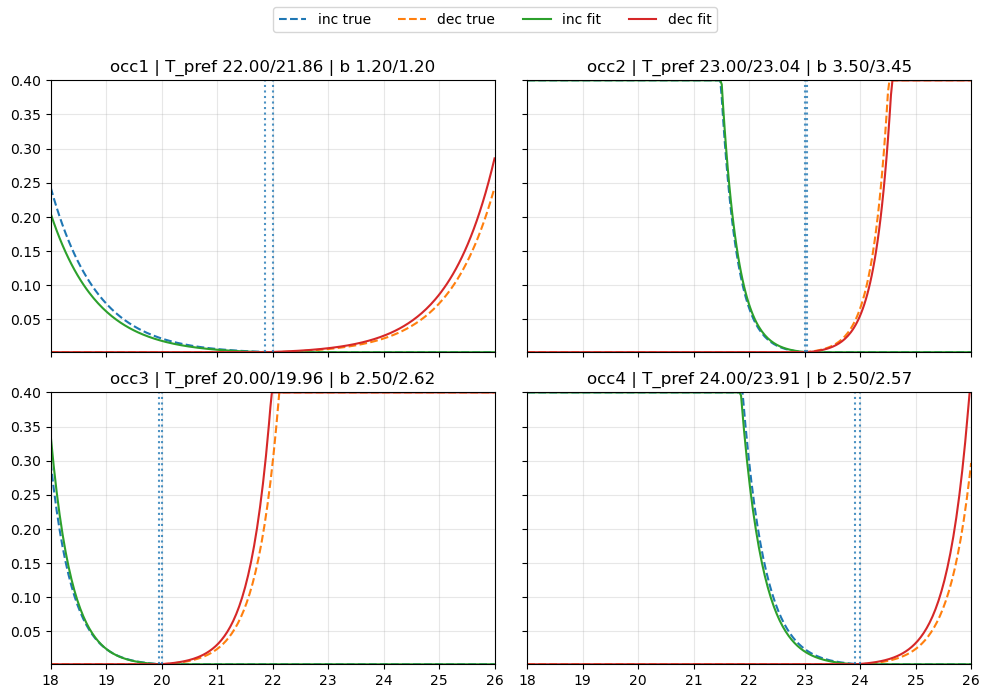


Event preview (eligible rows only)


,occupant,Tin_mean,Tin_std,n_up,n_down,n_none,n_fit_rows
0,occ1,19.141947,2.777688,85,7,444,536
1,occ2,19.661671,2.704407,146,10,256,412
2,occ3,18.937975,2.805416,92,31,352,475
3,occ4,19.655600,2.786247,141,4,285,430



Fitted occupant objects for February experiments:
occ1_tolerant: T_pref=21.8610, b=1.1988, max_prob=0.4, duration=3
occ2_sensitive: T_pref=23.0359, b=3.4512, max_prob=0.4, duration=3
occ3_cold: T_pref=19.9574, b=2.6185, max_prob=0.4, duration=3
occ4_hot: T_pref=23.9098, b=2.5701, max_prob=0.4, duration=3


In [22]:
# ============================================================
# FIXED MEGACELL: OCCUPANT-SPECIFIC RC FIT + OCCUPANT MLE FIT
# IMPORTANT FIX:
#   Occupant MLE is fitted only on DECISION-ELIGIBLE timesteps.
#   Persistence timesteps after a new override are excluded.
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.linear_model import LinearRegression, Ridge
from scipy.optimize import minimize

# ------------------------------------------------------------
# CONFIG
# ------------------------------------------------------------
occ_dataset_paths = {
    "occ1": "january_pi_dataset_occ1.npz",
    "occ2": "january_pi_dataset_occ2.npz",
    "occ3": "january_pi_dataset_occ3.npz",
    "occ4": "january_pi_dataset_occ4.npz",
}

occ_true_params = {
    "occ1": {"T_pref_true": 22.0, "b_true": 1.2},
    "occ2": {"T_pref_true": 23.0, "b_true": 3.5},
    "occ3": {"T_pref_true": 20.0, "b_true": 2.5},
    "occ4": {"T_pref_true": 24.0, "b_true": 2.5},
}

FIXED_MAX_PROB = 0.4
FIXED_DURATION = 3

# ------------------------------------------------------------
# COMMON OBSERVATION INDICES
# ------------------------------------------------------------
env_fit = make_env()
obs_fit, _ = env_fit.reset()

obs_names_fit = env_fit.buildings[0].active_observations
def idx_fit(name):
    return obs_names_fit.index(name)

i_tin_fit  = idx_fit("indoor_dry_bulb_temperature")
i_tout_fit = idx_fit("outdoor_dry_bulb_temperature")
i_sol_fit  = idx_fit("direct_solar_irradiance")
i_q_fit    = idx_fit("heating_demand")
i_p_fit    = idx_fit("heating_electricity_consumption")

# ------------------------------------------------------------
# HELPERS: LOAD DATASET
# ------------------------------------------------------------
def load_occ_dataset(npz_path):
    d = np.load(npz_path)
    X = d["states"]
    U = d["actions"]
    Xp = d["next_states"]

    if X.ndim == 3:
        X = X[:, 0, :]
    if Xp.ndim == 3:
        Xp = Xp[:, 0, :]

    U = np.array(U)
    if U.ndim == 3:
        u = U[:, 0, 0]
    elif U.ndim == 2:
        u = U[:, 0]
    else:
        u = U

    return X, u, Xp

# ------------------------------------------------------------
# HELPERS: RC FIT
# ------------------------------------------------------------
def fit_rc_from_occ_dataset(npz_path):
    X, u, Xp = load_occ_dataset(npz_path)

    Tin = X[:, i_tin_fit]
    Tin_next = Xp[:, i_tin_fit]
    Tout = X[:, i_tout_fit]
    Sol = X[:, i_sol_fit]
    Q = X[:, i_q_fit]
    P = X[:, i_p_fit]

    mask = P > 0.1
    COP = Q[mask] / P[mask]
    Tout_valid = Tout[mask]

    cop_reg = LinearRegression()
    cop_reg.fit(Tout_valid.reshape(-1, 1), COP)

    cop_a = float(cop_reg.intercept_)
    cop_b = float(cop_reg.coef_[0])

    Tm = float(Tin.mean())
    COP_all = np.clip(cop_a + cop_b * Tout, 0.5, 6.0)
    dT = Tin_next - Tin

    Phi = np.column_stack([
        Tin,
        np.full_like(Tin, Tm),
        Tout,
        Sol,
        COP_all * u,
    ])

    ridge = Ridge(alpha=1e-3, fit_intercept=False)
    ridge.fit(Phi, dT)

    alpha, Bd0, Bd1, Bd2, Bu = ridge.coef_
    A = 1.0 + alpha

    power_mask = u > 1e-3
    power_per_unit_u = float(
        np.dot(u[power_mask], P[power_mask]) / np.dot(u[power_mask], u[power_mask])
    )

    return {
        "cop_a": cop_a,
        "cop_b": cop_b,
        "Tm": Tm,
        "A": float(A),
        "Bd0": float(Bd0),
        "Bd1": float(Bd1),
        "Bd2": float(Bd2),
        "Bu": float(Bu),
        "power_per_unit_u": float(power_per_unit_u),
        "n_samples": int(len(Tin)),
    }

# ------------------------------------------------------------
# HELPERS: OCCUPANT MLE
# ------------------------------------------------------------
def get_occ_feedback_from_env(env_occ):
    bld = env_occ.unwrapped.buildings[0]
    feedback = np.asarray(
        bld.energy_simulation.occupant_feedback_signal,
        dtype=np.float32
    ).reshape(-1)
    occ_count = np.asarray(
        bld.energy_simulation.occupant_count,
        dtype=np.float32
    ).reshape(-1)
    return feedback, occ_count

def build_decision_eligibility_mask(feedback, occupied, duration=FIXED_DURATION):
    """
    On the aligned decision timeline:
      y[t] = feedback produced for next step.

    If y[t] != 0, a new override started.
    Then the next duration-1 decisions are forced persistence and should be excluded.
    """
    n = len(feedback)
    eligible = np.asarray(occupied, dtype=bool).copy()

    persistence_horizon = max(int(duration) - 1, 0)
    event_idx = np.where(np.asarray(feedback) != 0)[0]

    for t in event_idx:
        for k in range(1, persistence_horizon + 1):
            if t + k < n:
                eligible[t + k] = False

    return eligible

def extract_occ_fit_table(short_name, npz_path, env_occ, duration=FIXED_DURATION):
    """
    Correct alignment:
      feedback[next_ix] is generated from decision using Tin[current_ix].

    So we fit:
      Tin_decision[t] = Tin[t]
      y_decision[t]   = feedback[t+1]

    We also exclude forced-persistence labels after a new override start.
    """
    X, u, Xp = load_occ_dataset(npz_path)
    Tin_full = X[:, i_tin_fit].astype(np.float64)

    feedback_full, occ_count_full = get_occ_feedback_from_env(env_occ)

    n_raw = min(len(Tin_full), len(feedback_full), len(occ_count_full))

    Tin_full = Tin_full[:n_raw]
    feedback_full = feedback_full[:n_raw]
    occ_count_full = occ_count_full[:n_raw]

    # Decision-time alignment:
    # decision at time t produces feedback stored at time t+1
    Tin_decision = Tin_full[:-1]
    feedback_decision = feedback_full[1:]
    occupied_decision = occ_count_full[1:] > 0.0

    y = np.zeros(len(Tin_decision), dtype=np.int64)
    y[feedback_decision > 0] = 1
    y[feedback_decision < 0] = -1

    eligible = build_decision_eligibility_mask(
        feedback=feedback_decision,
        occupied=occupied_decision,
        duration=duration,
    )

    keep = eligible & np.isfinite(Tin_decision)

    df = pd.DataFrame({
        "occupant": short_name,
        "Tin": Tin_decision[keep],
        "y": y[keep],
        "occupied": occupied_decision[keep].astype(int),
        "eligible": eligible[keep].astype(int),
    }).reset_index(drop=True)

    return df

def p_inc_model(Tin, T_pref, b, max_prob=FIXED_MAX_PROB):
    delta = np.maximum(T_pref - Tin, 0.0)
    return np.minimum(0.002 * np.exp(b * delta), max_prob)

def p_dec_model(Tin, T_pref, b, max_prob=FIXED_MAX_PROB):
    delta = np.maximum(Tin - T_pref, 0.0)
    return np.minimum(0.002 * np.exp(b * delta), max_prob)

def neg_loglik_theta(theta, Tin, y, max_prob=FIXED_MAX_PROB):
    T_pref, b = theta

    if not (18.0 <= T_pref <= 26.0 and 0.05 <= b <= 10.0):
        return 1e12

    p_inc = p_inc_model(Tin, T_pref, b, max_prob=max_prob)
    p_dec = p_dec_model(Tin, T_pref, b, max_prob=max_prob)
    p_none = 1.0 - p_inc - p_dec

    eps = 1e-9
    p_inc = np.clip(p_inc, eps, 1.0)
    p_dec = np.clip(p_dec, eps, 1.0)
    p_none = np.clip(p_none, eps, 1.0)

    ll = np.zeros_like(Tin, dtype=np.float64)
    ll[y == 1]  = np.log(p_inc[y == 1])
    ll[y == -1] = np.log(p_dec[y == -1])
    ll[y == 0]  = np.log(p_none[y == 0])

    return -float(np.sum(ll))

def fit_occ_params_mle(df_occ, short_name):
    Tin = df_occ["Tin"].to_numpy(dtype=np.float64)
    y = df_occ["y"].to_numpy(dtype=np.int64)

    # Better initialization near the true comfort region
    true_guess = occ_true_params.get(short_name, {"T_pref_true": 22.0, "b_true": 2.0})
    x0 = np.array([true_guess["T_pref_true"], true_guess["b_true"]], dtype=np.float64)

    # Bound T_pref to a realistic indoor comfort range
    bounds = [(18.0, 26.0), (0.05, 10.0)]

    res = minimize(
        neg_loglik_theta,
        x0=x0,
        args=(Tin, y, FIXED_MAX_PROB),
        method="L-BFGS-B",
        bounds=bounds,
    )

    T_pref_hat, b_hat = res.x
    nll = float(res.fun)

    p_inc_hat = p_inc_model(Tin, T_pref_hat, b_hat, FIXED_MAX_PROB)
    p_dec_hat = p_dec_model(Tin, T_pref_hat, b_hat, FIXED_MAX_PROB)

    y_pred = np.zeros_like(y)
    y_pred[p_inc_hat > p_dec_hat] = 1
    y_pred[p_dec_hat > p_inc_hat] = -1

    event_mask = y != 0
    event_acc = float((y_pred[event_mask] == y[event_mask]).mean()) if event_mask.any() else np.nan

    out = {
        "occupant": short_name,
        "n_samples_fit": int(len(Tin)),
        "n_events_up": int((y == 1).sum()),
        "n_events_down": int((y == -1).sum()),
        "n_none": int((y == 0).sum()),
        "T_pref_hat": float(T_pref_hat),
        "b_hat": float(b_hat),
        "max_prob_fixed": float(FIXED_MAX_PROB),
        "duration_fixed": int(FIXED_DURATION),
        "nll": nll,
        "event_direction_acc": event_acc,
        "success": bool(res.success),
        "message": str(res.message),
    }

    out.update(occ_true_params.get(short_name, {}))
    if "T_pref_true" in out:
        out["T_pref_abs_error"] = abs(out["T_pref_hat"] - out["T_pref_true"])
    if "b_true" in out:
        out["b_abs_error"] = abs(out["b_hat"] - out["b_true"])

    return out, res
# ------------------------------------------------------------
# FIT EVERYTHING OCCUPANT-BY-OCCUPANT
# ------------------------------------------------------------
rc_fit_rows = []
occ_fit_rows = []
occ_fit_tables = {}
occ_fit_results = {}
fitted_occupants = {}
fitted_rc_params = {}

for short_name, npz_path in occ_dataset_paths.items():
    print(f"\n🔥 Fitting from same dataset: {short_name} -> {npz_path}")

    if short_name not in january_occ_envs:
        raise RuntimeError(
            f"{short_name} not found in january_occ_envs. "
            "Run the January PI occupant rollout rebuild cell first."
        )

    rc_row = fit_rc_from_occ_dataset(npz_path)
    rc_row["occupant"] = short_name
    rc_fit_rows.append(rc_row)
    fitted_rc_params[short_name] = rc_row

    df_occ = extract_occ_fit_table(
        short_name=short_name,
        npz_path=npz_path,
        env_occ=january_occ_envs[short_name],
        duration=FIXED_DURATION,
    )
    occ_fit_tables[short_name] = df_occ

    fit_row, fit_res = fit_occ_params_mle(df_occ, short_name)
    occ_fit_rows.append(fit_row)
    occ_fit_results[short_name] = fit_res

    fitted_occupants[short_name] = Occupant(
        T_pref=float(fit_row["T_pref_hat"]),
        b=float(fit_row["b_hat"]),
        max_prob=FIXED_MAX_PROB,
        duration=FIXED_DURATION,
    )

# ------------------------------------------------------------
# SUMMARIES
# ------------------------------------------------------------
rc_fit_summary = pd.DataFrame(rc_fit_rows)[[
    "occupant", "n_samples", "cop_a", "cop_b", "Tm", "A", "Bd0", "Bd1", "Bd2", "Bu", "power_per_unit_u"
]]
print("\nRC fit summary (same-dataset fit per occupant)")
display(rc_fit_summary)

occupant_fit_summary = pd.DataFrame(occ_fit_rows)
print("\nOccupant MLE summary (ELIGIBLE timesteps only)")
display(occupant_fit_summary)

# ------------------------------------------------------------
# DIAGNOSTIC PLOTS
# ------------------------------------------------------------
T_grid = np.linspace(18.0, 26.0, 300)

fig, axs = plt.subplots(2, 2, figsize=(10, 7), sharex=True, sharey=True)
axs = axs.flatten()

for ax, short_name in zip(axs, ["occ1", "occ2", "occ3", "occ4"]):
    fit_row = occupant_fit_summary[occupant_fit_summary["occupant"] == short_name].iloc[0]

    T_pref_hat = float(fit_row["T_pref_hat"])
    b_hat = float(fit_row["b_hat"])
    T_pref_true = float(fit_row["T_pref_true"])
    b_true = float(fit_row["b_true"])

    p_inc_true = p_inc_model(T_grid, T_pref_true, b_true, FIXED_MAX_PROB)
    p_dec_true = p_dec_model(T_grid, T_pref_true, b_true, FIXED_MAX_PROB)

    p_inc_hat = p_inc_model(T_grid, T_pref_hat, b_hat, FIXED_MAX_PROB)
    p_dec_hat = p_dec_model(T_grid, T_pref_hat, b_hat, FIXED_MAX_PROB)

    ax.plot(T_grid, p_inc_true, "--", label="inc true")
    ax.plot(T_grid, p_dec_true, "--", label="dec true")
    ax.plot(T_grid, p_inc_hat, label="inc fit")
    ax.plot(T_grid, p_dec_hat, label="dec fit")

    ax.axvline(T_pref_true, linestyle=":", alpha=0.8)
    ax.axvline(T_pref_hat, linestyle=":", alpha=0.8)

    ax.set_title(
        f"{short_name} | T_pref {T_pref_true:.2f}/{T_pref_hat:.2f} | "
        f"b {b_true:.2f}/{b_hat:.2f}"
    )
    ax.grid(True, alpha=0.3)

handles, labels = axs[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=4)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

event_preview_rows = []
for short_name, df_occ in occ_fit_tables.items():
    event_preview_rows.append({
        "occupant": short_name,
        "Tin_mean": float(df_occ["Tin"].mean()),
        "Tin_std": float(df_occ["Tin"].std()),
        "n_up": int((df_occ["y"] == 1).sum()),
        "n_down": int((df_occ["y"] == -1).sum()),
        "n_none": int((df_occ["y"] == 0).sum()),
        "n_fit_rows": int(len(df_occ)),
    })

event_preview = pd.DataFrame(event_preview_rows)
print("\nEvent preview (eligible rows only)")
display(event_preview)

# ------------------------------------------------------------
# NAME MAPPING FOR FEBRUARY EXPERIMENTS
# ------------------------------------------------------------
fitted_occupants_named = {
    "occ1_tolerant": fitted_occupants["occ1"],
    "occ2_sensitive": fitted_occupants["occ2"],
    "occ3_cold": fitted_occupants["occ3"],
    "occ4_hot": fitted_occupants["occ4"],
}

fitted_rc_params_named = {
    "occ1_tolerant": fitted_rc_params["occ1"],
    "occ2_sensitive": fitted_rc_params["occ2"],
    "occ3_cold": fitted_rc_params["occ3"],
    "occ4_hot": fitted_rc_params["occ4"],
}

print("\nFitted occupant objects for February experiments:")
for name, occ in fitted_occupants_named.items():
    print(
        f"{name}: T_pref={occ.T_pref:.4f}, b={occ.b:.4f}, "
        f"max_prob={occ.max_prob}, duration={occ.duration}"
    )


Constant-T_pref MPC + FITTED occ1_tolerant


/home/kostas/anaconda3/lib/python3.12/site-packages/do_mpc/controller/_mpc.py:894: UserWarning: rterm was not set and defaults to zero. Changes in the control inputs are not penalized. Can lead to oscillatory behavior.
  warnings.warn('rterm was not set and defaults to zero. Changes in the control inputs are not penalized. Can lead to oscillatory behavior.')
/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded 

This is Ipopt version 3.14.11, running with linear solver MUMPS 5.4.1.

Number of nonzeros in equality constraint Jacobian...:       73
Number of nonzeros in inequality constraint Jacobian.:        0
Number of nonzeros in Lagrangian Hessian.............:       49

Total number of variables............................:       49
                     variables with only lower bounds:        0
                variables with lower and upper bounds:       24
                     variables with only upper bounds:        0
Total number of equality constraints.................:       25
Total number of inequality constraints...............:        0
        inequality constraints with only lower bounds:        0
   inequality constraints with lower and upper bounds:        0
        inequality constraints with only upper bounds:        0

iter    objective    inf_pr   inf_du lg(mu)  ||d||  lg(rg) alpha_du alpha_pr  ls
   0  1.1947598e+04 1.72e+01 4.37e+01  -1.0 0.00e+00    -  0.00e+00 0.00e+00 

,cost_function,value
0,all_time_peak_average,0.941374
1,annual_normalized_unserved_energy_total,0.000000
2,carbon_emissions_total,NaN
3,cost_total,NaN
4,daily_one_minus_load_factor_average,0.965708
5,daily_peak_average,1.037479
6,discomfort_cold_delta_average,0.488731
7,discomfort_cold_delta_maximum,4.263193
8,discomfort_cold_delta_minimum,0.000000
9,discomfort_cold_proportion,0.082443


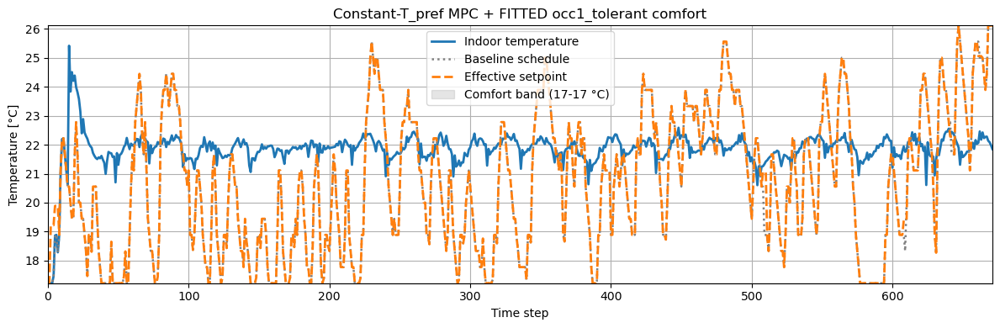


Constant-T_pref MPC + FITTED occ2_sensitive


/home/kostas/anaconda3/lib/python3.12/site-packages/do_mpc/controller/_mpc.py:894: UserWarning: rterm was not set and defaults to zero. Changes in the control inputs are not penalized. Can lead to oscillatory behavior.
  warnings.warn('rterm was not set and defaults to zero. Changes in the control inputs are not penalized. Can lead to oscillatory behavior.')
/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded 

This is Ipopt version 3.14.11, running with linear solver MUMPS 5.4.1.

Number of nonzeros in equality constraint Jacobian...:       73
Number of nonzeros in inequality constraint Jacobian.:        0
Number of nonzeros in Lagrangian Hessian.............:       49

Total number of variables............................:       49
                     variables with only lower bounds:        0
                variables with lower and upper bounds:       24
                     variables with only upper bounds:        0
Total number of equality constraints.................:       25
Total number of inequality constraints...............:        0
        inequality constraints with only lower bounds:        0
   inequality constraints with lower and upper bounds:        0
        inequality constraints with only upper bounds:        0

iter    objective    inf_pr   inf_du lg(mu)  ||d||  lg(rg) alpha_du alpha_pr  ls
   0  1.3266312e+04 1.72e+01 4.60e+01  -1.0 0.00e+00    -  0.00e+00 0.00e+00 

,cost_function,value
0,all_time_peak_average,0.962939
1,annual_normalized_unserved_energy_total,0.000000
2,carbon_emissions_total,NaN
3,cost_total,NaN
4,daily_one_minus_load_factor_average,0.936687
5,daily_peak_average,1.066467
6,discomfort_cold_delta_average,0.214390
7,discomfort_cold_delta_maximum,4.130005
8,discomfort_cold_delta_minimum,0.000000
9,discomfort_cold_proportion,0.030534


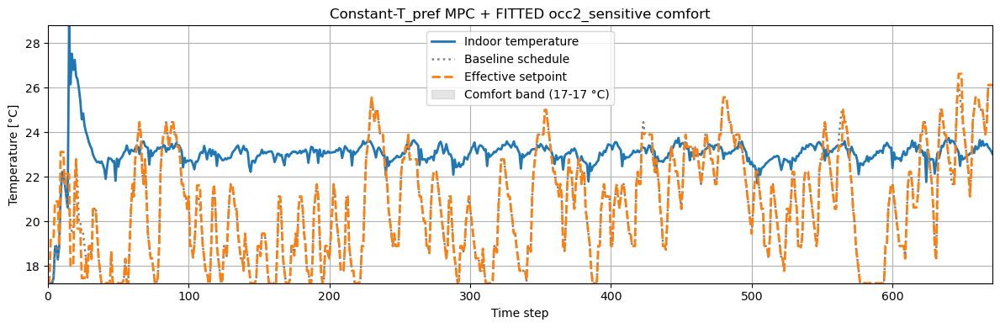


Constant-T_pref MPC + FITTED occ3_cold


/home/kostas/anaconda3/lib/python3.12/site-packages/do_mpc/controller/_mpc.py:894: UserWarning: rterm was not set and defaults to zero. Changes in the control inputs are not penalized. Can lead to oscillatory behavior.
  warnings.warn('rterm was not set and defaults to zero. Changes in the control inputs are not penalized. Can lead to oscillatory behavior.')
/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded 

This is Ipopt version 3.14.11, running with linear solver MUMPS 5.4.1.

Number of nonzeros in equality constraint Jacobian...:       73
Number of nonzeros in inequality constraint Jacobian.:        0
Number of nonzeros in Lagrangian Hessian.............:       49

Total number of variables............................:       49
                     variables with only lower bounds:        0
                variables with lower and upper bounds:       24
                     variables with only upper bounds:        0
Total number of equality constraints.................:       25
Total number of inequality constraints...............:        0
        inequality constraints with only lower bounds:        0
   inequality constraints with lower and upper bounds:        0
        inequality constraints with only upper bounds:        0

iter    objective    inf_pr   inf_du lg(mu)  ||d||  lg(rg) alpha_du alpha_pr  ls
   0  9.9574036e+03 1.72e+01 3.99e+01  -1.0 0.00e+00    -  0.00e+00 0.00e+00 

,cost_function,value
0,all_time_peak_average,0.908964
1,annual_normalized_unserved_energy_total,0.000000
2,carbon_emissions_total,NaN
3,cost_total,NaN
4,daily_one_minus_load_factor_average,1.013092
5,daily_peak_average,0.993740
6,discomfort_cold_delta_average,1.351911
7,discomfort_cold_delta_maximum,6.168259
8,discomfort_cold_delta_minimum,0.000000
9,discomfort_cold_proportion,0.320611


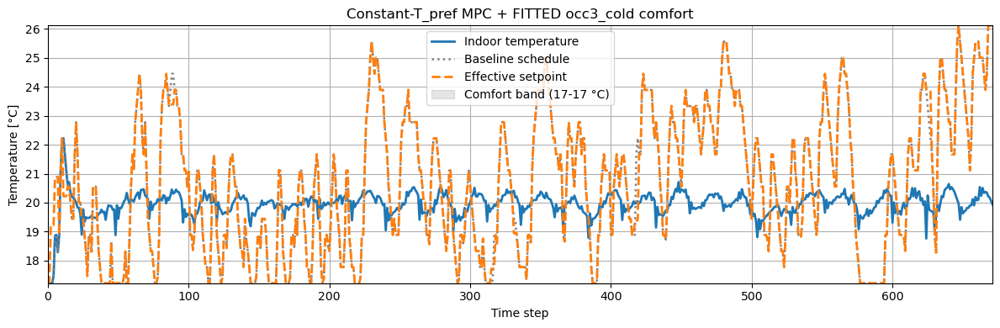


Constant-T_pref MPC + FITTED occ4_hot


/home/kostas/anaconda3/lib/python3.12/site-packages/do_mpc/controller/_mpc.py:894: UserWarning: rterm was not set and defaults to zero. Changes in the control inputs are not penalized. Can lead to oscillatory behavior.
  warnings.warn('rterm was not set and defaults to zero. Changes in the control inputs are not penalized. Can lead to oscillatory behavior.')
/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded 

This is Ipopt version 3.14.11, running with linear solver MUMPS 5.4.1.

Number of nonzeros in equality constraint Jacobian...:       73
Number of nonzeros in inequality constraint Jacobian.:        0
Number of nonzeros in Lagrangian Hessian.............:       49

Total number of variables............................:       49
                     variables with only lower bounds:        0
                variables with lower and upper bounds:       24
                     variables with only upper bounds:        0
Total number of equality constraints.................:       25
Total number of inequality constraints...............:        0
        inequality constraints with only lower bounds:        0
   inequality constraints with lower and upper bounds:        0
        inequality constraints with only upper bounds:        0

iter    objective    inf_pr   inf_du lg(mu)  ||d||  lg(rg) alpha_du alpha_pr  ls
   0  1.4292017e+04 1.72e+01 4.78e+01  -1.0 0.00e+00    -  0.00e+00 0.00e+00 

,cost_function,value
0,all_time_peak_average,0.979720
1,annual_normalized_unserved_energy_total,0.000000
2,carbon_emissions_total,NaN
3,cost_total,NaN
4,daily_one_minus_load_factor_average,0.914707
5,daily_peak_average,1.089466
6,discomfort_cold_delta_average,0.086991
7,discomfort_cold_delta_maximum,2.551050
8,discomfort_cold_delta_minimum,0.000000
9,discomfort_cold_proportion,0.012214


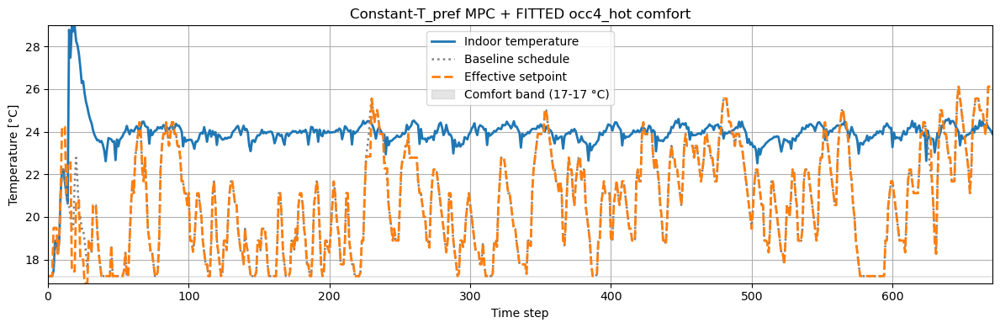

,occupant,target_temperature,override_count,electricity_consumption_total,discomfort_proportion,discomfort_cold_proportion,discomfort_hot_proportion,daily_peak_average
0,occ1_tolerant,21.861014,6,1.069681,0.482443,0.082443,0.400000,1.037479
1,occ2_sensitive,23.035896,13,1.136754,0.569466,0.030534,0.538931,1.066467
2,occ3_cold,19.957358,8,0.965303,0.464122,0.320611,0.143511,0.993740
3,occ4_hot,23.909844,10,1.189277,0.671756,0.012214,0.659542,1.089466


In [24]:
# Constant-T_pref MPC experiments with FITTED occupants.
# Same MPC, same logic, same hyperparameters as your original cell.

CONSTANT_PREF_MPC_CONFIG = dict(
    fixed_band=None,
    lambda_u=1e-3,
    lambda_du=0.0,
    use_smooth_du=False,
    cold_penalty=1e5,
    hot_penalty=1e3,
)


def run_february_constant_pref_mpc(
    controller_name,
    occupant,
    fixed_band=None,
    lambda_u=1e-3,
    lambda_du=0.0,
    use_smooth_du=False,
    cold_penalty=1e5,
    hot_penalty=1e3,
    reward_function=None,
    seed=None,
):
    seed = int(RANDOM_SEED if seed is None else seed)
    set_experiment_seed(seed)

    target_temperature = float(occupant.T_pref)
    sim_occupant = deepcopy(occupant)

    model = do_mpc.model.Model('discrete')

    Tin_m = model.set_variable('_x', 'Tin')
    if use_smooth_du:
        u_prev = model.set_variable('_x', 'u_prev')

    u_m = model.set_variable('_u', 'u')

    Tout_m = model.set_variable('_tvp', 'Tout')
    Sol_m = model.set_variable('_tvp', 'Sol')
    Tpref_m = model.set_variable('_tvp', 'Tpref')
    Tmin_m = model.set_variable('_tvp', 'Tmin')
    Tmax_m = model.set_variable('_tvp', 'Tmax')
    w_est = model.set_variable('_tvp', 'w_est')

    COP_expr = cop_a + cop_b * Tout_m
    COP_expr = ca.fmin(ca.fmax(COP_expr, 0.5), 6.0)

    Tin_next_m = (
        A * Tin_m
        + Bd0 * Tm
        + Bd1 * Tout_m
        + Bd2 * Sol_m
        + Bu * COP_expr * u_m
        + w_est
    )

    model.set_rhs('Tin', Tin_next_m)
    if use_smooth_du:
        model.set_rhs('u_prev', u_m)
    model.setup()

    mpc = do_mpc.controller.MPC(model)
    setup_mpc = {
        'n_horizon': 24,
        't_step': 1.0,
        'state_discretization': 'discrete',
        'store_full_solution': True,
    }
    mpc.set_param(**setup_mpc)

    stage_cost = (Tin_m - Tpref_m) ** 2 + lambda_u * u_m ** 2
    terminal_cost = (Tin_m - Tpref_m) ** 2

    if use_smooth_du:
        stage_cost = stage_cost + lambda_du * (u_m - u_prev) ** 2

    mpc.set_objective(mterm=terminal_cost, lterm=stage_cost)

    mpc.bounds['lower', '_u', 'u'] = 0.0
    mpc.bounds['upper', '_u', 'u'] = 1.0

    # Intentionally left commented out, same as your original working cell
    # mpc.set_nl_cons(
    #     'too_cold',
    #     Tmin_m - Tin_m,
    #     ub=0.0,
    #     soft_constraint=True,
    #     penalty_term_cons=cold_penalty,
    # )
    # mpc.set_nl_cons(
    #     'too_hot',
    #     Tin_m - Tmax_m,
    #     ub=0.0,
    #     soft_constraint=True,
    #     penalty_term_cons=hot_penalty,
    # )

    N = setup_mpc['n_horizon']
    tvp_template = mpc.get_tvp_template()
    _latest = dict(
        Tout0=0.0,
        Sol0=0.0,
        Tpref=target_temperature,
        Toutp=[0.0, 0.0, 0.0],
        Solp=[0.0, 0.0, 0.0],
        Tmin0=18.0,
        Tmax0=24.0,
        w_est=0.0,
    )

    def tvp_fun(t_now):
        Tout0 = _latest['Tout0']
        Sol0 = _latest['Sol0']
        Tpref = _latest['Tpref']
        Toutp = _latest['Toutp']
        Solp = _latest['Solp']
        Tmin0 = _latest['Tmin0']
        Tmax0 = _latest['Tmax0']
        w_est_val = _latest['w_est']

        for k in range(N + 1):
            if k == 0:
                Tout_f, Sol_f = Tout0, Sol0
            elif k <= 3:
                Tout_f, Sol_f = Toutp[k - 1], Solp[k - 1]
            else:
                Tout_f, Sol_f = Toutp[-1], Solp[-1]

            tvp_template['_tvp', k, 'Tout'] = float(Tout_f)
            tvp_template['_tvp', k, 'Sol'] = float(Sol_f)
            tvp_template['_tvp', k, 'Tpref'] = float(Tpref)
            tvp_template['_tvp', k, 'Tmin'] = float(Tmin0)
            tvp_template['_tvp', k, 'Tmax'] = float(Tmax0)
            tvp_template['_tvp', k, 'w_est'] = float(w_est_val)

        return tvp_template

    mpc.set_tvp_fun(tvp_fun)
    mpc.setup()

    env_kwargs = dict(
        simulation_start_time_step=SIMULATION_START_TIME_STEP,
        simulation_end_time_step=SIMULATION_END_TIME_STEP,
        random_seed=seed,
    )
    if reward_function is not None:
        env_kwargs['reward_function'] = reward_function

    env = make_env(**env_kwargs)
    env = OccupantWrapper(env, sim_occupant)

    obs, _ = env.reset(seed=seed)
    building = env.unwrapped.buildings[0]
    mpc.reset_history()

    Tin_hist, Tmin_hist, Tmax_hist = [], [], []
    u_hist, price_hist = [], []

    w_est_val = 0.0
    gamma_w = 0.2

    prev_Tin = None
    prev_u = None
    prev_Tout = None
    prev_Sol = None
    last_u = 0.0

    terminated = False
    truncated = False

    while not (terminated or truncated):
        o = obs[0] if isinstance(obs, (list, tuple)) else obs

        Tin0 = float(o[i_tin])
        Tout0 = float(o[i_tout])
        Sol0 = float(o[i_sol])
        time_step = building.time_step
        Price0 = float(building.pricing.electricity_pricing[time_step])

        Toutp = [float(o[j]) for j in i_tout_p]
        Solp = [float(o[j]) for j in i_sol_p]

        if fixed_band is None:
            Tmin0 = float(o[i_tmin])
            Tmax0 = float(o[i_tmax])
        else:
            Tmin0, Tmax0 = map(float, fixed_band)

        if prev_Tin is not None:
            cop_prev = np.clip(cop_a + cop_b * prev_Tout, 0.5, 6.0)
            Tin_pred = (
                A * prev_Tin
                + Bd0 * Tm
                + Bd1 * prev_Tout
                + Bd2 * prev_Sol
                + Bu * cop_prev * prev_u
                + w_est_val
            )
            err = Tin0 - Tin_pred
            w_est_val = w_est_val + gamma_w * err

        _latest.update(dict(
            Tout0=Tout0,
            Sol0=Sol0,
            Tpref=target_temperature,
            Toutp=Toutp,
            Solp=Solp,
            Tmin0=Tmin0,
            Tmax0=Tmax0,
            w_est=w_est_val,
        ))

        if use_smooth_du:
            x0 = np.array([[Tin0], [last_u]])
        else:
            x0 = np.array([[Tin0]])

        u0 = float(mpc.make_step(x0))
        obs, reward, terminated, truncated, info = env.step([[u0]])

        prev_Tin = Tin0
        prev_u = u0
        prev_Tout = Tout0
        prev_Sol = Sol0
        last_u = u0

        Tin_hist.append(Tin0)
        Tmin_hist.append(Tmin0)
        Tmax_hist.append(Tmax0)
        u_hist.append(u0)
        price_hist.append(Price0)

    kpis = env.unwrapped.evaluate().copy()
    district_kpis = kpis[kpis['level'] == 'district'].copy()
    override_count = int(getattr(env, 'override_count', 0))

    print(f"{controller_name} run finished")
    print(f"Target temperature: {target_temperature:.3f} C")
    print(f"Overrides: {override_count}")
    display(district_kpis[['cost_function', 'value']].reset_index(drop=True))
    plot_comfort_with_setpoints(
        env,
        building_idx=0,
        T_low=float(Tmin_hist[0]),
        T_high=float(Tmax_hist[0]),
        title=f"{controller_name} comfort",
    )

    return dict(
        name=controller_name,
        target_temperature=target_temperature,
        env=env,
        kpis=kpis,
        district_kpis=district_kpis,
        Tin_hist=np.array(Tin_hist),
        Tmin_hist=np.array(Tmin_hist),
        Tmax_hist=np.array(Tmax_hist),
        u_hist=np.array(u_hist),
        price_hist=np.array(price_hist),
        override_count=override_count,
    )


# ------------------------------------------------------------
# Run February with FITTED occupants
# ------------------------------------------------------------
if "fitted_occupants_named" not in globals():
    raise RuntimeError("fitted_occupants_named not found. Run the fitting megacell first.")

constant_pref_fitted_results = {}
for occ_idx, (name, occ_fit) in enumerate(fitted_occupants_named.items(), start=1):
    print(f"\nConstant-T_pref MPC + FITTED {name}")
    constant_pref_fitted_results[name] = run_february_constant_pref_mpc(
        controller_name=f'Constant-T_pref MPC + FITTED {name}',
        occupant=occ_fit,
        reward_function=OccupantComfortReward,
        seed=int(RANDOM_SEED + occ_idx),
        **CONSTANT_PREF_MPC_CONFIG,
    )

constant_pref_fitted_summary_rows = []
for name, result in constant_pref_fitted_results.items():
    row = summarize_run(name, result)
    row['target_temperature'] = float(result['target_temperature'])
    constant_pref_fitted_summary_rows.append(row)

constant_pref_fitted_summary = pd.DataFrame(constant_pref_fitted_summary_rows)
constant_pref_fitted_summary = constant_pref_fitted_summary[[
    'occupant',
    'target_temperature',
    'override_count',
    'electricity_consumption_total',
    'discomfort_proportion',
    'discomfort_cold_proportion',
    'discomfort_hot_proportion',
    'daily_peak_average',
]]
display(constant_pref_fitted_summary)


B-spline gated T_pref MPC + FITTED occ1_tolerant


/home/kostas/anaconda3/lib/python3.12/site-packages/do_mpc/controller/_mpc.py:894: UserWarning: rterm was not set and defaults to zero. Changes in the control inputs are not penalized. Can lead to oscillatory behavior.
  warnings.warn('rterm was not set and defaults to zero. Changes in the control inputs are not penalized. Can lead to oscillatory behavior.')
/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded 

This is Ipopt version 3.14.11, running with linear solver MUMPS 5.4.1.

Number of nonzeros in equality constraint Jacobian...:       73
Number of nonzeros in inequality constraint Jacobian.:        0
Number of nonzeros in Lagrangian Hessian.............:       49

Total number of variables............................:       49
                     variables with only lower bounds:        0
                variables with lower and upper bounds:       24
                     variables with only upper bounds:        0
Total number of equality constraints.................:       25
Total number of inequality constraints...............:        0
        inequality constraints with only lower bounds:        0
   inequality constraints with lower and upper bounds:        0
        inequality constraints with only upper bounds:        0

iter    objective    inf_pr   inf_du lg(mu)  ||d||  lg(rg) alpha_du alpha_pr  ls
   0  1.1947598e+04 1.72e+01 4.37e+01  -1.0 0.00e+00    -  0.00e+00 0.00e+00 

,cost_function,value
0,all_time_peak_average,0.941374
1,annual_normalized_unserved_energy_total,0.000000
2,carbon_emissions_total,NaN
3,cost_total,NaN
4,daily_one_minus_load_factor_average,0.965708
5,daily_peak_average,1.037479
6,discomfort_cold_delta_average,0.488731
7,discomfort_cold_delta_maximum,4.263193
8,discomfort_cold_delta_minimum,0.000000
9,discomfort_cold_proportion,0.082443


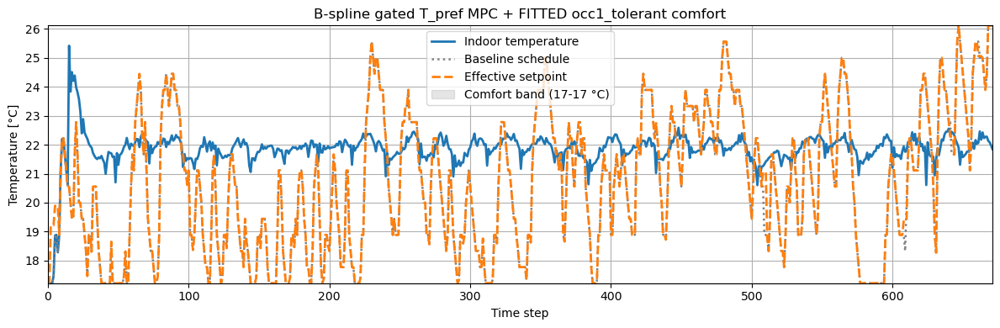


B-spline gated T_pref MPC + FITTED occ2_sensitive


/home/kostas/anaconda3/lib/python3.12/site-packages/do_mpc/controller/_mpc.py:894: UserWarning: rterm was not set and defaults to zero. Changes in the control inputs are not penalized. Can lead to oscillatory behavior.
  warnings.warn('rterm was not set and defaults to zero. Changes in the control inputs are not penalized. Can lead to oscillatory behavior.')
/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded 

This is Ipopt version 3.14.11, running with linear solver MUMPS 5.4.1.

Number of nonzeros in equality constraint Jacobian...:       73
Number of nonzeros in inequality constraint Jacobian.:        0
Number of nonzeros in Lagrangian Hessian.............:       49

Total number of variables............................:       49
                     variables with only lower bounds:        0
                variables with lower and upper bounds:       24
                     variables with only upper bounds:        0
Total number of equality constraints.................:       25
Total number of inequality constraints...............:        0
        inequality constraints with only lower bounds:        0
   inequality constraints with lower and upper bounds:        0
        inequality constraints with only upper bounds:        0

iter    objective    inf_pr   inf_du lg(mu)  ||d||  lg(rg) alpha_du alpha_pr  ls
   0  1.3266312e+04 1.72e+01 4.60e+01  -1.0 0.00e+00    -  0.00e+00 0.00e+00 

,cost_function,value
0,all_time_peak_average,0.962939
1,annual_normalized_unserved_energy_total,0.000000
2,carbon_emissions_total,NaN
3,cost_total,NaN
4,daily_one_minus_load_factor_average,0.936687
5,daily_peak_average,1.066467
6,discomfort_cold_delta_average,0.214390
7,discomfort_cold_delta_maximum,4.130005
8,discomfort_cold_delta_minimum,0.000000
9,discomfort_cold_proportion,0.030534


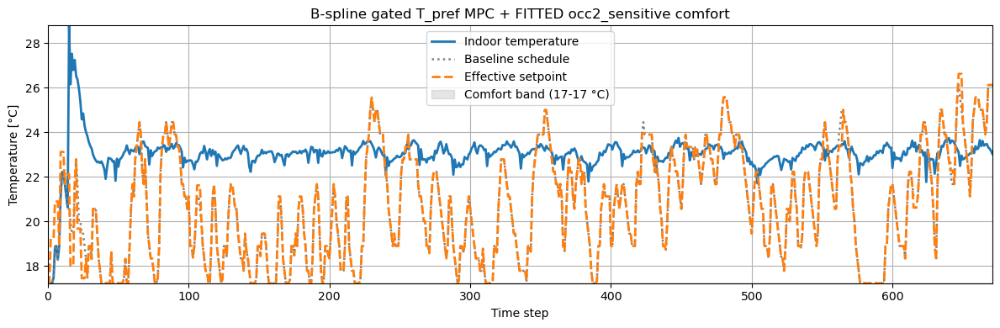


B-spline gated T_pref MPC + FITTED occ3_cold


/home/kostas/anaconda3/lib/python3.12/site-packages/do_mpc/controller/_mpc.py:894: UserWarning: rterm was not set and defaults to zero. Changes in the control inputs are not penalized. Can lead to oscillatory behavior.
  warnings.warn('rterm was not set and defaults to zero. Changes in the control inputs are not penalized. Can lead to oscillatory behavior.')
/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded 

This is Ipopt version 3.14.11, running with linear solver MUMPS 5.4.1.

Number of nonzeros in equality constraint Jacobian...:       73
Number of nonzeros in inequality constraint Jacobian.:        0
Number of nonzeros in Lagrangian Hessian.............:       49

Total number of variables............................:       49
                     variables with only lower bounds:        0
                variables with lower and upper bounds:       24
                     variables with only upper bounds:        0
Total number of equality constraints.................:       25
Total number of inequality constraints...............:        0
        inequality constraints with only lower bounds:        0
   inequality constraints with lower and upper bounds:        0
        inequality constraints with only upper bounds:        0

iter    objective    inf_pr   inf_du lg(mu)  ||d||  lg(rg) alpha_du alpha_pr  ls
   0  9.9574036e+03 1.72e+01 3.99e+01  -1.0 0.00e+00    -  0.00e+00 0.00e+00 

,cost_function,value
0,all_time_peak_average,0.908964
1,annual_normalized_unserved_energy_total,0.000000
2,carbon_emissions_total,NaN
3,cost_total,NaN
4,daily_one_minus_load_factor_average,1.013092
5,daily_peak_average,0.993740
6,discomfort_cold_delta_average,1.351911
7,discomfort_cold_delta_maximum,6.168259
8,discomfort_cold_delta_minimum,0.000000
9,discomfort_cold_proportion,0.320611


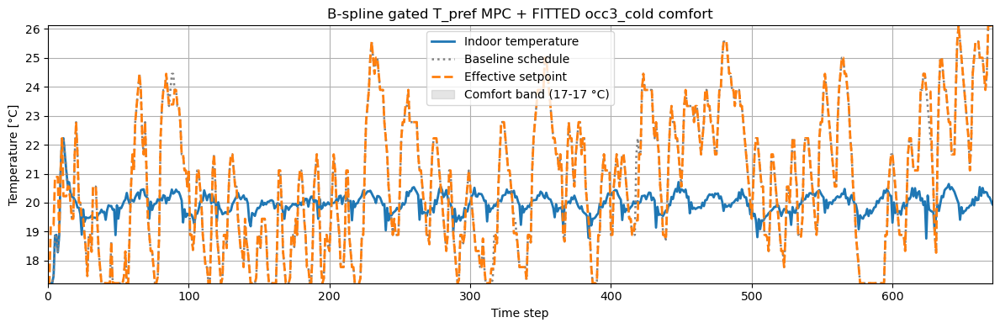


B-spline gated T_pref MPC + FITTED occ4_hot


/home/kostas/anaconda3/lib/python3.12/site-packages/do_mpc/controller/_mpc.py:894: UserWarning: rterm was not set and defaults to zero. Changes in the control inputs are not penalized. Can lead to oscillatory behavior.
  warnings.warn('rterm was not set and defaults to zero. Changes in the control inputs are not penalized. Can lead to oscillatory behavior.')
/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded 

This is Ipopt version 3.14.11, running with linear solver MUMPS 5.4.1.

Number of nonzeros in equality constraint Jacobian...:       73
Number of nonzeros in inequality constraint Jacobian.:        0
Number of nonzeros in Lagrangian Hessian.............:       49

Total number of variables............................:       49
                     variables with only lower bounds:        0
                variables with lower and upper bounds:       24
                     variables with only upper bounds:        0
Total number of equality constraints.................:       25
Total number of inequality constraints...............:        0
        inequality constraints with only lower bounds:        0
   inequality constraints with lower and upper bounds:        0
        inequality constraints with only upper bounds:        0

iter    objective    inf_pr   inf_du lg(mu)  ||d||  lg(rg) alpha_du alpha_pr  ls
   0  1.4292017e+04 1.72e+01 4.78e+01  -1.0 0.00e+00    -  0.00e+00 0.00e+00 

,cost_function,value
0,all_time_peak_average,0.979720
1,annual_normalized_unserved_energy_total,0.000000
2,carbon_emissions_total,NaN
3,cost_total,NaN
4,daily_one_minus_load_factor_average,0.914707
5,daily_peak_average,1.089466
6,discomfort_cold_delta_average,0.086991
7,discomfort_cold_delta_maximum,2.551050
8,discomfort_cold_delta_minimum,0.000000
9,discomfort_cold_proportion,0.012214


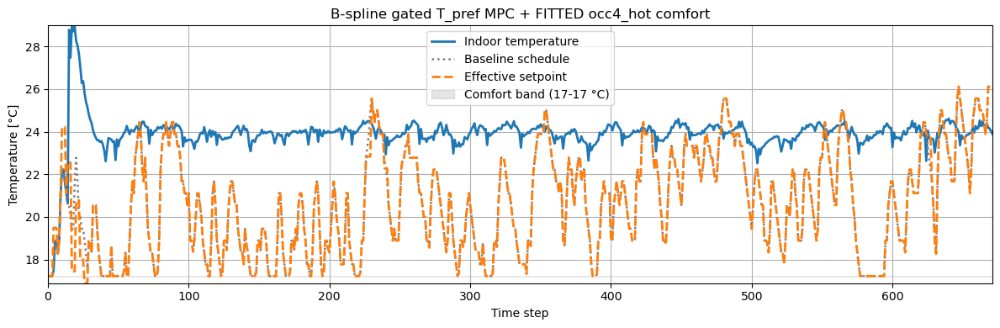


B-spline gated T_pref MPC + NO OCCUPANT


/home/kostas/anaconda3/lib/python3.12/site-packages/do_mpc/controller/_mpc.py:894: UserWarning: rterm was not set and defaults to zero. Changes in the control inputs are not penalized. Can lead to oscillatory behavior.
  warnings.warn('rterm was not set and defaults to zero. Changes in the control inputs are not penalized. Can lead to oscillatory behavior.')
/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded 

This is Ipopt version 3.14.11, running with linear solver MUMPS 5.4.1.

Number of nonzeros in equality constraint Jacobian...:       73
Number of nonzeros in inequality constraint Jacobian.:        0
Number of nonzeros in Lagrangian Hessian.............:       49

Total number of variables............................:       49
                     variables with only lower bounds:        0
                variables with lower and upper bounds:       24
                     variables with only upper bounds:        0
Total number of equality constraints.................:       25
Total number of inequality constraints...............:        0
        inequality constraints with only lower bounds:        0
   inequality constraints with lower and upper bounds:        0
        inequality constraints with only upper bounds:        0

iter    objective    inf_pr   inf_du lg(mu)  ||d||  lg(rg) alpha_du alpha_pr  ls
   0  2.3999952e-06 1.72e+01 1.42e-06  -1.0 0.00e+00    -  0.00e+00 0.00e+00 

,cost_function,value
0,all_time_peak_average,0.816185
1,annual_normalized_unserved_energy_total,0.000000
2,carbon_emissions_total,NaN
3,cost_total,NaN
4,daily_one_minus_load_factor_average,1.354901
5,daily_peak_average,0.770528
6,discomfort_cold_delta_average,15.650560
7,discomfort_cold_delta_maximum,23.608740
8,discomfort_cold_delta_minimum,0.000000
9,discomfort_cold_proportion,0.970992


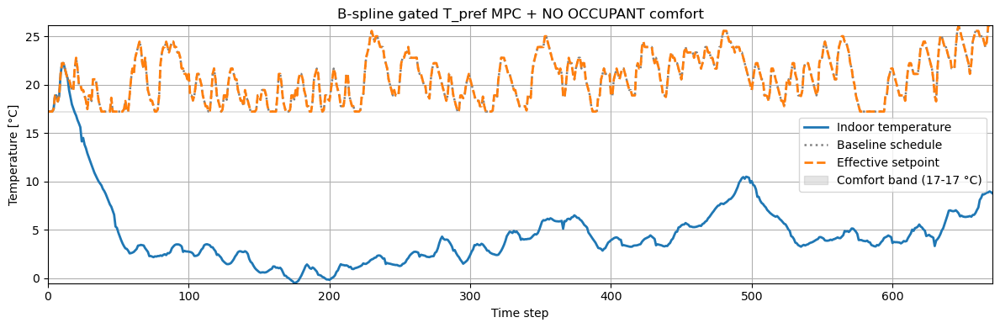

,occupant,target_temperature,predicted_occupied_fraction,override_count,electricity_consumption_total,discomfort_proportion,discomfort_cold_proportion,discomfort_hot_proportion,daily_peak_average
0,occ1_tolerant,21.861014,1.0,6,1.069681,0.482443,0.082443,0.400000,1.037479
1,occ2_sensitive,23.035896,1.0,13,1.136754,0.569466,0.030534,0.538931,1.066467
2,occ3_cold,19.957358,1.0,8,0.965303,0.464122,0.320611,0.143511,0.993740
3,occ4_hot,23.909844,1.0,10,1.189277,0.671756,0.012214,0.659542,1.089466
4,NO_OCCUPANT,24.000000,0.0,0,0.390653,0.970992,0.970992,0.000000,0.770528


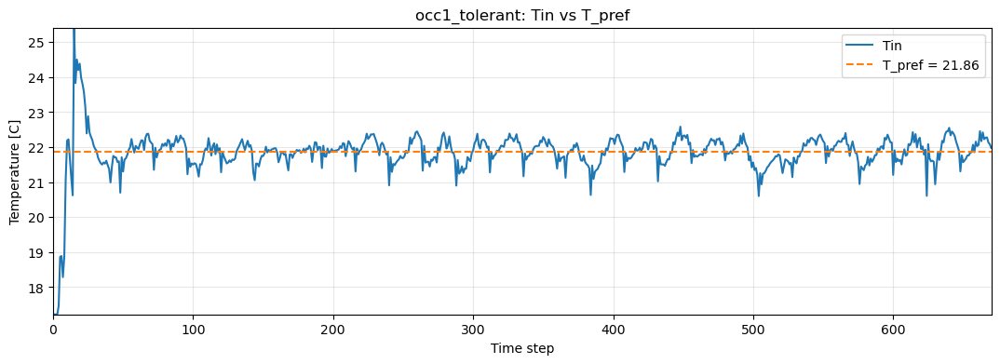

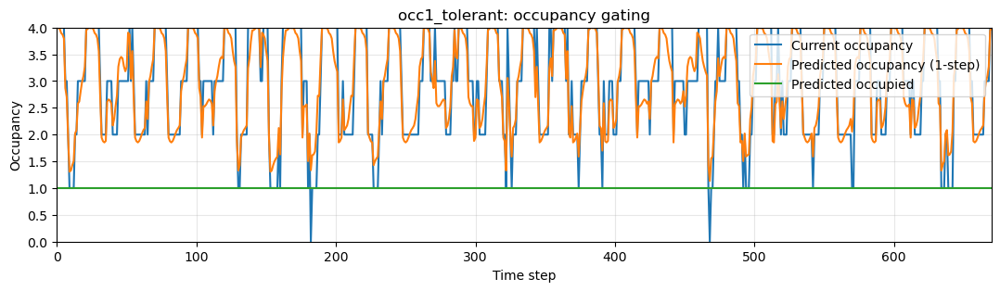

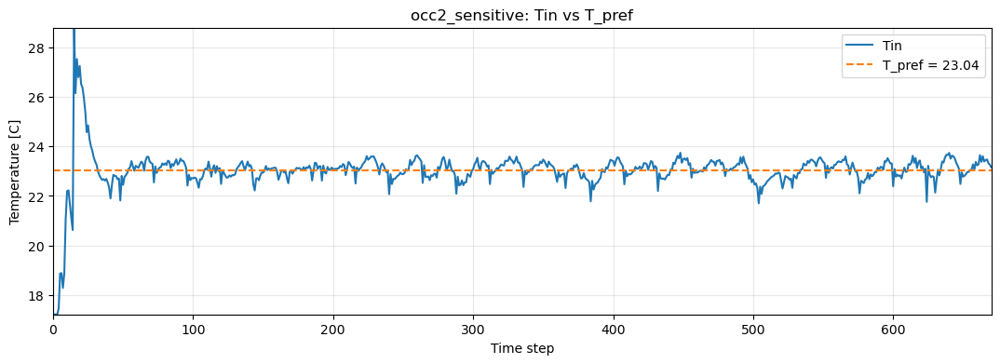

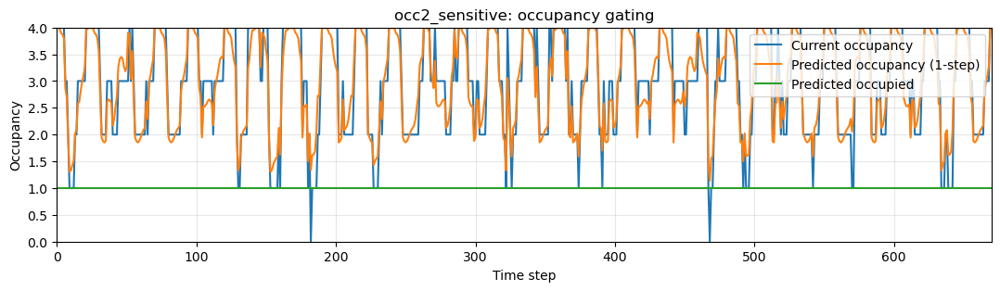

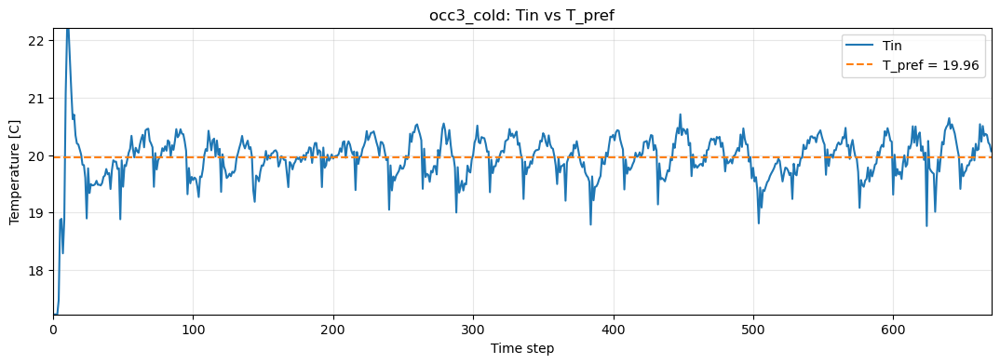

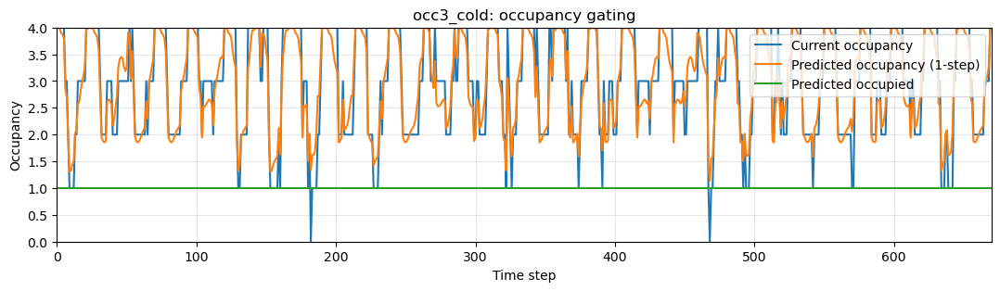

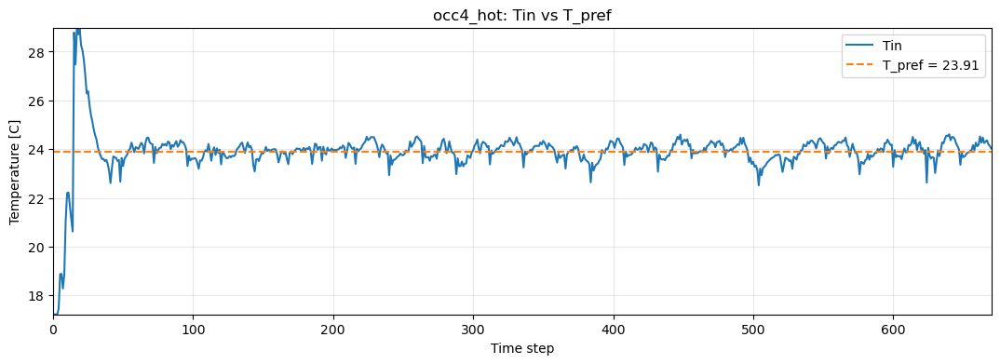

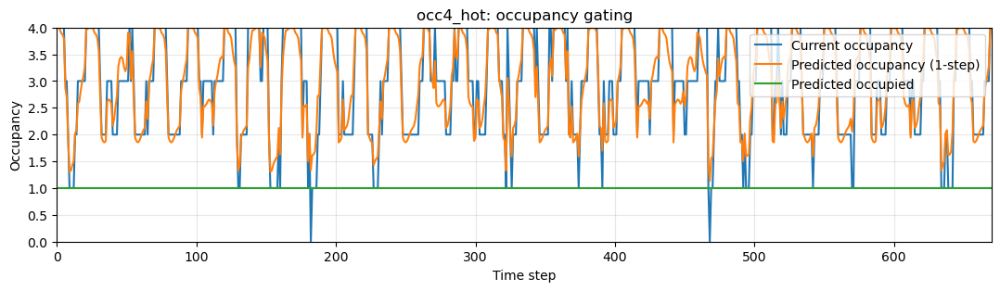

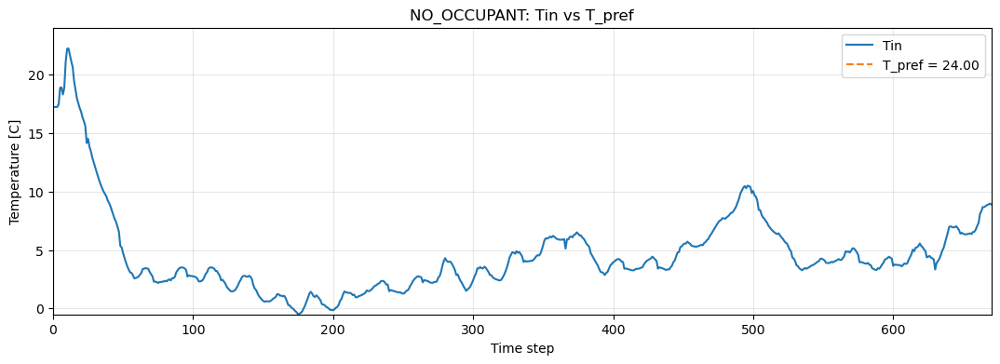

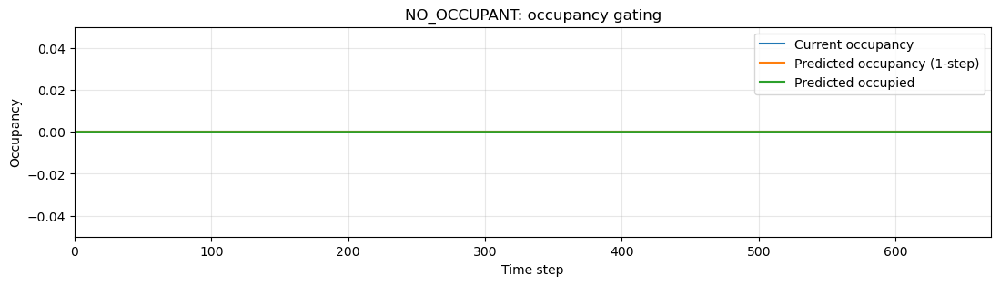

In [29]:
# ============================================================
# B-SPLINE GATED T_pref MPC
# - 4 fitted occupants + 1 NO OCCUPANT baseline
# - uses each occupant's own T_pref
# - uses B-spline occupancy only to gate comfort term
# - restores plot_comfort_with_setpoints(...)
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from copy import deepcopy

import casadi as ca
import do_mpc

from scipy.interpolate import BSpline
from scipy.optimize import minimize
from scipy.special import expit


# ============================================================
# 1) OCCUPANCY DATA LOADER
# ============================================================

def load_building_occupancy_series(schema, root_directory, building_name):
    filepath = Path(root_directory) / schema["buildings"][building_name]["energy_simulation"]
    df = pd.read_csv(filepath)
    return df["occupant_count"].astype(int).to_numpy()


# ============================================================
# 2) FIXED B-SPLINE OCCUPANCY PREDICTOR
# ============================================================

class FixedBSplineIMCOccupancyPredictor:
    def __init__(
        self,
        period=24,
        spline_degree=3,
        n_internal_knots=4,
        l2_phi=1e-3,
        min_samples_per_state=25,
        maxiter=1000,
        random_state=42,
        verbose=False
    ):
        self.period = period
        self.spline_degree = spline_degree
        self.n_internal_knots = n_internal_knots
        self.l2_phi = l2_phi
        self.min_samples_per_state = min_samples_per_state
        self.maxiter = maxiter
        self.random_state = random_state
        self.verbose = verbose

        self.states_ = None
        self.state_to_idx_ = None
        self.row_models_ = {}
        self.knot_vector_ = None
        self.interior_knots_ = None
        self.n_basis_ = None

    def _time_in_period(self, t_idx):
        return np.mod(np.asarray(t_idx, dtype=float), self.period)

    def _build_fixed_knot_vector(self):
        k = self.spline_degree
        if self.n_internal_knots > 0:
            interior_knots = np.linspace(
                0.0, float(self.period), self.n_internal_knots + 2
            )[1:-1]
        else:
            interior_knots = np.array([], dtype=float)

        knot_vector = np.concatenate([
            np.repeat(0.0, k + 1),
            interior_knots,
            np.repeat(float(self.period), k + 1)
        ])
        return knot_vector, interior_knots

    def _basis_matrix(self, t_values):
        t_values = np.asarray(t_values, dtype=float)
        k = self.spline_degree
        knot_vector = self.knot_vector_
        n_basis = len(knot_vector) - k - 1

        B = np.zeros((len(t_values), n_basis), dtype=float)

        for r in range(n_basis):
            coeff = np.zeros(n_basis, dtype=float)
            coeff[r] = 1.0
            spline = BSpline(knot_vector, coeff, k, extrapolate=False)
            vals = spline(t_values)
            vals = np.nan_to_num(vals, nan=0.0, posinf=0.0, neginf=0.0)
            B[:, r] = vals

        B[B < 0] = 0.0
        row_sums = B.sum(axis=1, keepdims=True)
        valid = row_sums[:, 0] > 0
        B[valid] /= row_sums[valid]
        return B

    def _row_probabilities(self, B, Phi):
        psi = B @ Phi
        q = expit(psi)
        denom = np.clip(q.sum(axis=1, keepdims=True), 1e-12, None)
        P = q / denom
        return P, psi

    def _row_objective(self, phi_flat, B, y_next_idx, n_states):
        Phi = phi_flat.reshape(self.n_basis_, n_states)
        P, _ = self._row_probabilities(B, Phi)
        probs = P[np.arange(len(y_next_idx)), y_next_idx]
        probs = np.clip(probs, 1e-12, 1.0)
        nll = -np.sum(np.log(probs))
        reg_phi = self.l2_phi * np.sum(Phi ** 2)
        return nll + reg_phi

    def fit(self, occupancy_series):
        y = np.asarray(occupancy_series, dtype=int)
        if len(y) < 2:
            raise ValueError("Need at least 2 occupancy observations.")

        self.states_ = np.sort(np.unique(y))
        self.state_to_idx_ = {state: i for i, state in enumerate(self.states_)}

        self.knot_vector_, self.interior_knots_ = self._build_fixed_knot_vector()
        self.n_basis_ = len(self.knot_vector_) - self.spline_degree - 1

        y_curr = y[:-1]
        y_next = y[1:]
        t_idx = np.arange(len(y) - 1)
        t_period = self._time_in_period(t_idx)

        s = len(self.states_)
        rng = np.random.default_rng(self.random_state)
        self.row_models_ = {}

        for state_i in self.states_:
            mask = (y_curr == state_i)
            t_i = t_period[mask]
            y_next_i = y_next[mask]
            y_next_idx = np.array([self.state_to_idx_[v] for v in y_next_i], dtype=int)

            counts = np.bincount(y_next_idx, minlength=s).astype(float)
            empirical = counts / counts.sum() if counts.sum() > 0 else np.ones(s) / s

            if len(y_next_i) < self.min_samples_per_state:
                self.row_models_[state_i] = {
                    "fitted": False,
                    "empirical_probs": empirical,
                    "Phi": None,
                }
                continue

            B_i = self._basis_matrix(t_i)

            eps = 1e-6
            target_q = np.clip(empirical, eps, 1 - eps)
            psi0 = np.log(target_q / (1 - target_q))
            Phi0 = np.tile(psi0, (self.n_basis_, 1)) / self.n_basis_
            Phi0 += 0.01 * rng.standard_normal(Phi0.shape)

            result = minimize(
                fun=self._row_objective,
                x0=Phi0.ravel(),
                args=(B_i, y_next_idx, s),
                method="L-BFGS-B",
                options={"maxiter": self.maxiter}
            )

            Phi_opt = result.x.reshape(self.n_basis_, s)
            self.row_models_[state_i] = {
                "fitted": True,
                "empirical_probs": empirical,
                "Phi": Phi_opt,
            }

        return self

    def transition_matrix(self, t):
        if self.states_ is None:
            raise RuntimeError("Fit the occupancy model first.")

        s = len(self.states_)
        P_t = np.zeros((s, s), dtype=float)
        t_mod = np.array([self._time_in_period([t])[0]])
        B_t = self._basis_matrix(t_mod)

        for i, state_i in enumerate(self.states_):
            row_model = self.row_models_[state_i]
            if not row_model["fitted"]:
                row = row_model["empirical_probs"].copy()
            else:
                row, _ = self._row_probabilities(B_t, row_model["Phi"])
                row = row[0]

            row = np.clip(row, 1e-12, None)
            row /= row.sum()
            P_t[i, :] = row

        return P_t

    def predict_distribution(self, current_state, start_t, horizon):
        if current_state not in self.state_to_idx_:
            raise ValueError(f"Current state {current_state} not seen during fitting.")

        s = len(self.states_)
        pi = np.zeros(s, dtype=float)
        pi[self.state_to_idx_[current_state]] = 1.0

        distributions = []
        for h in range(horizon):
            P = self.transition_matrix(start_t + h)
            pi = pi @ P
            distributions.append(pi.copy())

        return np.asarray(distributions)

    def predict_expected_occupancy(self, current_state, start_t, horizon):
        distributions = self.predict_distribution(current_state, start_t, horizon)
        expected = distributions @ self.states_
        return expected, distributions


# ============================================================
# 3) HELPERS
# ============================================================

def forecast_occupancy_from_bsplines(occupancy_model, current_occupancy, time_step, horizon, alpha=0.5):
    occ_hat_h, _ = occupancy_model.predict_expected_occupancy(
        current_state=int(current_occupancy),
        start_t=int(time_step),
        horizon=int(horizon),
    )
    occ_bin_h = (occ_hat_h > float(alpha)).astype(float)
    return occ_hat_h, occ_bin_h


class NoOccupantProfile:
    def __init__(self, T_pref=24.0):
        self.T_pref = float(T_pref)
        self.last_vote = None

    def step(self, Tin, scheduled_next_Tsp, occupied=False):
        self.last_vote = None
        return float(scheduled_next_Tsp)


# ============================================================
# 4) RUNNER
# ============================================================

def run_february_bspline_pref_mpc(
    controller_name,
    occupant,
    schema,
    root_directory,
    occupancy_building_name,
    fixed_band=None,
    alpha_occ=0.5,
    lambda_u=1e-3,
    lambda_du=0.0,
    use_smooth_du=False,
    occ_period=24,
    occ_spline_degree=3,
    occ_n_internal_knots=4,
    occ_l2_phi=1e-3,
    occ_min_samples_per_state=25,
    occ_maxiter=1000,
    reward_function=None,
    seed=None,
    verbose_occ=False,
    use_bsplines=True,
):
    seed = int(RANDOM_SEED if seed is None else seed)
    set_experiment_seed(seed)

    target_temperature = float(occupant.T_pref)
    sim_occupant = deepcopy(occupant)

    occupancy_series = load_building_occupancy_series(schema, root_directory, occupancy_building_name)

    if use_bsplines:
        occupancy_model = FixedBSplineIMCOccupancyPredictor(
            period=occ_period,
            spline_degree=occ_spline_degree,
            n_internal_knots=occ_n_internal_knots,
            l2_phi=occ_l2_phi,
            min_samples_per_state=occ_min_samples_per_state,
            maxiter=occ_maxiter,
            random_state=seed,
            verbose=verbose_occ,
        )
        occupancy_model.fit(occupancy_series)
    else:
        occupancy_model = None

    model = do_mpc.model.Model('discrete')

    Tin_m = model.set_variable('_x', 'Tin')
    if use_smooth_du:
        u_prev = model.set_variable('_x', 'u_prev')

    u_m = model.set_variable('_u', 'u')

    Tout_m = model.set_variable('_tvp', 'Tout')
    Sol_m = model.set_variable('_tvp', 'Sol')
    Tpref_m = model.set_variable('_tvp', 'Tpref')
    Tmin_m = model.set_variable('_tvp', 'Tmin')
    Tmax_m = model.set_variable('_tvp', 'Tmax')
    occ_bin_m = model.set_variable('_tvp', 'occ_bin')
    occ_hat_m = model.set_variable('_tvp', 'occ_hat')
    w_est = model.set_variable('_tvp', 'w_est')

    COP_expr = cop_a + cop_b * Tout_m
    COP_expr = ca.fmin(ca.fmax(COP_expr, 0.5), 6.0)

    Tin_next_m = (
        A * Tin_m
        + Bd0 * Tm
        + Bd1 * Tout_m
        + Bd2 * Sol_m
        + Bu * COP_expr * u_m
        + w_est
    )

    model.set_rhs('Tin', Tin_next_m)
    if use_smooth_du:
        model.set_rhs('u_prev', u_m)
    model.setup()

    mpc = do_mpc.controller.MPC(model)
    setup_mpc = {
        'n_horizon': 24,
        't_step': 1.0,
        'state_discretization': 'discrete',
        'store_full_solution': True,
    }
    mpc.set_param(**setup_mpc)

    # Comfort active only when predicted occupied; energy always active.
    stage_cost = occ_bin_m * (Tin_m - Tpref_m) ** 2 + lambda_u * u_m ** 2
    terminal_cost = occ_bin_m * (Tin_m - Tpref_m) ** 2

    if use_smooth_du:
        stage_cost = stage_cost + lambda_du * (u_m - u_prev) ** 2

    mpc.set_objective(mterm=terminal_cost, lterm=stage_cost)

    mpc.bounds['lower', '_u', 'u'] = 0.0
    mpc.bounds['upper', '_u', 'u'] = 1.0

    N = setup_mpc['n_horizon']
    tvp_template = mpc.get_tvp_template()
    _latest = dict(
        Tout0=0.0,
        Sol0=0.0,
        Tpref=target_temperature,
        Tmin0=18.0,
        Tmax0=24.0,
        occ_hat=np.zeros(N + 1),
        occ_bin=np.zeros(N + 1),
        Toutp=[0.0, 0.0, 0.0],
        Solp=[0.0, 0.0, 0.0],
        w_est=0.0,
    )

    def tvp_fun(t_now):
        Tout0 = _latest['Tout0']
        Sol0 = _latest['Sol0']
        Tpref = _latest['Tpref']
        Tmin0 = _latest['Tmin0']
        Tmax0 = _latest['Tmax0']
        occ_hat = _latest['occ_hat']
        occ_bin = _latest['occ_bin']
        Toutp = _latest['Toutp']
        Solp = _latest['Solp']
        w_est_val = _latest['w_est']

        for k in range(N + 1):
            if k == 0:
                Tout_f, Sol_f = Tout0, Sol0
            elif k <= 3:
                Tout_f, Sol_f = Toutp[k - 1], Solp[k - 1]
            else:
                Tout_f, Sol_f = Toutp[-1], Solp[-1]

            tvp_template['_tvp', k, 'Tout'] = float(Tout_f)
            tvp_template['_tvp', k, 'Sol'] = float(Sol_f)
            tvp_template['_tvp', k, 'Tpref'] = float(Tpref)
            tvp_template['_tvp', k, 'Tmin'] = float(Tmin0)
            tvp_template['_tvp', k, 'Tmax'] = float(Tmax0)
            tvp_template['_tvp', k, 'occ_hat'] = float(occ_hat[k])
            tvp_template['_tvp', k, 'occ_bin'] = float(occ_bin[k])
            tvp_template['_tvp', k, 'w_est'] = float(w_est_val)

        return tvp_template

    mpc.set_tvp_fun(tvp_fun)
    mpc.setup()

    env_kwargs = dict(
        simulation_start_time_step=SIMULATION_START_TIME_STEP,
        simulation_end_time_step=SIMULATION_END_TIME_STEP,
        random_seed=seed,
    )
    if reward_function is not None:
        env_kwargs['reward_function'] = reward_function

    env = make_env(**env_kwargs)
    env = OccupantWrapper(env, sim_occupant)

    obs, _ = env.reset(seed=seed)
    building = env.unwrapped.buildings[0]
    mpc.reset_history()

    Tin_hist, Tmin_hist, Tmax_hist = [], [], []
    u_hist, price_hist = [], []
    occ_now_hist, occ_hat_hist, occ_bin_hist = [], [], []

    w_est_val = 0.0
    gamma_w = 0.2

    prev_Tin = None
    prev_u = None
    prev_Tout = None
    prev_Sol = None
    last_u = 0.0

    terminated = False
    truncated = False

    while not (terminated or truncated):
        o = obs[0] if isinstance(obs, (list, tuple)) else obs

        Tin0 = float(o[i_tin])
        Tout0 = float(o[i_tout])
        Sol0 = float(o[i_sol])
        time_step = int(building.time_step)
        Price0 = float(building.pricing.electricity_pricing[time_step])

        Toutp = [float(o[j]) for j in i_tout_p]
        Solp = [float(o[j]) for j in i_sol_p]

        if fixed_band is None:
            Tmin0 = float(o[i_tmin])
            Tmax0 = float(o[i_tmax])
        else:
            Tmin0, Tmax0 = map(float, fixed_band)

        if prev_Tin is not None:
            cop_prev = np.clip(cop_a + cop_b * prev_Tout, 0.5, 6.0)
            Tin_pred = (
                A * prev_Tin
                + Bd0 * Tm
                + Bd1 * prev_Tout
                + Bd2 * prev_Sol
                + Bu * cop_prev * prev_u
                + w_est_val
            )
            err = Tin0 - Tin_pred
            w_est_val = w_est_val + gamma_w * err

        if use_bsplines:
            if time_step >= len(occupancy_series):
                occ_now = int(occupancy_series[-1])
            else:
                occ_now = int(occupancy_series[time_step])

            occ_hat_h, occ_bin_h = forecast_occupancy_from_bsplines(
                occupancy_model=occupancy_model,
                current_occupancy=occ_now,
                time_step=time_step,
                horizon=N,
                alpha=alpha_occ,
            )

            occ_hat_full = np.zeros(N + 1)
            occ_bin_full = np.zeros(N + 1)
            occ_hat_full[0] = float(occ_now)
            occ_bin_full[0] = float(occ_now > alpha_occ)
            occ_hat_full[1:] = occ_hat_h
            occ_bin_full[1:] = occ_bin_h
        else:
            occ_now = 0
            occ_hat_h = np.zeros(N)
            occ_bin_h = np.zeros(N)
            occ_hat_full = np.zeros(N + 1)
            occ_bin_full = np.zeros(N + 1)

        _latest.update(dict(
            Tout0=Tout0,
            Sol0=Sol0,
            Tpref=target_temperature,
            Tmin0=Tmin0,
            Tmax0=Tmax0,
            occ_hat=occ_hat_full,
            occ_bin=occ_bin_full,
            Toutp=Toutp,
            Solp=Solp,
            w_est=w_est_val,
        ))

        if use_smooth_du:
            x0 = np.array([[Tin0], [last_u]])
        else:
            x0 = np.array([[Tin0]])

        u0 = float(mpc.make_step(x0))
        obs, reward, terminated, truncated, info = env.step([[u0]])

        prev_Tin = Tin0
        prev_u = u0
        prev_Tout = Tout0
        prev_Sol = Sol0
        last_u = u0

        Tin_hist.append(Tin0)
        Tmin_hist.append(Tmin0)
        Tmax_hist.append(Tmax0)
        u_hist.append(u0)
        price_hist.append(Price0)
        occ_now_hist.append(float(occ_now))
        occ_hat_hist.append(float(occ_hat_h[0]) if len(occ_hat_h) > 0 else 0.0)
        occ_bin_hist.append(float(occ_bin_h[0]) if len(occ_bin_h) > 0 else 0.0)

    kpis = env.unwrapped.evaluate().copy()
    district_kpis = kpis[kpis['level'] == 'district'].copy()
    override_count = int(getattr(env, 'override_count', 0))

    print(f"{controller_name} run finished")
    print(f"Target temperature: {target_temperature:.3f} C")
    print(f"Predicted occupied fraction: {np.mean(occ_bin_hist):.3f}")
    print(f"Overrides: {override_count}")
    display(district_kpis[['cost_function', 'value']].reset_index(drop=True))

    plot_comfort_with_setpoints(
        env,
        building_idx=0,
        T_low=float(Tmin_hist[0]),
        T_high=float(Tmax_hist[0]),
        title=f"{controller_name} comfort",
    )

    return dict(
        name=controller_name,
        target_temperature=target_temperature,
        env=env,
        occupancy_model=occupancy_model,
        occupancy_series=occupancy_series if use_bsplines else None,
        kpis=kpis,
        district_kpis=district_kpis,
        Tin_hist=np.array(Tin_hist),
        Tmin_hist=np.array(Tmin_hist),
        Tmax_hist=np.array(Tmax_hist),
        u_hist=np.array(u_hist),
        price_hist=np.array(price_hist),
        occ_now_hist=np.array(occ_now_hist),
        occ_hat_hist=np.array(occ_hat_hist),
        occ_bin_hist=np.array(occ_bin_hist),
        override_count=override_count,
        use_bsplines=use_bsplines,
    )


# ============================================================
# 5) EXTRA PLOT FOR OCCUPANCY / NO OCCUPANCY
# ============================================================

def plot_bspline_gating_signals(result, title_prefix=None):
    if title_prefix is None:
        title_prefix = result["name"]

    x = np.arange(len(result["Tin_hist"]))
    target = result["target_temperature"]

    plt.figure(figsize=(13, 4))
    plt.plot(x, result["Tin_hist"], label="Tin")
    plt.plot(x, np.full_like(x, target, dtype=float), "--", label=f"T_pref = {target:.2f}")
    plt.xlabel("Time step")
    plt.ylabel("Temperature [C]")
    plt.title(f"{title_prefix}: Tin vs T_pref")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()

    plt.figure(figsize=(13, 3))
    plt.plot(x, result["occ_now_hist"], label="Current occupancy")
    plt.plot(x, result["occ_hat_hist"], label="Predicted occupancy (1-step)")
    plt.step(x, result["occ_bin_hist"], where="post", label="Predicted occupied")
    plt.xlabel("Time step")
    plt.ylabel("Occupancy")
    plt.title(f"{title_prefix}: occupancy gating")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()


# ============================================================
# 6) RUN 4 FITTED OCCUPANTS + 1 NO OCCUPANT
# ============================================================

if "fitted_occupants_named" not in globals():
    raise RuntimeError("fitted_occupants_named not found. Run the fitting megacell first.")

BSPLINE_PREF_MPC_CONFIG = dict(
    fixed_band=None,
    alpha_occ=0.5,
    lambda_u=1e-3,
    lambda_du=0.0,
    use_smooth_du=False,
    occ_period=24,
    occ_spline_degree=3,
    occ_n_internal_knots=4,
    occ_l2_phi=1e-3,
    occ_min_samples_per_state=25,
    occ_maxiter=1000,
)

occupancy_building_name = "resstock-amy2018-2021-release-1-20199"

bspline_pref_results = {}

# 4 fitted occupants
for occ_idx, (name, occ_fit) in enumerate(fitted_occupants_named.items(), start=1):
    print(f"\nB-spline gated T_pref MPC + FITTED {name}")
    bspline_pref_results[name] = run_february_bspline_pref_mpc(
        controller_name=f'B-spline gated T_pref MPC + FITTED {name}',
        occupant=occ_fit,
        schema=schema,
        root_directory=root_directory,
        occupancy_building_name=occupancy_building_name,
        reward_function=OccupantComfortReward,
        seed=int(RANDOM_SEED + occ_idx),
        use_bsplines=True,
        **BSPLINE_PREF_MPC_CONFIG,
    )

# 1 no-occupant baseline
no_occ = NoOccupantProfile(T_pref=24.0)

print("\nB-spline gated T_pref MPC + NO OCCUPANT")
bspline_pref_results["NO_OCCUPANT"] = run_february_bspline_pref_mpc(
    controller_name='B-spline gated T_pref MPC + NO OCCUPANT',
    occupant=no_occ,
    schema=schema,
    root_directory=root_directory,
    occupancy_building_name=occupancy_building_name,
    reward_function=OccupantComfortReward,
    seed=int(RANDOM_SEED + 999),
    use_bsplines=False,   # <-- no occupant means comfort term always off
    **BSPLINE_PREF_MPC_CONFIG,
)


# ============================================================
# 7) SUMMARY TABLE
# ============================================================

bspline_pref_summary_rows = []
for name, result in bspline_pref_results.items():
    row = summarize_run(name, result)
    row['target_temperature'] = float(result['target_temperature'])
    row['predicted_occupied_fraction'] = float(np.mean(result['occ_bin_hist']))
    bspline_pref_summary_rows.append(row)

bspline_pref_summary = pd.DataFrame(bspline_pref_summary_rows)
bspline_pref_summary = bspline_pref_summary[[
    'occupant',
    'target_temperature',
    'predicted_occupied_fraction',
    'override_count',
    'electricity_consumption_total',
    'discomfort_proportion',
    'discomfort_cold_proportion',
    'discomfort_hot_proportion',
    'daily_peak_average',
]]
display(bspline_pref_summary)


# ============================================================
# 8) OPTIONAL EXTRA PLOTS FOR ALL 5
# ============================================================

for name, result in bspline_pref_results.items():
    plot_bspline_gating_signals(result, title_prefix=name)


Constant-T_pref MPC + occ1_tolerant


/home/kostas/anaconda3/lib/python3.12/site-packages/do_mpc/controller/_mpc.py:894: UserWarning: rterm was not set and defaults to zero. Changes in the control inputs are not penalized. Can lead to oscillatory behavior.
  warnings.warn('rterm was not set and defaults to zero. Changes in the control inputs are not penalized. Can lead to oscillatory behavior.')
/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded 

This is Ipopt version 3.14.11, running with linear solver MUMPS 5.4.1.

Number of nonzeros in equality constraint Jacobian...:       73
Number of nonzeros in inequality constraint Jacobian.:        0
Number of nonzeros in Lagrangian Hessian.............:       49

Total number of variables............................:       49
                     variables with only lower bounds:        0
                variables with lower and upper bounds:       24
                     variables with only upper bounds:        0
Total number of equality constraints.................:       25
Total number of inequality constraints...............:        0
        inequality constraints with only lower bounds:        0
   inequality constraints with lower and upper bounds:        0
        inequality constraints with only upper bounds:        0

iter    objective    inf_pr   inf_du lg(mu)  ||d||  lg(rg) alpha_du alpha_pr  ls
   0  1.2100000e+04 1.72e+01 4.40e+01  -1.0 0.00e+00    -  0.00e+00 0.00e+00 

,cost_function,value
0,all_time_peak_average,0.943864
1,annual_normalized_unserved_energy_total,0.000000
2,carbon_emissions_total,NaN
3,cost_total,NaN
4,daily_one_minus_load_factor_average,0.962263
5,daily_peak_average,1.040832
6,discomfort_cold_delta_average,0.450177
7,discomfort_cold_delta_maximum,4.124359
8,discomfort_cold_delta_minimum,0.000000
9,discomfort_cold_proportion,0.080916


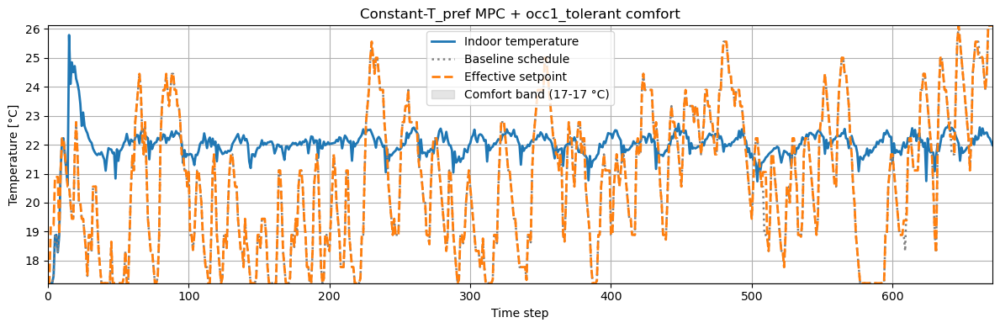


Constant-T_pref MPC + occ2_sensitive


/home/kostas/anaconda3/lib/python3.12/site-packages/do_mpc/controller/_mpc.py:894: UserWarning: rterm was not set and defaults to zero. Changes in the control inputs are not penalized. Can lead to oscillatory behavior.
  warnings.warn('rterm was not set and defaults to zero. Changes in the control inputs are not penalized. Can lead to oscillatory behavior.')
/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded 

This is Ipopt version 3.14.11, running with linear solver MUMPS 5.4.1.

Number of nonzeros in equality constraint Jacobian...:       73
Number of nonzeros in inequality constraint Jacobian.:        0
Number of nonzeros in Lagrangian Hessian.............:       49

Total number of variables............................:       49
                     variables with only lower bounds:        0
                variables with lower and upper bounds:       24
                     variables with only upper bounds:        0
Total number of equality constraints.................:       25
Total number of inequality constraints...............:        0
        inequality constraints with only lower bounds:        0
   inequality constraints with lower and upper bounds:        0
        inequality constraints with only upper bounds:        0

iter    objective    inf_pr   inf_du lg(mu)  ||d||  lg(rg) alpha_du alpha_pr  ls
   0  1.3225000e+04 1.72e+01 4.60e+01  -1.0 0.00e+00    -  0.00e+00 0.00e+00 

,cost_function,value
0,all_time_peak_average,0.962263
1,annual_normalized_unserved_energy_total,0.000000
2,carbon_emissions_total,NaN
3,cost_total,NaN
4,daily_one_minus_load_factor_average,0.937572
5,daily_peak_average,1.065560
6,discomfort_cold_delta_average,0.220960
7,discomfort_cold_delta_maximum,4.165880
8,discomfort_cold_delta_minimum,0.000000
9,discomfort_cold_proportion,0.032061


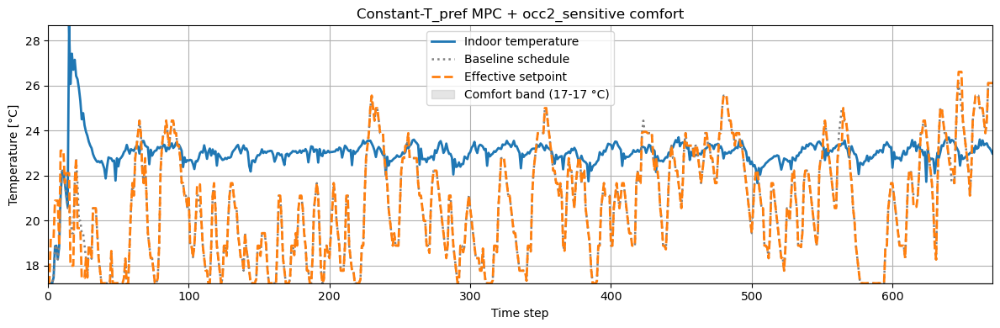


Constant-T_pref MPC + occ3_cold


/home/kostas/anaconda3/lib/python3.12/site-packages/do_mpc/controller/_mpc.py:894: UserWarning: rterm was not set and defaults to zero. Changes in the control inputs are not penalized. Can lead to oscillatory behavior.
  warnings.warn('rterm was not set and defaults to zero. Changes in the control inputs are not penalized. Can lead to oscillatory behavior.')
/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded 

This is Ipopt version 3.14.11, running with linear solver MUMPS 5.4.1.

Number of nonzeros in equality constraint Jacobian...:       73
Number of nonzeros in inequality constraint Jacobian.:        0
Number of nonzeros in Lagrangian Hessian.............:       49

Total number of variables............................:       49
                     variables with only lower bounds:        0
                variables with lower and upper bounds:       24
                     variables with only upper bounds:        0
Total number of equality constraints.................:       25
Total number of inequality constraints...............:        0
        inequality constraints with only lower bounds:        0
   inequality constraints with lower and upper bounds:        0
        inequality constraints with only upper bounds:        0

iter    objective    inf_pr   inf_du lg(mu)  ||d||  lg(rg) alpha_du alpha_pr  ls
   0  1.0000000e+04 1.72e+01 4.00e+01  -1.0 0.00e+00    -  0.00e+00 0.00e+00 

,cost_function,value
0,all_time_peak_average,0.909654
1,annual_normalized_unserved_energy_total,0.000000
2,carbon_emissions_total,NaN
3,cost_total,NaN
4,daily_one_minus_load_factor_average,1.012029
5,daily_peak_average,0.994673
6,discomfort_cold_delta_average,1.322705
7,discomfort_cold_delta_maximum,6.125500
8,discomfort_cold_delta_minimum,0.000000
9,discomfort_cold_proportion,0.311450


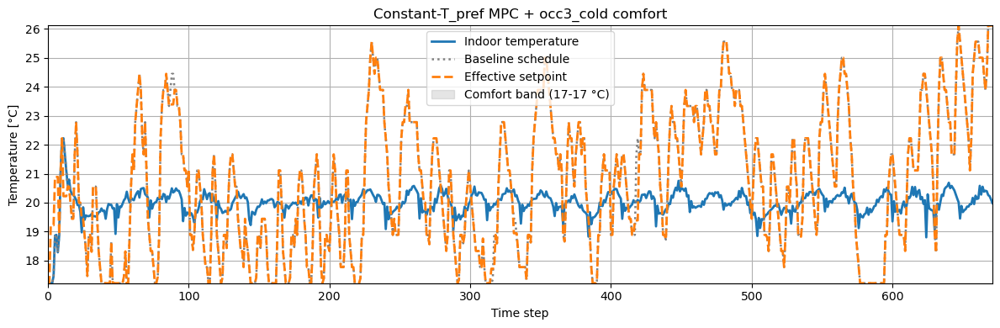


Constant-T_pref MPC + occ4_hot


/home/kostas/anaconda3/lib/python3.12/site-packages/do_mpc/controller/_mpc.py:894: UserWarning: rterm was not set and defaults to zero. Changes in the control inputs are not penalized. Can lead to oscillatory behavior.
  warnings.warn('rterm was not set and defaults to zero. Changes in the control inputs are not penalized. Can lead to oscillatory behavior.')
/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded 

This is Ipopt version 3.14.11, running with linear solver MUMPS 5.4.1.

Number of nonzeros in equality constraint Jacobian...:       73
Number of nonzeros in inequality constraint Jacobian.:        0
Number of nonzeros in Lagrangian Hessian.............:       49

Total number of variables............................:       49
                     variables with only lower bounds:        0
                variables with lower and upper bounds:       24
                     variables with only upper bounds:        0
Total number of equality constraints.................:       25
Total number of inequality constraints...............:        0
        inequality constraints with only lower bounds:        0
   inequality constraints with lower and upper bounds:        0
        inequality constraints with only upper bounds:        0

iter    objective    inf_pr   inf_du lg(mu)  ||d||  lg(rg) alpha_du alpha_pr  ls
   0  1.4400000e+04 1.72e+01 4.80e+01  -1.0 0.00e+00    -  0.00e+00 0.00e+00 

,cost_function,value
0,all_time_peak_average,0.981487
1,annual_normalized_unserved_energy_total,0.000000
2,carbon_emissions_total,NaN
3,cost_total,NaN
4,daily_one_minus_load_factor_average,0.912500
5,daily_peak_average,1.091899
6,discomfort_cold_delta_average,0.079749
7,discomfort_cold_delta_maximum,2.551050
8,discomfort_cold_delta_minimum,0.000000
9,discomfort_cold_proportion,0.010687


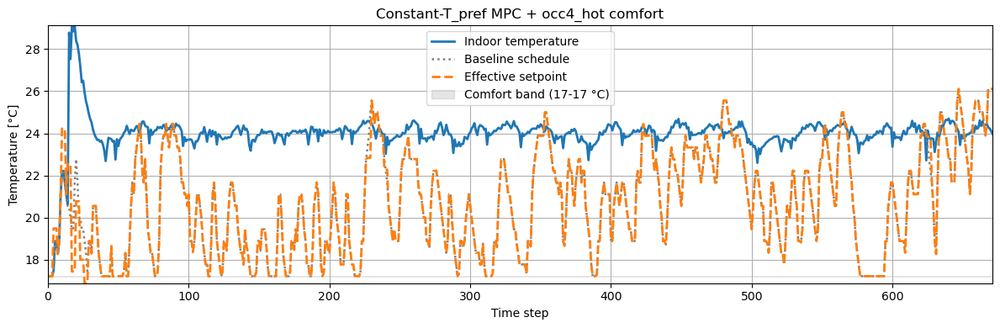

,occupant,target_temperature,override_count,electricity_consumption_total,discomfort_proportion,discomfort_cold_proportion,discomfort_hot_proportion,daily_peak_average
0,occ1_tolerant,22.0,6,1.077515,0.482443,0.080916,0.401527,1.040832
1,occ2_sensitive,23.0,13,1.134675,0.569466,0.032061,0.537405,1.065560
2,occ3_cold,20.0,7,0.967576,0.459542,0.311450,0.148092,0.994673
3,occ4_hot,24.0,10,1.194696,0.679389,0.010687,0.668702,1.091899


In [70]:
# Constant-T_pref MPC experiments.
# The MPC tracks each occupant's preferred constant indoor temperature directly.

CONSTANT_PREF_MPC_CONFIG = dict(
    fixed_band=None,
    lambda_u=1e-3,
    lambda_du=0.0,
    use_smooth_du=False,
    cold_penalty=1e5,
    hot_penalty=1e3,
)


def run_february_constant_pref_mpc(
    controller_name,
    occupant,
    fixed_band=None,
    lambda_u=1e-3,
    lambda_du=0.0,
    use_smooth_du=False,
    cold_penalty=1e5,
    hot_penalty=1e3,
    reward_function=None,
    seed=None,
):
    seed = int(RANDOM_SEED if seed is None else seed)
    set_experiment_seed(seed)

    target_temperature = float(occupant.T_pref)
    sim_occupant = deepcopy(occupant)

    model = do_mpc.model.Model('discrete')

    Tin_m = model.set_variable('_x', 'Tin')
    if use_smooth_du:
        u_prev = model.set_variable('_x', 'u_prev')

    u_m = model.set_variable('_u', 'u')

    Tout_m = model.set_variable('_tvp', 'Tout')
    Sol_m = model.set_variable('_tvp', 'Sol')
    Tpref_m = model.set_variable('_tvp', 'Tpref')
    Tmin_m = model.set_variable('_tvp', 'Tmin')
    Tmax_m = model.set_variable('_tvp', 'Tmax')
    w_est = model.set_variable('_tvp', 'w_est')

    COP_expr = cop_a + cop_b * Tout_m
    COP_expr = ca.fmin(ca.fmax(COP_expr, 0.5), 6.0)

    Tin_next_m = (
        A * Tin_m
        + Bd0 * Tm
        + Bd1 * Tout_m
        + Bd2 * Sol_m
        + Bu * COP_expr * u_m
        + w_est
    )

    model.set_rhs('Tin', Tin_next_m)
    if use_smooth_du:
        model.set_rhs('u_prev', u_m)
    model.setup()

    mpc = do_mpc.controller.MPC(model)
    setup_mpc = {
        'n_horizon': 24,
        't_step': 1.0,
        'state_discretization': 'discrete',
        'store_full_solution': True,
    }
    mpc.set_param(**setup_mpc)

    stage_cost = (Tin_m - Tpref_m) ** 2 + lambda_u * u_m ** 2
    terminal_cost = (Tin_m - Tpref_m) ** 2

    if use_smooth_du:
        stage_cost = stage_cost + lambda_du * (u_m - u_prev) ** 2

    mpc.set_objective(mterm=terminal_cost, lterm=stage_cost)

    mpc.bounds['lower', '_u', 'u'] = 0.0
    mpc.bounds['upper', '_u', 'u'] = 1.0

    # mpc.set_nl_cons(
    #     'too_cold',
    #     Tmin_m - Tin_m,
    #     ub=0.0,
    #     soft_constraint=True,
    #     penalty_term_cons=cold_penalty,
    # )
    # mpc.set_nl_cons(
    #     'too_hot',
    #     Tin_m - Tmax_m,
    #     ub=0.0,
    #     soft_constraint=True,
    #     penalty_term_cons=hot_penalty,
    # )

    N = setup_mpc['n_horizon']
    tvp_template = mpc.get_tvp_template()
    _latest = dict(
        Tout0=0.0,
        Sol0=0.0,
        Tpref=target_temperature,
        Toutp=[0.0, 0.0, 0.0],
        Solp=[0.0, 0.0, 0.0],
        Tmin0=18.0,
        Tmax0=24.0,
        w_est=0.0,
    )

    def tvp_fun(t_now):
        Tout0 = _latest['Tout0']
        Sol0 = _latest['Sol0']
        Tpref = _latest['Tpref']
        Toutp = _latest['Toutp']
        Solp = _latest['Solp']
        Tmin0 = _latest['Tmin0']
        Tmax0 = _latest['Tmax0']
        w_est_val = _latest['w_est']

        for k in range(N + 1):
            if k == 0:
                Tout_f, Sol_f = Tout0, Sol0
            elif k <= 3:
                Tout_f, Sol_f = Toutp[k - 1], Solp[k - 1]
            else:
                Tout_f, Sol_f = Toutp[-1], Solp[-1]

            tvp_template['_tvp', k, 'Tout'] = float(Tout_f)
            tvp_template['_tvp', k, 'Sol'] = float(Sol_f)
            tvp_template['_tvp', k, 'Tpref'] = float(Tpref)
            tvp_template['_tvp', k, 'Tmin'] = float(Tmin0)
            tvp_template['_tvp', k, 'Tmax'] = float(Tmax0)
            tvp_template['_tvp', k, 'w_est'] = float(w_est_val)

        return tvp_template

    mpc.set_tvp_fun(tvp_fun)
    mpc.setup()

    env_kwargs = dict(
        simulation_start_time_step=SIMULATION_START_TIME_STEP,
        simulation_end_time_step=SIMULATION_END_TIME_STEP,
        random_seed=seed,
    )
    if reward_function is not None:
        env_kwargs['reward_function'] = reward_function

    env = make_env(**env_kwargs)
    env = OccupantWrapper(env, sim_occupant)

    obs, _ = env.reset(seed=seed)
    building = env.unwrapped.buildings[0]
    mpc.reset_history()

    Tin_hist, Tmin_hist, Tmax_hist = [], [], []
    u_hist, price_hist = [], []

    w_est_val = 0.0
    gamma_w = 0.2

    prev_Tin = None
    prev_u = None
    prev_Tout = None
    prev_Sol = None
    last_u = 0.0

    terminated = False
    truncated = False

    while not (terminated or truncated):
        o = obs[0] if isinstance(obs, (list, tuple)) else obs

        Tin0 = float(o[i_tin])
        Tout0 = float(o[i_tout])
        Sol0 = float(o[i_sol])
        time_step = building.time_step
        Price0 = float(building.pricing.electricity_pricing[time_step])

        Toutp = [float(o[j]) for j in i_tout_p]
        Solp = [float(o[j]) for j in i_sol_p]

        if fixed_band is None:
            Tmin0 = float(o[i_tmin])
            Tmax0 = float(o[i_tmax])
        else:
            Tmin0, Tmax0 = map(float, fixed_band)

        if prev_Tin is not None:
            cop_prev = np.clip(cop_a + cop_b * prev_Tout, 0.5, 6.0)
            Tin_pred = (
                A * prev_Tin
                + Bd0 * Tm
                + Bd1 * prev_Tout
                + Bd2 * prev_Sol
                + Bu * cop_prev * prev_u
                + w_est_val
            )
            err = Tin0 - Tin_pred
            w_est_val = w_est_val + gamma_w * err

        _latest.update(dict(
            Tout0=Tout0,
            Sol0=Sol0,
            Tpref=target_temperature,
            Toutp=Toutp,
            Solp=Solp,
            Tmin0=Tmin0,
            Tmax0=Tmax0,
            w_est=w_est_val,
        ))

        if use_smooth_du:
            x0 = np.array([[Tin0], [last_u]])
        else:
            x0 = np.array([[Tin0]])

        u0 = float(mpc.make_step(x0))
        obs, reward, terminated, truncated, info = env.step([[u0]])

        prev_Tin = Tin0
        prev_u = u0
        prev_Tout = Tout0
        prev_Sol = Sol0
        last_u = u0

        Tin_hist.append(Tin0)
        Tmin_hist.append(Tmin0)
        Tmax_hist.append(Tmax0)
        u_hist.append(u0)
        price_hist.append(Price0)

    kpis = env.unwrapped.evaluate().copy()
    district_kpis = kpis[kpis['level'] == 'district'].copy()
    override_count = int(getattr(env, 'override_count', 0))

    print(f"{controller_name} run finished")
    print(f"Target temperature: {target_temperature:.1f} C")
    print(f"Overrides: {override_count}")
    display(district_kpis[['cost_function', 'value']].reset_index(drop=True))
    plot_comfort_with_setpoints(
        env,
        building_idx=0,
        T_low=float(Tmin_hist[0]),
        T_high=float(Tmax_hist[0]),
        title=f"{controller_name} comfort",
    )

    return dict(
        name=controller_name,
        target_temperature=target_temperature,
        env=env,
        kpis=kpis,
        district_kpis=district_kpis,
        Tin_hist=np.array(Tin_hist),
        Tmin_hist=np.array(Tmin_hist),
        Tmax_hist=np.array(Tmax_hist),
        u_hist=np.array(u_hist),
        price_hist=np.array(price_hist),
        override_count=override_count,
    )


constant_pref_results = {}
for occ_idx, (name, occ) in enumerate(occupants.items(), start=1):
    print(f"\nConstant-T_pref MPC + {name}")
    constant_pref_results[name] = run_february_constant_pref_mpc(
        controller_name=f'Constant-T_pref MPC + {name}',
        occupant=occ,
        reward_function=OccupantComfortReward,
        seed=int(RANDOM_SEED + occ_idx),
        **CONSTANT_PREF_MPC_CONFIG,
    )

constant_pref_summary_rows = []
for name, result in constant_pref_results.items():
    row = summarize_run(name, result)
    row['target_temperature'] = float(result['target_temperature'])
    constant_pref_summary_rows.append(row)

constant_pref_summary = pd.DataFrame(constant_pref_summary_rows)
constant_pref_summary = constant_pref_summary[[
    'occupant',
    'target_temperature',
    'override_count',
    'electricity_consumption_total',
    'discomfort_proportion',
    'discomfort_cold_proportion',
    'discomfort_hot_proportion',
    'daily_peak_average',
]]
display(constant_pref_summary)


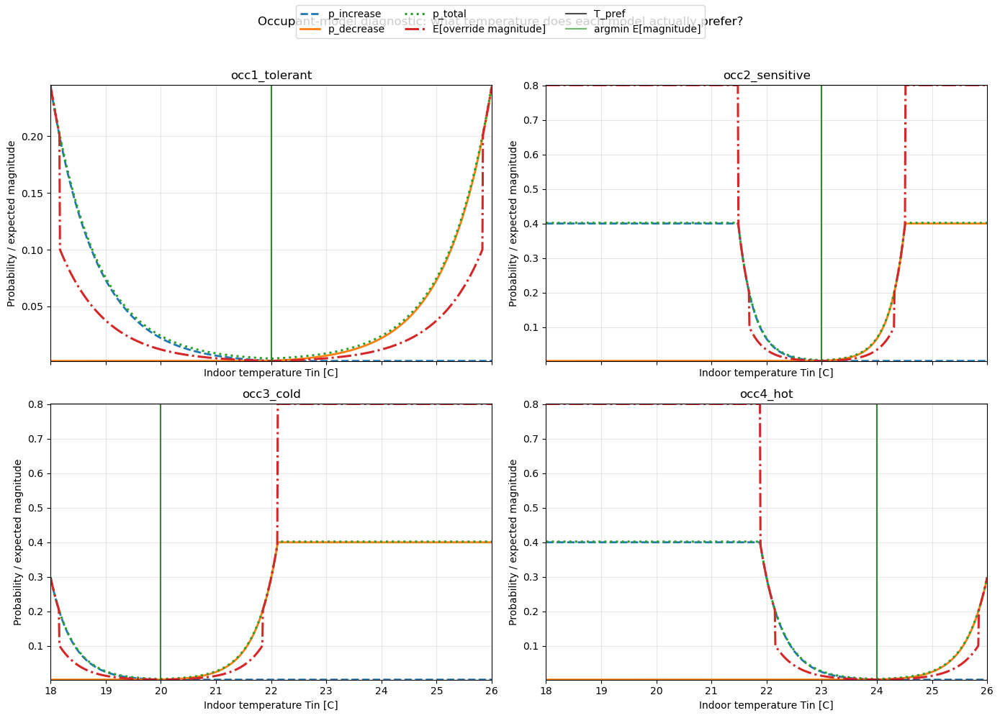

,occupant,T_pref,b,max_prob,min_total_override_prob_temp,min_total_override_prob,min_expected_override_mag_temp,min_expected_override_mag
0,occ1_tolerant,22.0,1.2,0.4,22.0,0.004,22.0,0.002
1,occ2_sensitive,23.0,3.5,0.4,23.0,0.004,23.0,0.002
2,occ3_cold,20.0,2.5,0.4,20.0,0.004,20.0,0.002
3,occ4_hot,24.0,2.5,0.4,24.0,0.004,24.0,0.002


In [71]:
# T_pref diagnostic.
# Visualize what the current occupant model actually prefers as a function of indoor temperature.


def occupant_expected_override_magnitude(occupant, Tin):
    p_inc = occupant.prob_increase(Tin)
    p_dec = occupant.prob_decrease(Tin)
    return (
        p_inc * occupant.override_delta(p_inc)
        + p_dec * occupant.override_delta(p_dec)
    )


def occupant_total_override_probability(occupant, Tin):
    return occupant.prob_increase(Tin) + occupant.prob_decrease(Tin)


T_DIAG_GRID = np.linspace(18.0, 26.0, 801)

fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True, sharey=False)
axes = axes.ravel()

diagnostic_rows = []

for ax, (name, occ) in zip(axes, occupants.items()):
    p_inc = np.array([occ.prob_increase(T) for T in T_DIAG_GRID])
    p_dec = np.array([occ.prob_decrease(T) for T in T_DIAG_GRID])
    p_tot = p_inc + p_dec
    exp_mag = np.array([occupant_expected_override_magnitude(occ, T) for T in T_DIAG_GRID])

    best_prob_ix = int(np.argmin(p_tot))
    best_mag_ix = int(np.argmin(exp_mag))
    best_prob_T = float(T_DIAG_GRID[best_prob_ix])
    best_mag_T = float(T_DIAG_GRID[best_mag_ix])

    diagnostic_rows.append({
        'occupant': name,
        'T_pref': float(occ.T_pref),
        'b': float(occ.b),
        'max_prob': float(occ.max_prob),
        'min_total_override_prob_temp': best_prob_T,
        'min_total_override_prob': float(p_tot[best_prob_ix]),
        'min_expected_override_mag_temp': best_mag_T,
        'min_expected_override_mag': float(exp_mag[best_mag_ix]),
    })

    ax.plot(T_DIAG_GRID, p_inc, '--', label='p_increase', linewidth=2)
    ax.plot(T_DIAG_GRID, p_dec, '-', label='p_decrease', linewidth=2)
    ax.plot(T_DIAG_GRID, p_tot, ':', label='p_total', linewidth=2.2)
    ax.plot(T_DIAG_GRID, exp_mag, '-.', label='E[override magnitude]', linewidth=2.2)
    ax.axvline(float(occ.T_pref), color='black', alpha=0.7, linewidth=1.5, label='T_pref')
    ax.axvline(best_mag_T, color='tab:green', alpha=0.7, linewidth=1.5, label='argmin E[magnitude]')
    ax.set_title(name)
    ax.set_xlabel('Indoor temperature Tin [C]')
    ax.set_ylabel('Probability / expected magnitude')
    ax.grid(True, alpha=0.3)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=3)
fig.suptitle('Occupant-model diagnostic: what temperature does each model actually prefer?')
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

occupant_pref_diagnostic = pd.DataFrame(diagnostic_rows)
display(occupant_pref_diagnostic)


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

This is Ipopt version 3.14.11, running with linear solver MUMPS 5.4.1.

Number of nonzeros in equality constraint Jacobian...:       73
Number of nonzeros in inequality constraint Jacobian.:       96
Number of nonzeros in Lagrangian Hessian.............:       49

Total number of variables............................:       97
                     variables with only lower bounds:       48
                variables with lower and upper bounds:       24
                     variables with only upper bounds:        0
Total number of equality constraints.................:       25
Total number of inequality constraints...............:       48
        inequality constraints with only lower bounds:        0
   inequality constraints with lower and upper bounds:        0
        inequality constraints with only upper bounds:       48

iter    objective    inf_pr   inf_du lg(mu)  ||d||  lg(rg) alpha_du alpha_pr  ls
   0  3.3159729e+04 1.89e+01 6.14e+01  -1.0 0.00e+00    -  0.00e+00 0.00e+00 

,cost_function,value
0,all_time_peak_average,1.028657
1,annual_normalized_unserved_energy_total,0.000000
2,carbon_emissions_total,NaN
3,cost_total,NaN
4,daily_one_minus_load_factor_average,0.986677
5,daily_peak_average,1.000758
6,discomfort_cold_delta_average,0.346704
7,discomfort_cold_delta_maximum,3.265820
8,discomfort_cold_delta_minimum,0.000000
9,discomfort_cold_proportion,0.030683


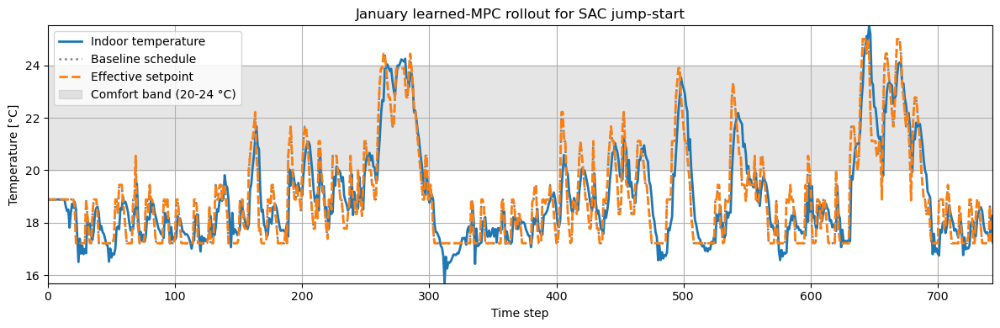

In [72]:
# January learned-MPC rollout -> SAC jump-start dataset
JAN_START_MPC = 0
JAN_END_MPC = int(np.load("january_pi_dataset.npz")["states"].shape[0])
JANUARY_MPC_DATASET_PATH = NOTEBOOK_DIR / "january_mpc_dataset_comfort_raw.npz"

class LearnedRCMPCPolicy:
    def __init__(
        self,
        env,
        objective_mode="baseline",
        fixed_band=None,
        w_energy=1.0,
        w_comfort=1.0,
        lambda_u=1e-3,
        lambda_du=0.0,
        use_smooth_du=False,
        cold_penalty=1e5,
        hot_penalty=1e3,
    ):
        self.env = env
        self.objective_mode = objective_mode
        self.fixed_band = fixed_band
        self.w_energy = w_energy
        self.w_comfort = w_comfort
        self.lambda_u = lambda_u
        self.lambda_du = lambda_du
        self.use_smooth_du = use_smooth_du
        self.cold_penalty = cold_penalty
        self.hot_penalty = hot_penalty
        self._build_mpc()
        self.reset()

    def _build_mpc(self):
        model = do_mpc.model.Model('discrete')

        Tin_m = model.set_variable('_x', 'Tin')
        if self.use_smooth_du:
            model.set_variable('_x', 'u_prev')

        u_m = model.set_variable('_u', 'u')

        Tout_m = model.set_variable('_tvp', 'Tout')
        Sol_m = model.set_variable('_tvp', 'Sol')
        Price_m = model.set_variable('_tvp', 'Price')
        Tsp_m = model.set_variable('_tvp', 'Tsp')
        Tmin_m = model.set_variable('_tvp', 'Tmin')
        Tmax_m = model.set_variable('_tvp', 'Tmax')
        w_est = model.set_variable('_tvp', 'w_est')

        COP_expr = cop_a + cop_b * Tout_m
        COP_expr = ca.fmin(ca.fmax(COP_expr, 0.5), 6.0)

        Tin_next_m = (
            A * Tin_m
            + Bd0 * Tm
            + Bd1 * Tout_m
            + Bd2 * Sol_m
            + Bu * COP_expr * u_m
            + w_est
        )

        model.set_rhs('Tin', Tin_next_m)
        if self.use_smooth_du:
            model.set_rhs('u_prev', u_m)
        model.setup()

        mpc = do_mpc.controller.MPC(model)
        setup_mpc = {
            'n_horizon': 24,
            't_step': 1.0,
            'state_discretization': 'discrete',
            'store_full_solution': True,
        }
        mpc.set_param(**setup_mpc)

        if self.objective_mode == "baseline":
            Tref = Tmin_m
            stage_cost = (Tin_m - Tref) ** 2 + self.lambda_u * u_m ** 2
            terminal_cost = (Tin_m - Tref) ** 2
        elif self.objective_mode == "energy_comfort":
            energy_cost = Price_m * power_per_unit_u * u_m
            comfort_cost = (Tin_m - Tsp_m) ** 2
            smooth_cost = self.lambda_u * u_m ** 2
            if self.use_smooth_du:
                u_prev_m = model.x['u_prev']
                smooth_cost = smooth_cost + self.lambda_du * (u_m - u_prev_m) ** 2
            stage_cost = self.w_energy * energy_cost + self.w_comfort * comfort_cost + smooth_cost
            terminal_cost = self.w_comfort * comfort_cost
        else:
            raise ValueError(f"Unknown objective_mode: {self.objective_mode}")

        if self.objective_mode == "baseline" and self.use_smooth_du:
            u_prev_m = model.x['u_prev']
            stage_cost = stage_cost + self.lambda_du * (u_m - u_prev_m) ** 2

        mpc.set_objective(mterm=terminal_cost, lterm=stage_cost)
        mpc.bounds['lower', '_u', 'u'] = 0.0
        mpc.bounds['upper', '_u', 'u'] = 1.0

        mpc.set_nl_cons(
            'too_cold',
            Tmin_m - Tin_m,
            ub=0.0,
            soft_constraint=True,
            penalty_term_cons=self.cold_penalty,
        )
        mpc.set_nl_cons(
            'too_hot',
            Tin_m - Tmax_m,
            ub=0.0,
            soft_constraint=True,
            penalty_term_cons=self.hot_penalty,
        )

        N = setup_mpc['n_horizon']
        tvp_template = mpc.get_tvp_template()
        self._latest = dict(
            Tout0=0.0,
            Sol0=0.0,
            Price0=0.0,
            Tsp0=20.0,
            Toutp=[0.0, 0.0, 0.0],
            Solp=[0.0, 0.0, 0.0],
            Pricep=[0.0, 0.0, 0.0],
            Tspp=[20.0, 20.0, 20.0],
            Tmin0=18.0,
            Tmax0=24.0,
            w_est=0.0,
        )

        def tvp_fun(t_now):
            for k in range(N + 1):
                if k == 0:
                    Tout_f = self._latest['Tout0']
                    Sol_f = self._latest['Sol0']
                    Price_f = self._latest['Price0']
                    Tsp_f = self._latest['Tsp0']
                elif k <= 3:
                    Tout_f = self._latest['Toutp'][k - 1]
                    Sol_f = self._latest['Solp'][k - 1]
                    Price_f = self._latest['Pricep'][k - 1]
                    Tsp_f = self._latest['Tspp'][k - 1]
                else:
                    Tout_f = self._latest['Toutp'][-1]
                    Sol_f = self._latest['Solp'][-1]
                    Price_f = self._latest['Pricep'][-1]
                    Tsp_f = self._latest['Tspp'][-1]

                tvp_template['_tvp', k, 'Tout'] = float(Tout_f)
                tvp_template['_tvp', k, 'Sol'] = float(Sol_f)
                tvp_template['_tvp', k, 'Price'] = float(Price_f)
                tvp_template['_tvp', k, 'Tsp'] = float(Tsp_f)
                tvp_template['_tvp', k, 'Tmin'] = float(self._latest['Tmin0'])
                tvp_template['_tvp', k, 'Tmax'] = float(self._latest['Tmax0'])
                tvp_template['_tvp', k, 'w_est'] = float(self._latest['w_est'])

            return tvp_template

        mpc.set_tvp_fun(tvp_fun)
        mpc.setup()
        self.mpc = mpc

    def reset(self):
        self.mpc.reset_history()
        self.w_est_val = 0.0
        self.gamma_w = 0.2
        self.prev_Tin = None
        self.prev_u = None
        self.prev_Tout = None
        self.prev_Sol = None
        self.last_u = 0.0

    def predict(self, obs):
        o = np.asarray(obs[0] if isinstance(obs, (list, tuple)) else obs, dtype=np.float32).reshape(-1)
        building = self.env.unwrapped.buildings[0]

        Tin0 = float(o[i_tin])
        Tout0 = float(o[i_tout])
        Sol0 = float(o[i_sol])
        time_step = building.time_step
        Price0 = float(building.pricing.electricity_pricing[time_step])
        scheduled_setpoints = building.energy_simulation.indoor_dry_bulb_temperature_heating_set_point_without_control
        Tsp0 = float(scheduled_setpoints[time_step])

        Toutp = [float(o[j]) for j in i_tout_p]
        Solp = [float(o[j]) for j in i_sol_p]
        Pricep = [
            float(building.pricing.electricity_pricing_predicted_1[time_step]),
            float(building.pricing.electricity_pricing_predicted_2[time_step]),
            float(building.pricing.electricity_pricing_predicted_3[time_step]),
        ]
        Tspp = [
            float(scheduled_setpoints[min(time_step + h, len(scheduled_setpoints) - 1)])
            for h in [1, 2, 3]
        ]

        if self.fixed_band is None:
            Tmin0 = float(o[i_tmin])
            Tmax0 = float(o[i_tmax])
        else:
            Tmin0, Tmax0 = map(float, self.fixed_band)

        if self.prev_Tin is not None:
            cop_prev = np.clip(cop_a + cop_b * self.prev_Tout, 0.5, 6.0)
            Tin_pred = (
                A * self.prev_Tin
                + Bd0 * Tm
                + Bd1 * self.prev_Tout
                + Bd2 * self.prev_Sol
                + Bu * cop_prev * self.prev_u
                + self.w_est_val
            )
            err = Tin0 - Tin_pred
            self.w_est_val = self.w_est_val + self.gamma_w * err

        self._latest.update(dict(
            Tout0=Tout0,
            Sol0=Sol0,
            Price0=Price0,
            Tsp0=Tsp0,
            Toutp=Toutp,
            Solp=Solp,
            Pricep=Pricep,
            Tspp=Tspp,
            Tmin0=Tmin0,
            Tmax0=Tmax0,
            w_est=self.w_est_val,
        ))

        if self.use_smooth_du:
            x0 = np.array([[Tin0], [self.last_u]])
        else:
            x0 = np.array([[Tin0]])

        u0 = float(self.mpc.make_step(x0))

        self.prev_Tin = Tin0
        self.prev_u = u0
        self.prev_Tout = Tout0
        self.prev_Sol = Sol0
        self.last_u = u0

        return [[u0]]

january_mpc_env = make_env(
    reward_function=ComfortReward,
    simulation_start_time_step=JAN_START_MPC,
    simulation_end_time_step=JAN_END_MPC,
)

january_mpc_controller = LearnedRCMPCPolicy(
    january_mpc_env,
    objective_mode="baseline",
    fixed_band=None,
    lambda_u=1e-3,
    lambda_du=0.0,
    use_smooth_du=False,
    cold_penalty=1e5,
    hot_penalty=1e3,
)
january_mpc_controller.reset()

january_mpc_env, january_mpc_dataset = collect_trajectories(
    january_mpc_env,
    january_mpc_controller,
    save_path=str(JANUARY_MPC_DATASET_PATH),
)

january_mpc_kpis = january_mpc_env.unwrapped.evaluate().copy()
january_mpc_district_kpis = january_mpc_kpis[january_mpc_kpis["level"] == "district"].copy()

print("January learned-MPC jump-start dataset saved to:", JANUARY_MPC_DATASET_PATH)
print("Collected MPC transitions:", len(january_mpc_dataset["states"]))
display(january_mpc_district_kpis[["cost_function", "value"]].reset_index(drop=True))
plot_comfort_with_setpoints(
    january_mpc_env,
    building_idx=0,
    title="January learned-MPC rollout for SAC jump-start",
)


# Energy-cost + comfort MPC


In [ ]:
NEW_MPC_CONFIG = dict(
    controller_name="Energy-cost + comfort MPC",
    objective_mode="energy_comfort",
    fixed_band=(18.0, 22.0),
    w_energy=1.0,
    w_comfort=25.0,
    lambda_u=1e-3,
    lambda_du=5e-2,
    use_smooth_du=True,
    cold_penalty=1e5,
    hot_penalty=1e5,
)

new_results = run_february_mpc(**NEW_MPC_CONFIG)


/home/kostas/anaconda3/lib/python3.12/site-packages/do_mpc/controller/_mpc.py:894: UserWarning: rterm was not set and defaults to zero. Changes in the control inputs are not penalized. Can lead to oscillatory behavior.
  warnings.warn('rterm was not set and defaults to zero. Changes in the control inputs are not penalized. Can lead to oscillatory behavior.')
/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded 

This is Ipopt version 3.14.11, running with linear solver MUMPS 5.4.1.

Number of nonzeros in equality constraint Jacobian...:      122
Number of nonzeros in inequality constraint Jacobian.:       96
Number of nonzeros in Lagrangian Hessian.............:       72

Total number of variables............................:      122
                     variables with only lower bounds:       48
                variables with lower and upper bounds:       24
                     variables with only upper bounds:        0
Total number of equality constraints.................:       50
Total number of inequality constraints...............:       48
        inequality constraints with only lower bounds:        0
   inequality constraints with lower and upper bounds:        0
        inequality constraints with only upper bounds:       48

iter    objective    inf_pr   inf_du lg(mu)  ||d||  lg(rg) alpha_du alpha_pr  ls
   0  2.8799973e+04 1.72e+01 5.90e+01  -1.0 0.00e+00    -  0.00e+00 0.00e+00 

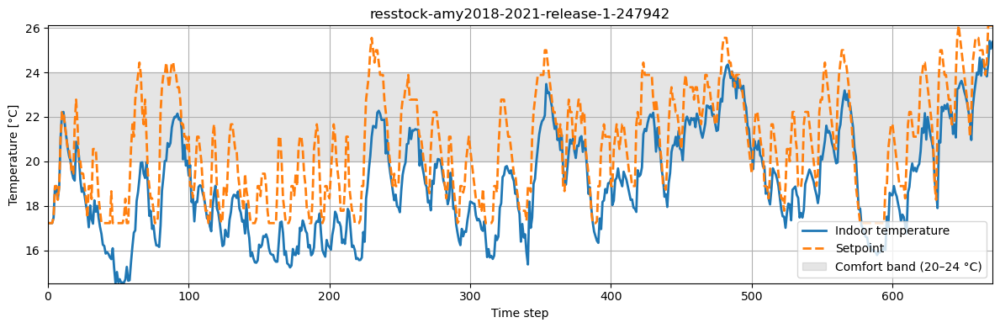

In [ ]:
comparison = (
    baseline_results["district_kpis"][["cost_function", "value"]]
    .rename(columns={"value": "current_mpc"})
    .merge(
        new_results["district_kpis"][["cost_function", "value"]].rename(columns={"value": "energy_cost_comfort_mpc"}),
        on="cost_function",
        how="outer",
    )
)
comparison["delta"] = comparison["energy_cost_comfort_mpc"] - comparison["current_mpc"]
display(comparison.sort_values("cost_function").reset_index(drop=True))


In [ ]:
print("Current MPC full KPI table")
display(baseline_results["kpis"].reset_index(drop=True))

print("Energy-cost + comfort MPC full KPI table")
display(new_results["kpis"].reset_index(drop=True))


                                    cost_function     value  \
0                           all_time_peak_average  0.939643   
1         annual_normalized_unserved_energy_total  0.000000   
2                          carbon_emissions_total       NaN   
3                                      cost_total       NaN   
4             daily_one_minus_load_factor_average  1.028271   
5                              daily_peak_average  0.973038   
6                   discomfort_cold_delta_average  1.562967   
7                   discomfort_cold_delta_maximum  5.268160   
8                   discomfort_cold_delta_minimum  0.000000   
9                      discomfort_cold_proportion  0.338931   
10                   discomfort_hot_delta_average  0.027016   
11                   discomfort_hot_delta_maximum  1.320217   
12                   discomfort_hot_delta_minimum  0.000000   
13                      discomfort_hot_proportion  0.000000   
14                          discomfort_proportion  0.33

In [ ]:
Tin = X[:, i_tin].copy()
Tin_next = Xp[:, i_tin].copy()

# Mask physically impossible spikes (tune threshold if needed)
bad = (Tin < 5.0) | (Tin_next < 14.0) | ~np.isfinite(Tin) | ~np.isfinite(Tin_next)
print("Bad samples:", bad.sum(), "/", len(bad))

# Keep only good samples for identification
good = ~bad


Bad samples: 7 / 743


# 2R2C

In [ ]:
import numpy as np
from scipy.optimize import minimize
import casadi as ca
import do_mpc
import matplotlib.pyplot as plt

# ============================================================
# A) LOAD JANUARY DATASET (generated with PI controller)
# ============================================================
data = np.load("january_pi_dataset.npz")

X  = data["states"]       # (T, 1, obs_dim) for 1 building
U  = data["actions"]      # (T, 1, 1) typically
Xp = data["next_states"]  # (T, 1, obs_dim)

# squeeze building dimension
if X.ndim == 3:
    X  = X[:, 0, :]
    Xp = Xp[:, 0, :]

U = np.array(U)
if U.ndim == 3:
    u_data = U[:, 0, 0]
elif U.ndim == 2:
    u_data = U[:, 0]
else:
    u_data = U

print("X:", X.shape, "Xp:", Xp.shape, "u_data:", u_data.shape)

# ============================================================
# B) OBSERVATION INDICES (requires env exists)
# ============================================================
obs_names = env.buildings[0].active_observations
def idx(name): return obs_names.index(name)

i_tin  = idx("indoor_dry_bulb_temperature")
i_tout = idx("outdoor_dry_bulb_temperature")
i_sol  = idx("direct_solar_irradiance")

# for MPC later (forecasts + comfort)
i_tout_p = [idx(f"outdoor_dry_bulb_temperature_predicted_{h}") for h in [1,2,3]]
i_sol_p  = [idx(f"direct_solar_irradiance_predicted_{h}") for h in [1,2,3]]
i_tmin   = idx("indoor_dry_bulb_temperature_heating_set_point")
i_tmax   = idx("indoor_dry_bulb_temperature_cooling_set_point")

# ============================================================
# C) PREPARE DATA FOR 2R2C IDENTIFICATION (JANUARY)
# ============================================================
Ta_meas = X[:, i_tin].astype(float)
To      = X[:, i_tout].astype(float)
Irr     = X[:, i_sol].astype(float)
u_data  = u_data.astype(float)

# mask obvious bad samples (tune threshold if needed)
bad = (~np.isfinite(Ta_meas) | ~np.isfinite(To) | ~np.isfinite(Irr) | ~np.isfinite(u_data))
# optional mild physical sanity check (avoid near-freezing artifacts)
bad |= (Ta_meas < 10.0)  # change to 5.0 if you want less aggressive

good = ~bad
print("Bad samples:", bad.sum(), "/", len(bad))

Ta_meas = Ta_meas[good]
To      = To[good]
Irr     = Irr[good]
u_data  = u_data[good]

# ============================================================
# D) 2R2C KF-MLE FIT (hidden Tm)
# ============================================================
dt = 3600.0  # 1 hour

def discretize_2r2c(params):
    # params: Ram, Rao, Ca, Cm, ku, ks, k0
    Ram, Rao, Ca, Cm, ku, ks, k0 = params

    Ac = np.array([
        [-(1/(Ca*Ram) + 1/(Ca*Rao)),  1/(Ca*Ram)],
        [ 1/(Cm*Ram),                -1/(Cm*Ram)]
    ], dtype=float)

    Bc = np.array([
        [1/(Ca*Rao),  ks/Ca,  ku/Ca,  k0/Ca],
        [0.0,         0.0,    0.0,    0.0]
    ], dtype=float)

    # Euler discretization
    A = np.eye(2) + dt*Ac
    B = dt*Bc  # multiplies [To, Irr, u, 1]
    return A, B

def kf_negloglik(theta_log):
    # theta_log = [logRam, logRao, logCa, logCm, logku, logks, k0, logq1, logq2, logr]
    logRam, logRao, logCa, logCm, logku, logks, k0, logq1, logq2, logr = theta_log

    Ram = np.exp(logRam)
    Rao = np.exp(logRao)
    Ca  = np.exp(logCa)
    Cm  = np.exp(logCm)
    ku  = np.exp(logku)
    ks  = np.exp(logks)

    q1 = np.exp(logq1)
    q2 = np.exp(logq2)
    r  = np.exp(logr)

    # basic guardrails to avoid numerical blow-ups
    if Ca < 1e3 or Cm < 1e3 or Ram < 1e-6 or Rao < 1e-6:
        return 1e50

    A, B = discretize_2r2c([Ram, Rao, Ca, Cm, ku, ks, k0])

    H = np.array([[1.0, 0.0]], dtype=float)
    Q = np.diag([q1, q2]).astype(float)
    R = np.array([[r]], dtype=float)

    x = np.array([Ta_meas[0], Ta_meas[0]], dtype=float)
    P = np.eye(2) * 10.0

    nll = 0.0
    for k in range(len(Ta_meas)):
        uk = np.array([To[k], Irr[k], u_data[k], 1.0], dtype=float)

        # Predict
        x = A @ x + B @ uk
        P = A @ P @ A.T + Q

        # Update
        y = float(Ta_meas[k])
        S = float(H @ P @ H.T + R)   # scalar
        e = y - float(H @ x)         # scalar

        # NLL
        nll += 0.5*(np.log(2*np.pi*S) + (e*e)/S)

        # Kalman gain
        K = (P @ H.T) / S  # (2,1)
        x = x + (K[:, 0] * e)
        P = (np.eye(2) - K @ H) @ P

    return float(nll)

theta0 = np.array([
    np.log(2.0),     # Ram
    np.log(5.0),     # Rao
    np.log(1e6),     # Ca
    np.log(5e6),     # Cm
    np.log(5.0),     # ku
    np.log(1e-2),    # ks
    0.0,             # k0
    np.log(1e-3),    # q1
    np.log(1e-3),    # q2
    np.log(1e-1),    # r
], dtype=float)

res = minimize(kf_negloglik, theta0, method="L-BFGS-B")
print("KF-MLE success:", res.success, "|", res.message)

logRam, logRao, logCa, logCm, logku, logks, k0, logq1, logq2, logr = res.x
params_fit = dict(
    Ram=float(np.exp(logRam)),
    Rao=float(np.exp(logRao)),
    Ca=float(np.exp(logCa)),
    Cm=float(np.exp(logCm)),
    ku=float(np.exp(logku)),
    ks=float(np.exp(logks)),
    k0=float(k0),
    q1=float(np.exp(logq1)),
    q2=float(np.exp(logq2)),
    r=float(np.exp(logr)),
)
print("Fitted params:", params_fit)

def kf_filter(params_fit):
    A, B = discretize_2r2c([params_fit["Ram"], params_fit["Rao"], params_fit["Ca"], params_fit["Cm"],
                            params_fit["ku"], params_fit["ks"], params_fit["k0"]])
    H = np.array([[1.0, 0.0]])
    Q = np.diag([params_fit["q1"], params_fit["q2"]])
    R = np.array([[params_fit["r"]]])

    x = np.array([Ta_meas[0], Ta_meas[0]], dtype=float)
    P = np.eye(2) * 10.0

    Ta_pred = np.zeros_like(Ta_meas)
    Tm_est  = np.zeros_like(Ta_meas)

    for k in range(len(Ta_meas)):
        uk = np.array([To[k], Irr[k], u_data[k], 1.0], dtype=float)

        # predict
        x = A @ x + B @ uk
        P = A @ P @ A.T + Q
        Ta_pred[k] = x[0]

        # update
        y = float(Ta_meas[k])
        S = float(H @ P @ H.T + R)
        e = y - float(H @ x)
        K = (P @ H.T) / S
        x = x + (K[:,0] * e)
        P = (np.eye(2) - K @ H) @ P

        Tm_est[k] = x[1]

    return Ta_pred, Tm_est

Ta_pred, Tm_est = kf_filter(params_fit)
rmse = np.sqrt(np.mean((Ta_pred - Ta_meas)**2))
print("2R2C KF 1-step RMSE (Jan filtered):", rmse)

# ============================================================
# E) BUILD 2R2C MPC (comfort-first, asymmetric slacks, optional Δu)
# ============================================================
USE_SMOOTH_DU = True

model = do_mpc.model.Model('discrete')

Ta = model.set_variable('_x', 'Ta')  # indoor air temp
Tm = model.set_variable('_x', 'Tm')  # thermal mass (hidden)

if USE_SMOOTH_DU:
    u_prev = model.set_variable('_x', 'u_prev')

u_ctrl = model.set_variable('_u', 'u')  # control in [0,1]

# TVPs
Tout_tvp = model.set_variable('_tvp','Tout')
Irr_tvp  = model.set_variable('_tvp','Irr')
Tmin_tvp = model.set_variable('_tvp','Tmin')
Tmax_tvp = model.set_variable('_tvp','Tmax')

# Discrete matrices from fitted physical params (Euler)
A_d, B_d = discretize_2r2c([params_fit["Ram"], params_fit["Rao"], params_fit["Ca"], params_fit["Cm"],
                            params_fit["ku"], params_fit["ks"], params_fit["k0"]])

# dynamics: x_{k+1} = A x + B [Tout, Irr, u, 1]
x_vec = ca.vertcat(Ta, Tm)
d_vec = ca.vertcat(Tout_tvp, Irr_tvp, u_ctrl, 1.0)

x_next = ca.DM(A_d) @ x_vec + ca.DM(B_d) @ d_vec
model.set_rhs('Ta', x_next[0])
model.set_rhs('Tm', x_next[1])

if USE_SMOOTH_DU:
    model.set_rhs('u_prev', u_ctrl)

model.setup()

mpc = do_mpc.controller.MPC(model)
setup_mpc = dict(n_horizon=24, t_step=1.0, state_discretization='discrete', store_full_solution=True)
mpc.set_param(**setup_mpc)

# Objective: comfort-first -> only energy + optional smoothness
lambda_u  = 0.05
lambda_du = 0.5

if USE_SMOOTH_DU:
    mpc.set_objective(mterm=0*Ta, lterm=lambda_u*u_ctrl**2 + lambda_du*(u_ctrl - u_prev)**2)
else:
    mpc.set_objective(mterm=0*Ta, lterm=lambda_u*u_ctrl**2)

mpc.bounds['lower','_u','u'] = 0.0
mpc.bounds['upper','_u','u'] = 1.0

# asymmetric soft comfort
w_cold = 2e4
w_hot  = 1e5
mpc.set_nl_cons('too_cold', Tmin_tvp - Ta, ub=0.0, soft_constraint=True, penalty_term_cons=w_cold)
mpc.set_nl_cons('too_hot',  Ta - Tmax_tvp, ub=0.0, soft_constraint=True, penalty_term_cons=w_hot)

# TVP function (forecasts)
N = setup_mpc['n_horizon']
tvp_template = mpc.get_tvp_template()

_latest = dict(
    Tout0=0.0, Irr0=0.0,
    Toutp=[0.0,0.0,0.0], Irrp=[0.0,0.0,0.0],
    Tmin0=18.0, Tmax0=24.0
)

def tvp_fun(t_now):
    Tout0 = _latest["Tout0"]
    Irr0  = _latest["Irr0"]
    Toutp = _latest["Toutp"]
    Irrp  = _latest["Irrp"]
    Tmin0 = _latest["Tmin0"]
    Tmax0 = _latest["Tmax0"]

    for k in range(N+1):
        if k == 0:
            Tout_f, Irr_f = Tout0, Irr0
        elif k <= 3:
            Tout_f, Irr_f = Toutp[k-1], Irrp[k-1]
        else:
            Tout_f, Irr_f = Toutp[-1], Irrp[-1]

        tvp_template['_tvp', k, 'Tout'] = float(Tout_f)
        tvp_template['_tvp', k, 'Irr']  = float(Irr_f)
        tvp_template['_tvp', k, 'Tmin'] = float(Tmin0)
        tvp_template['_tvp', k, 'Tmax'] = float(Tmax0)

    return tvp_template

mpc.set_tvp_fun(tvp_fun)
mpc.setup()

# ============================================================
# F) ONLINE KF ESTIMATOR (for hidden Tm) DURING MPC RUN
# ============================================================
A_kf, B_kf = A_d, B_d
H_kf = np.array([[1.0, 0.0]])
Q_kf = np.diag([params_fit["q1"], params_fit["q2"]])
R_kf = np.array([[params_fit["r"]]])

def kf_step(x, P, Ta_measured, Tout, Irr, u_applied):
    uk = np.array([Tout, Irr, u_applied, 1.0], dtype=float)

    # predict
    x_pred = A_kf @ x + B_kf @ uk
    P_pred = A_kf @ P @ A_kf.T + Q_kf

    # update
    y = float(Ta_measured)
    S = float(H_kf @ P_pred @ H_kf.T + R_kf)
    e = y - float(H_kf @ x_pred)
    K = (P_pred @ H_kf.T) / S

    x_upd = x_pred + (K[:,0] * e)
    P_upd = (np.eye(2) - K @ H_kf) @ P_pred
    return x_upd, P_upd

# ============================================================
# G) RUN 2R2C MPC ON FEBRUARY
# ============================================================
SIMULATION_START_TIME_STEP = 744
SIMULATION_END_TIME_STEP   = 1415

env_feb = make_env(
    simulation_start_time_step=SIMULATION_START_TIME_STEP,
    simulation_end_time_step=SIMULATION_END_TIME_STEP
)

obs, info = env_feb.reset()
mpc.reset_history()

Ta_hist, Tmin_hist, Tmax_hist, u_hist = [], [], [], []

# KF init
o0 = obs[0] if isinstance(obs, (list, tuple)) else obs
Ta0 = float(o0[i_tin])
x_kf = np.array([Ta0, Ta0], dtype=float)
P_kf = np.eye(2) * 10.0

last_u = 0.0
terminated = truncated = False

while not (terminated or truncated):

    o = obs[0] if isinstance(obs, (list, tuple)) else obs

    Ta_meas_now = float(o[i_tin])
    Tout_now    = float(o[i_tout])
    Irr_now     = float(o[i_sol])

    # forecasts (1..3)
    Toutp = [float(o[j]) for j in i_tout_p]
    Irrp  = [float(o[j]) for j in i_sol_p]

    Tmin0 = float(o[i_tmin])
    Tmax0 = float(o[i_tmax])

    # update TVPs for MPC
    _latest.update(dict(
        Tout0=Tout_now, Irr0=Irr_now,
        Toutp=Toutp, Irrp=Irrp,
        Tmin0=Tmin0, Tmax0=Tmax0
    ))

    # KF update using last applied u (important!)
    # Optional: if Ta_meas_now is an outlier, skip update:
    if Ta_meas_now < 10.0 or not np.isfinite(Ta_meas_now):
        Ta_meas_now = Ta_hist[-1] if len(Ta_hist) > 0 else Ta_meas_now

    x_kf, P_kf = kf_step(x_kf, P_kf, Ta_meas_now, Tout_now, Irr_now, last_u)

    # MPC initial state uses KF estimate for hidden Tm
    if USE_SMOOTH_DU:
        x0 = np.array([[x_kf[0]], [x_kf[1]], [last_u]])
    else:
        x0 = np.array([[x_kf[0]], [x_kf[1]]])

    u_star = float(mpc.make_step(x0))
    u_star = float(np.clip(u_star, 0.0, 1.0))

    obs, reward, terminated, truncated, info = env_feb.step([[u_star]])
    last_u = u_star

    Ta_hist.append(Ta_meas_now)
    Tmin_hist.append(Tmin0)
    Tmax_hist.append(Tmax0)
    u_hist.append(u_star)

print("Done. February steps:", len(Ta_hist))

# ============================================================
# H) PLOTS
# ============================================================
plt.figure(figsize=(12,4))
plt.plot(Ta_hist, label="Tin (2R2C-MPC)")
plt.plot(Tmin_hist, '--', label="Tmin")
plt.plot(Tmax_hist, '--', label="Tmax")
plt.legend()
plt.title("2R2C MPC — February")
plt.show()

plt.figure(figsize=(12,3))
plt.plot(u_hist, label="u")
plt.ylim(-0.05, 1.05)
plt.legend()
plt.title("Control (heating action)")
plt.show()


X: (743, 28) Xp: (743, 28) u_data: (743,)
Bad samples: 0 / 743
KF-MLE success: True | CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
Fitted params: {'Ram': 2.2582461203005413, 'Rao': 5.264936930372461, 'Ca': 39344.55978961631, 'Cm': 81720677.69899374, 'ku': 10.932790371184472, 'ks': 0.0013159548844071816, 'k0': 2.51743914790028, 'q1': 0.1270460364795372, 'q2': 0.0001519569804635781, 'r': 5.058829314997107}
2R2C KF 1-step RMSE (Jan filtered): 2.3857020860829996


/home/kostas/anaconda3/lib/python3.12/site-packages/do_mpc/controller/_mpc.py:894: UserWarning: rterm was not set and defaults to zero. Changes in the control inputs are not penalized. Can lead to oscillatory behavior.
  warnings.warn('rterm was not set and defaults to zero. Changes in the control inputs are not penalized. Can lead to oscillatory behavior.')
/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded 

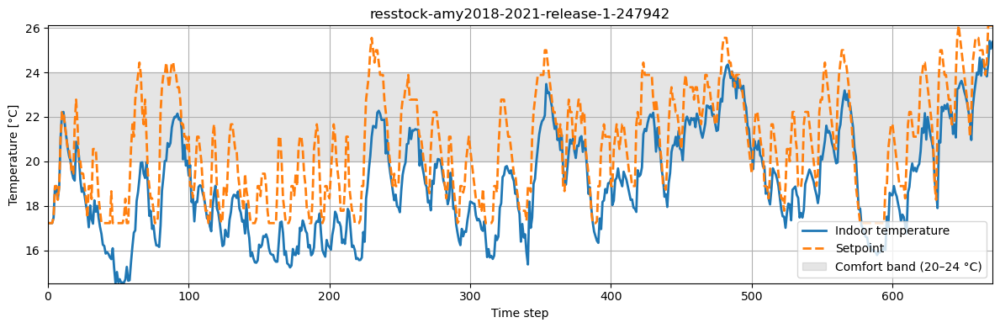

In [ ]:
plot_comfort(env)

In [ ]:
def rollout_2r2c(params_fit, Ta0, To, Irr, u):
    A, B = discretize_2r2c([
        params_fit["Ram"], params_fit["Rao"],
        params_fit["Ca"],  params_fit["Cm"],
        params_fit["ku"],  params_fit["ks"],
        params_fit["k0"]
    ])

    x = np.array([Ta0, Ta0], dtype=float)

    Ta_pred = np.zeros_like(To)

    for k in range(len(To)):
        uk = np.array([To[k], Irr[k], u[k], 1.0])
        x = A @ x + B @ uk
        Ta_pred[k] = x[0]

    return Ta_pred


Ta_roll_2r2c = rollout_2r2c(params_fit, Ta_meas[0], To, Irr, u_data)

rmse_roll_2r2c = np.sqrt(np.mean((Ta_roll_2r2c - Ta_meas)**2))
print("2R2C rollout RMSE (Jan):", rmse_roll_2r2c)


2R2C rollout RMSE (Jan): 2.807031239832704
